# Student-Heavy Rental Corridors in Sydney: What Do New-Lease Rents Show?
### An exploratory analysis of NSW rental bond lodgements, 2018 and 2021–2026

**Location:** Greater Sydney, New South Wales  |  **Tools:** Python · pandas · DuckDB · GeoPandas · Matplotlib · Seaborn · SciPy

---
## Project overview

International education is concentrated around a small number of campuses in inner Sydney. Councils that host those campuses are
asked to say something about student housing, but the evidence they hold is mostly counts of student-accommodation rooms and
anecdotes. This project asks a narrower, data-driven question: **do rents on newly signed leases near campuses behave
differently from rents in comparable flat markets away from campuses, and how sure can we be?**

It is an **exploratory, descriptive analysis**. It does not build a predictive model, and it avoids causal claims that the data cannot support.

## End user and decision

**End user:** a strategic planning / housing policy officer at the City of Sydney (supporting the Housing for All Working Group).
On 20 February 2023 Council unanimously asked its CEO for advice on strategies to address the housing and cost-of-living
pressures faced by students and referred the issue to that working group (Item 13.3, *Affordable Student Accommodation Shortage*).
The 2026 federal settings for international student places also link growth in university allocations to the provision of
student accommodation ([Department of Education](https://www.education.gov.au/managed-system-international-education/2026-managed-growth-settings)).

**Decisions this analysis informs**
1. Which inner-Sydney corridors deserve deeper investigation of student-related rental pressure.
2. How strongly the evidence can be worded in a briefing (a calibrated statement, not an overstated one).
3. What additional data the Council should request (for example, student numbers by suburb).

## Analytical questions

| | Question | Method |
|---|---|---|
| **RQ1 – What happened?** | How did new-lease rents change in each market segment across the phases of student numbers, and is there a seasonal pattern tied to the academic calendar? | Monthly time series, phase tables, detrended seasonal profile |
| **RQ2 – Where?** | Which postcodes and corridors saw faster or slower rent growth? | Choropleth maps, corridor summaries |
| **RQ3 – Association** | Do postcodes with higher exposure to students show different rent growth than comparable low-exposure postcodes? | Tier comparison under two exposure measures, placebo on houses, pre-COVID check, cluster bootstrap, rank correlation |
| **RQ4 – Priority** | Which corridors warrant further investigation, and how much weight can that carry? | Corridor table gated by evidence grade |

## Scope
- **Place:** Greater Sydney (247 postcodes in the 14 "Sydney – …" SA4 regions; Central Coast is excluded).
- **Period:** 2018 (pre-COVID baseline) and January 2021 to September 2026. **2019–2020 bond rows are not available**; DCJ quarterly medians are used to look at those years (6.5).
- **Segments:** studio/1-bedroom flats (`f01`) and 2-bedroom flats (`f2`). 3–4 bedroom houses (`h34`), which students rarely rent, serve as a **placebo** comparison.
- **Phases:** defined from the number of student visa holders **present** in Australia (BP0019). The earlier definition from NSW visas **granted** (BP0015) is kept as a sensitivity check.

## Data sources

| Source | Role | Granularity | Coverage | Notes |
|---|---|---|---|---|
| NSW Fair Trading – Rental bond lodgements | **Outcome:** new-lease weekly rent | One row per bond | 2018; 2021–09/2026 | CC-BY; 2018 file comes from a data.nsw mirror |
| CRICOS (Locations, Courses, Course-Locations, Institutions) | Campus locations and course levels | Course × location | Snapshot 2026-09 | No student numbers |
| Dept of Education – enrolments by SA4 | Student distribution by place of study | SA4 × sector × field | Year to Dec 2025 | Aggregate; counts below 5 suppressed |
| ABS – POA boundaries and correspondences | Geography | Postcode polygons, population-weighted ratios | ASGS Edition 3 | Postcode areas approximate postcodes |
| ABS Census 2021 – tables G01, G15 (G02, G37 for profiles) | **Second exposure measure (E4):** university students living in each postcode | Postcode | Census night, 10 Aug 2021 | Domestic and international students; taken while the border was closed |
| Home Affairs – BP0019 student visa holders present | **Phases** (primary definition) | Quarter-end snapshot × visa | Dec 2011 – Sep 2026 | National only; strongly seasonal |
| Home Affairs – BP0015 student visas granted | Phases (sensitivity check) | Month × state × sector | 2005-06 to 2026-09 | Visas granted, not students present |
| NSW DCJ – Rent tables | **Pre-COVID check** for 2018–2022 | Postcode × dwelling × bedrooms × quarter | 2018Q1 – 2022Q4 | Medians only; cells with ≤10 bonds hidden |
| City of Sydney – Housing Audit | Context: student accommodation rooms | City of Sydney local area, June | 2015 – 2025 | City of Sydney only |

The Census, BP0019, DCJ and Housing Audit tables are written to `processed/extracted/` by `00_data_extraction_overview.ipynb`.
Development applications and Inside Airbnb were examined as context and moved to `appendix_context_da_airbnb.ipynb`, because neither can be
used to test the results (9.3).

## Unit of analysis
- Cleaning and descriptive statistics: **one bond lodgement**.
- Comparisons and tests: **postcode × segment**, using the median new-lease rent in each phase.

## Evidence grading

Because the data are observational and the exposure measure is partly modelled, every association is graded:

| Grade | Rule | Reading |
|---|---|---|
| **A** | In at least 2 of the 3 post-closure windows the 90% cluster-bootstrap interval for the High-minus-Low gap excludes zero; in those windows at least 80% of the other exposure definitions agree in sign, and the sign survives dropping any single neighbourhood cluster in at least 90% of cases | A stable association worth taking forward |
| **B** | At least one window excludes zero and, in the windows that do, at least 60% of the other exposure definitions agree | A signal that depends on the choice of window or definition |
| **C** | Anything else | Cannot be distinguished from the common market trend |

- The grade is computed twice: with tiers drawn from the campus-based measure (E2) and from the Census measure (E4). **The reported grade is the lower of the two.**
  The same grades under the visa-grant phases are shown as a sensitivity check.
- "Other exposure definitions" are the eight definitions in 6.6 minus the one used for the tiers (six campus-based, two Census-based).
- A single window counts as a **finding** only if its interval excludes zero, with the same sign, under both exposure measures and both phase definitions.
- *Revision note.* The rules were fixed before the first results and revised once (5 Nov 2026), after the review of the data decisions: the second
  exposure measure and phase definition were added, and the sign-agreement and leave-one-out checks are now made in the windows where the interval excludes
  zero. In a window without a signal, comparing signs is a coin toss: under the original rule such windows pulled the agreement down to the threshold.
  The grade under the original rule is reported next to the revised one (6.7).

No grade implies causation.

## Contents
1. Setup · 2. Data understanding and quality · 3. Cleaning and preparation · 4. RQ1 (rents over time, seasonality) · 5. RQ2 (where) ·
6. RQ3 (association with exposure, placebo, pre-COVID check, evidence grade) · 7. RQ4 (corridors) · 8. Robustness · 9. Context ·
10. Findings, recommendations and limitations

---
# 1. Setup and data loading

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import geopandas as gpd
from scipy import stats
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the data folder (contains processed/ and raw/) whether the notebook runs from notebooks/ or elsewhere.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "processed").exists())
PROC, RAW = ROOT / "processed", ROOT / "raw"
EXTRACTED = PROC / "extracted"            # tables written by 00_data_extraction_overview.ipynb
SEED = 42

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.spines.top": False,
                     "axes.spines.right": False})

# One colour per exposure group, used consistently in every chart.
COLORS = {"City of Sydney": "#1b4f72", "Comparator – High": "#c0392b", "Comparator – Mid": "#e59866",
          "Comparator – Low": "#7f8c8d"}
TIER_COLORS = {"Low": "#7f8c8d", "Mid": "#e59866", "High": "#c0392b"}

def md(text: str) -> None:
    """Render a string as Markdown (used for findings that embed computed numbers)."""
    display(Markdown(text))

print(f"pandas {pd.__version__} | numpy {np.__version__} | duckdb {duckdb.__version__} | geopandas {gpd.__version__}")
print("Data folder:", ROOT)

pandas 3.1.0 | numpy 2.5.4 | duckdb 2.0.0 | geopandas 1.2.0
Data folder: /home/user/cr_mentor/data


# 2. Data understanding and quality assessment

## 2.1 Rental bond lodgements (the outcome data)

Each row of the Fair Trading files is one bond lodged at the start of a tenancy. The data therefore describe **new leases**
(the market a person moving house meets), not the rents paid by everyone who already rents. The raw table below was built by
stacking 62 monthly and annual workbooks; the 2021 annual file plus the 2022–2026 monthly files are used for analysis
because the annual and monthly files overlap from 2022.

In [2]:
bond_raw = pd.read_parquet(PROC / "bond_lodgements_raw.parquet",
                           columns=["date", "postcode", "dwelling", "bedrooms", "rent", "src_file", "file_kind"])
print(f"Rows: {len(bond_raw):,} | files: {bond_raw.src_file.nunique()} (annual: "
      f"{bond_raw.loc[bond_raw.file_kind == 'annual', 'src_file'].nunique()}, monthly: "
      f"{bond_raw.loc[bond_raw.file_kind == 'monthly', 'src_file'].nunique()})")
bond_raw.head()

Rows: 3,190,534 | files: 62 (annual: 5, monthly: 57)


,date,postcode,dwelling,bedrooms,rent,src_file,file_kind
0,2022-04-22,2000,F,0.00,550.00,Rental-bond-lodgements-April-2022.xlsx,monthly
1,2022-04-19,2000,F,0.00,400.00,Rental-bond-lodgements-April-2022.xlsx,monthly
2,2022-04-19,2000,F,0.00,600.00,Rental-bond-lodgements-April-2022.xlsx,monthly
3,2022-04-01,2000,F,0.00,540.00,Rental-bond-lodgements-April-2022.xlsx,monthly
4,2022-04-04,2000,F,0.00,495.00,Rental-bond-lodgements-April-2022.xlsx,monthly


In [3]:
bond_raw.tail(3)

,date,postcode,dwelling,bedrooms,rent,src_file,file_kind
3190531,2025-01-02,2880,U,NaN,330.00,rentalbond_lodgements_year_2025.xlsx,annual
3190532,2025-01-17,2898,F,3.00,560.00,rentalbond_lodgements_year_2025.xlsx,annual
3190533,2025-12-18,2898,H,3.00,540.00,rentalbond_lodgements_year_2025.xlsx,annual


In [4]:
bond_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 3190534 entries, 0 to 3190533
Data columns (total 7 columns):
 #   Column     Dtype         
---  ------     -----         
 0   date       datetime64[ns]
 1   postcode   int64         
 2   dwelling   str           
 3   bedrooms   float64       
 4   rent       float64       
 5   src_file   str           
 6   file_kind  str           
dtypes: datetime64[ns](1), float64(2), int64(1), str(3)
memory usage: 308.6 MB


**Overlap check.** Annual and monthly files cover the same bonds from 2022. If they agree, using one source avoids double counting.

In [5]:
ov = (bond_raw[bond_raw.date.dt.year.between(2022, 2025)]
      .assign(year=lambda d: d.date.dt.year)
      .groupby(["year", "file_kind"]).size().unstack())
ov["annual / monthly"] = ov["annual"] / ov["monthly"]
ov

file_kind,annual,monthly,annual / monthly
year,,,
2022,330396,330403,1.00
2023,326246,326114,1.00
2024,328183,328183,1.00
2025,322307,322318,1.00


The annual and monthly files hold essentially the same rows, so the analysis set is the **2021 annual file plus the monthly files from January 2022**.

In [6]:
is_2021_annual = (bond_raw.file_kind == "annual") & (bond_raw.date.dt.year == 2021)
is_monthly_2022 = (bond_raw.file_kind == "monthly") & (bond_raw.date >= "2022-01-01")
bond_src = bond_raw[is_2021_annual | is_monthly_2022].copy()
print(f"Analysis set before cleaning: {len(bond_src):,} rows | {bond_src.date.min().date()} to {bond_src.date.max().date()}")

Analysis set before cleaning: 1,883,402 rows | 2021-01-01 to 2026-09-30


**The 2018 file.** The pre-COVID baseline comes from a separate CSV (a data.nsw mirror) with the same five fields. It is read here, so that every quality
check below covers every year used in the analysis. Lines whose date or postcode cannot be read are dropped only if they are completely blank, and the
count is printed.

In [7]:
b18_raw = pd.read_csv(RAW / "nsw_bond_2018" / "rentalbond_lodgements_year_2018.csv", skiprows=3, dtype=str, encoding="utf-8-sig")
b18_raw.columns = ["d", "postcode", "dwelling", "bedrooms", "rent"]
b18 = b18_raw.copy()
b18["date"] = pd.to_datetime(b18["d"], format="%d/%m/%Y", errors="coerce")
for c in ["postcode", "bedrooms", "rent"]:
    b18[c] = pd.to_numeric(b18[c], errors="coerce")          # 'U' (unknown) becomes missing
b18["dwelling"] = b18["dwelling"].str.strip()
unreadable = b18[["date", "postcode"]].isna().any(axis=1)
assert b18_raw[unreadable].isna().all(axis=1).all(), "only completely blank lines may be dropped"
b18 = b18[~unreadable].copy()
text_codes = {c: b18_raw.loc[~unreadable, c][pd.to_numeric(b18_raw.loc[~unreadable, c], errors="coerce").isna()].value_counts().to_dict()
              for c in ["bedrooms", "rent"]}
print(f"2018 file: {len(b18_raw):,} lines read | {int(unreadable.sum())} completely blank line(s) dropped | {len(b18):,} bonds kept")
print("Non-numeric entries, recorded as missing:", text_codes)

2018 file: 331,880 lines read | 1 completely blank line(s) dropped | 331,879 bonds kept
Non-numeric entries, recorded as missing: {'bedrooms': {'U': 26709}, 'rent': {'U': 12664}}


### Missing values, codes and ranges

In [8]:
quality = pd.concat({name: pd.DataFrame({"missing": d[["rent", "bedrooms"]].isna().sum(),
                                         "missing %": (d[["rent", "bedrooms"]].isna().mean() * 100).round(2)})
                     for name, d in [("2021–2026 files", bond_src), ("2018 file", b18)]}, axis=1)
display(quality)
print("Dwelling type codes (2021–2026):\n", bond_src.dwelling.value_counts(dropna=False).to_string())

2021–2026 files           2018 file          
                 missing missing %   missing missing %
rent               28204      1.50     12664      3.82
bedrooms           49638      2.64     26709      8.05

Dwelling type codes (2021–2026):
 dwelling
F    940021
H    708291
T    103598
O     69626
U     61801
1        18
3        14
P         7
G         6
4         6
Y         4
I         3
5         3
Z         2
X         1
R         1


`U` means "unknown" in the source legend (dwelling, bedrooms and rent). A small number of rows carry other codes (`1`, `3`, `P`, `G` …) that the legend does not define; they are treated as invalid.

In [9]:
num = bond_src[["bedrooms", "rent"]].describe(percentiles=[.01, .05, .5, .95, .99])
num

,bedrooms,rent
count,"1,833,764.00","1,855,198.00"
mean,2.33,669.62
std,1.10,358.35
min,0.00,0.00
1%,0.00,200.00
5%,1.00,300.00
50%,2.00,600.00
95%,4.00,"1,250.00"
99%,5.00,"1,900.00"
max,30.00,"10,000.00"


### Missing-value pattern

Before deciding what to do with missing values, look for a pattern: are the two fields missing together, in which dwelling types, and in which years?
`isna().any(axis=1)` flags rows with at least one gap; `isna().all(axis=1)` flags rows where both fields are missing.

,rows,% of all bonds
rent or bedrooms missing (any),81818,3.69
both missing (all),35397,1.60
rent only,5471,0.25
bedrooms only,40950,1.85


,rent_missing,bedrooms_missing,share of all bonds
dwelling,,,
F,0.33,1.24,49.43
H,0.29,1.15,37.27
O,0.74,6.13,3.65
T,0.37,0.94,5.76
U,39.29,54.59,3.89


,rent_missing,bedrooms_missing,dwelling_unknown
year,,,
2018,3.82,8.05,7.33
2021,2.11,3.43,3.58
2022,1.75,3.58,3.07
2023,1.47,2.93,2.48
2024,1.32,2.17,3.07
2025,1.19,1.83,4.29
2026,1.00,1.55,3.18


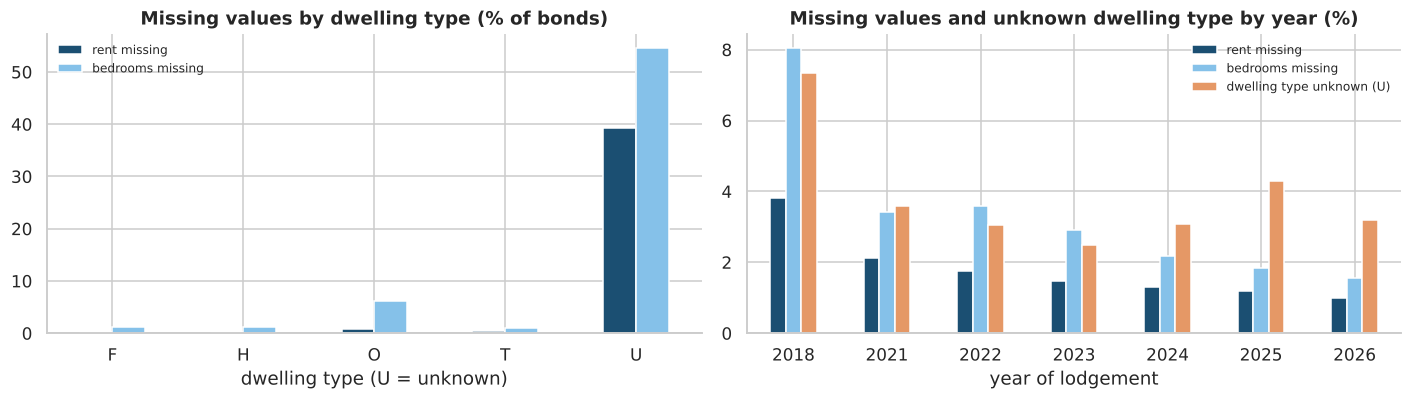

In [10]:
lodg = pd.concat([b18[["date", "postcode", "dwelling", "bedrooms", "rent"]].assign(file="2018 file"),
                  bond_src[["date", "postcode", "dwelling", "bedrooms", "rent"]].assign(file="2021–2026 files")], ignore_index=True)
lodg["year"] = lodg.date.dt.year
gap = lodg[["rent", "bedrooms"]].isna()
valid = lodg.dwelling.isin(list("FHTOU"))

miss_pattern = pd.DataFrame({"rows": [gap.any(axis=1).sum(), gap.all(axis=1).sum(), (gap.rent & ~gap.bedrooms).sum(), (~gap.rent & gap.bedrooms).sum()]},
                            index=["rent or bedrooms missing (any)", "both missing (all)", "rent only", "bedrooms only"])
miss_pattern["% of all bonds"] = (miss_pattern.rows / len(lodg) * 100).round(2)
display(miss_pattern)

by_type = (lodg[valid].assign(rent_missing=gap.rent, bedrooms_missing=gap.bedrooms)
           .groupby("dwelling")[["rent_missing", "bedrooms_missing"]].mean().mul(100))
by_type["share of all bonds"] = lodg[valid].dwelling.value_counts(normalize=True).mul(100)
by_year = (lodg.assign(rent_missing=gap.rent, bedrooms_missing=gap.bedrooms, dwelling_unknown=lodg.dwelling.eq("U"))
           .groupby("year")[["rent_missing", "bedrooms_missing", "dwelling_unknown"]].mean().mul(100))
share_in_U = {f: lodg.loc[gap[f] & valid, "dwelling"].eq("U").mean() for f in ["rent", "bedrooms"]}
display(by_type.round(2), by_year.round(2))

NICE = {"rent_missing": "rent missing", "bedrooms_missing": "bedrooms missing", "dwelling_unknown": "dwelling type unknown (U)"}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
by_type[["rent_missing", "bedrooms_missing"]].rename(columns=NICE).plot.bar(ax=axes[0], color=["#1b4f72", "#85c1e9"], rot=0)
axes[0].set_title("Missing values by dwelling type (% of bonds)"); axes[0].set_xlabel("dwelling type (U = unknown)")
by_year.rename(columns=NICE).plot.bar(ax=axes[1], color=["#1b4f72", "#85c1e9", "#e59866"], rot=0)
axes[1].set_title("Missing values and unknown dwelling type by year (%)"); axes[1].set_xlabel("year of lodgement")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
md(f"""**Reading the pattern.** Gaps cluster in bonds whose dwelling type is also unknown (`U`): {by_type.loc['U', 'rent_missing']:.0f}% of `U` bonds have no rent
and {by_type.loc['U', 'bedrooms_missing']:.0f}% no bedroom count, against {by_type.loc['F', 'rent_missing']:.2f}% and {by_type.loc['F', 'bedrooms_missing']:.2f}% for flats.
`U` bonds are {by_type.loc['U', 'share of all bonds']:.1f}% of all bonds but hold {share_in_U['rent']:.0%} of the missing rents and {share_in_U['bedrooms']:.0%} of the missing
bedroom counts. Gaps also shrink every year (missing rent {by_year.loc[2018, 'rent_missing']:.1f}% in 2018, {by_year.loc[2021, 'rent_missing']:.1f}% in 2021,
{by_year.loc[2026, 'rent_missing']:.1f}% in 2026), and the 2018 file is the least complete ({by_year.loc[2018, 'bedrooms_missing']:.1f}% without bedrooms,
{by_year.loc[2018, 'dwelling_unknown']:.1f}% with an unknown dwelling type).

| Question | Answer for missing rent and bedrooms |
|---|---|
| Is it valid? | Yes as a record: the lodgement happened and the field was entered as `U` ("unknown" in the source legend). In the 2018 file `U` is the only non-numeric entry. |
| Where does it come from? | Data entry at lodgement, not this notebook's processing: it clusters in bonds that also lack a dwelling type, and it falls year after year. |
| What happens if we keep it? | A bond without a rent cannot enter a rent median, and a bond without bedrooms cannot be placed in a segment, so neither can enter any comparison. |
| Can it be fixed? | Filling gaps with a group median would insert the very statistic being measured (the postcode-segment median): the median would not move, but cells would look larger and intervals narrower than the data justify. Bedrooms cannot be inferred from rent without assuming the rent–size relation under study. |
| Decision | **Drop, and count every dropped row** (3.1). Dropping could bias the comparison only if it differed between the groups compared; 3.6 checks that it does not. |
""")

**Reading the pattern.** Gaps cluster in bonds whose dwelling type is also unknown (`U`): 39% of `U` bonds have no rent
and 55% no bedroom count, against 0.33% and 1.24% for flats.
`U` bonds are 3.9% of all bonds but hold 83% of the missing rents and 62% of the missing
bedroom counts. Gaps also shrink every year (missing rent 3.8% in 2018, 2.1% in 2021,
1.0% in 2026), and the 2018 file is the least complete (8.0% without bedrooms,
7.3% with an unknown dwelling type).

| Question | Answer for missing rent and bedrooms |
|---|---|
| Is it valid? | Yes as a record: the lodgement happened and the field was entered as `U` ("unknown" in the source legend). In the 2018 file `U` is the only non-numeric entry. |
| Where does it come from? | Data entry at lodgement, not this notebook's processing: it clusters in bonds that also lack a dwelling type, and it falls year after year. |
| What happens if we keep it? | A bond without a rent cannot enter a rent median, and a bond without bedrooms cannot be placed in a segment, so neither can enter any comparison. |
| Can it be fixed? | Filling gaps with a group median would insert the very statistic being measured (the postcode-segment median): the median would not move, but cells would look larger and intervals narrower than the data justify. Bedrooms cannot be inferred from rent without assuming the rent–size relation under study. |
| Decision | **Drop, and count every dropped row** (3.1). Dropping could bias the comparison only if it differed between the groups compared; 3.6 checks that it does not. |


### Duplicates

The files have no bond identifier. Two different bonds can legitimately share the same date, postcode, dwelling type, bedrooms and rent
(common for studios in the same building), so exact duplicates are **not** removed. We measure how common they are and why dropping them would bias counts.

In [12]:
dup_key = ["date", "postcode", "dwelling", "bedrooms", "rent"]
n_dup = bond_src.duplicated(subset=dup_key).sum()
print(f"Rows identical on all five fields to an earlier row: {n_dup:,} ({n_dup / len(bond_src):.1%})")
dup_by_dw = (bond_src[bond_src.duplicated(subset=dup_key, keep=False)].dwelling.value_counts(normalize=True).head(4) * 100).round(1)
print("Share of duplicated rows by dwelling type (%):", dup_by_dw.to_dict())

Rows identical on all five fields to an earlier row: 112,664 (6.0%)


Share of duplicated rows by dwelling type (%): {'F': 57.7, 'H': 18.5, 'O': 12.6, 'U': 10.2}


Keeping them is tested in section 8, where the main gaps are recomputed with exact duplicates removed.

### Volume over time and weekday pattern (DuckDB SQL)

DuckDB queries a pandas DataFrame directly with SQL. Here it counts bonds per month, which also shows whether any month is missing.

Months covered: 69 | first: 2021-01-01 | last: 2026-09-01


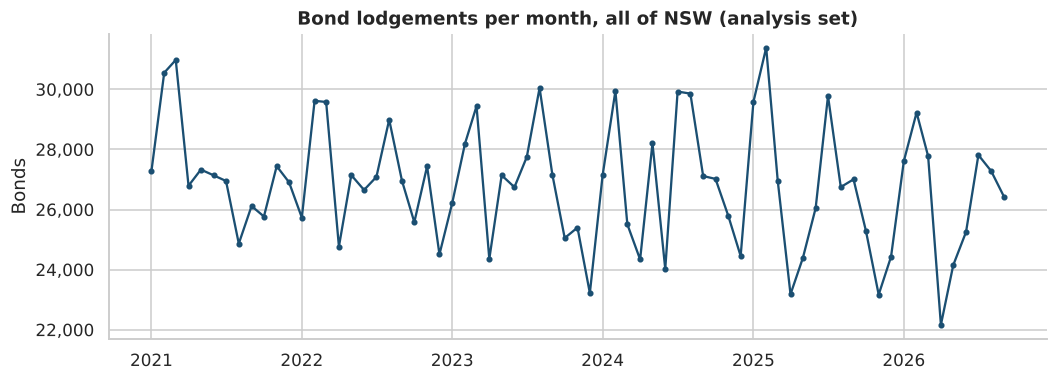

In [13]:
monthly = duckdb.sql("""
    SELECT date_trunc('month', date) AS month,
           count(*)                  AS bonds,
           round(median(rent))       AS median_rent
    FROM bond_src
    WHERE rent BETWEEN 100 AND 5000
    GROUP BY 1
    ORDER BY 1
""").df()
print("Months covered:", len(monthly), "| first:", monthly.month.min().date(), "| last:", monthly.month.max().date())

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(monthly.month, monthly.bonds, marker="o", ms=3, color="#1b4f72")
ax.set_title("Bond lodgements per month, all of NSW (analysis set)")
ax.set_ylabel("Bonds")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.show()

In [14]:
weekday = bond_src.date.dt.day_name().value_counts().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
print((weekday / weekday.sum() * 100).round(1).to_string())

date
Monday      19.50
Tuesday     18.70
Wednesday   17.90
Thursday    18.80
Friday      22.00
Saturday     2.40
Sunday       0.80


Lodgements fall almost entirely on weekdays, as expected for an administrative process. Weekend dates are rare and not a sign of a data problem.

### Outliers: IQR fences versus hard limits

Rent is strongly right-skewed, so the interquartile-range (IQR) rule is applied to **log rent**. We compare what the IQR rule would flag with the
fixed plausibility limits ($100–$5,000 a week) used in cleaning.

In [15]:
def iqr_bounds(s: pd.Series, k: float = 1.5) -> tuple[float, float]:
    """Return (lower, upper) Tukey fences for a numeric series: Q1 - k*IQR and Q3 + k*IQR."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

tmp = bond_src.dropna(subset=["rent"]).query("rent > 0").copy()
tmp["log_rent"] = np.log(tmp.rent)
lo, hi = iqr_bounds(tmp.log_rent)
tmp["iqr_flag"] = ~tmp.log_rent.between(lo, hi)
tmp["hard_flag"] = ~tmp.rent.between(100, 5000)
print(f"IQR fences on log rent -> ${np.exp(lo):,.0f} to ${np.exp(hi):,.0f} per week")
print(pd.crosstab(tmp.iqr_flag, tmp.hard_flag, margins=True).rename(
    index={False: "within IQR", True: "outside IQR"}, columns={False: "within $100–5,000", True: "outside $100–5,000"}))

IQR fences on log rent -> $208 to $1,722 per week


hard_flag    within $100–5,000  outside $100–5,000      All
iqr_flag                                                   
within IQR             1804447                   0  1804447
outside IQR              47379                3272    50651
All                    1851826                3272  1855098


The IQR rule flags far more rows than the hard limits, mostly plausible rents at either end of the range (inner-suburb flats, large houses). Removing them would
strip the very markets we want to study, so **only the hard-limit rule is used to drop rows**; the IQR fences are used for inspection.

**Looking at the rows before removing them.** The table profiles every bond with a valid dwelling code whose rent lies outside $100–$5,000 a week
(both files), followed by the most extreme high rents and a random sample of the low ones.

In [16]:
has_rent = lodg[valid & lodg.rent.notna()]
outside = {"below $100": has_rent[has_rent.rent < 100], "above $5,000": has_rent[has_rent.rent > 5000]}
removed_profile = pd.DataFrame.from_dict({k: {"bonds": len(d), "median rent ($/wk)": d.rent.median(), "min": d.rent.min(), "max": d.rent.max(),
                                               "rent = 0": int((d.rent == 0).sum()), "0 bedrooms (%)": (d.bedrooms == 0).mean() * 100,
                                               **{f"type {t} (%)": (d.dwelling == t).mean() * 100 for t in "FHTOU"}}
                                           for k, d in outside.items()}, orient="index")
display(removed_profile.round(1))
display(outside["above $5,000"].nlargest(5, "rent")[["date", "postcode", "dwelling", "bedrooms", "rent", "file"]])
display(outside["below $100"].sample(5, random_state=SEED)[["date", "postcode", "dwelling", "bedrooms", "rent", "file"]])

,bonds,median rent ($/wk),min,max,rent = 0,0 bedrooms (%),type F (%),type H (%),type T (%),type O (%),type U (%)
below $100,3472,60.00,0.00,99.00,100,42.80,21.70,14.40,1.50,58.20,4.20
"above $5,000",743,"6,300.00","5,020.00","10,000.00",0,0.50,32.40,59.60,3.90,2.70,1.30


,date,postcode,dwelling,bedrooms,rent,file
387783,2022-01-10,"2,000.00",F,4.00,"10,000.00",2021–2026 files
485720,2021-02-22,"2,026.00",H,4.00,"10,000.00",2021–2026 files
486532,2021-12-03,"2,027.00",H,3.00,"10,000.00",2021–2026 files
945378,2022-07-14,"2,088.00",H,3.00,"10,000.00",2021–2026 files
1024228,2023-06-23,"2,025.00",H,4.00,"10,000.00",2021–2026 files


,date,postcode,dwelling,bedrooms,rent,file
751108,2021-10-06,"2,736.00",F,2.00,85.00,2021–2026 files
335997,2022-04-08,"2,037.00",O,0.00,50.00,2021–2026 files
969577,2023-07-18,"2,026.00",O,1.00,75.00,2021–2026 files
226128,2018-06-12,"2,324.00",O,NaN,30.00,2018 file
42582,2018-06-18,"2,032.00",O,0.00,58.00,2018 file


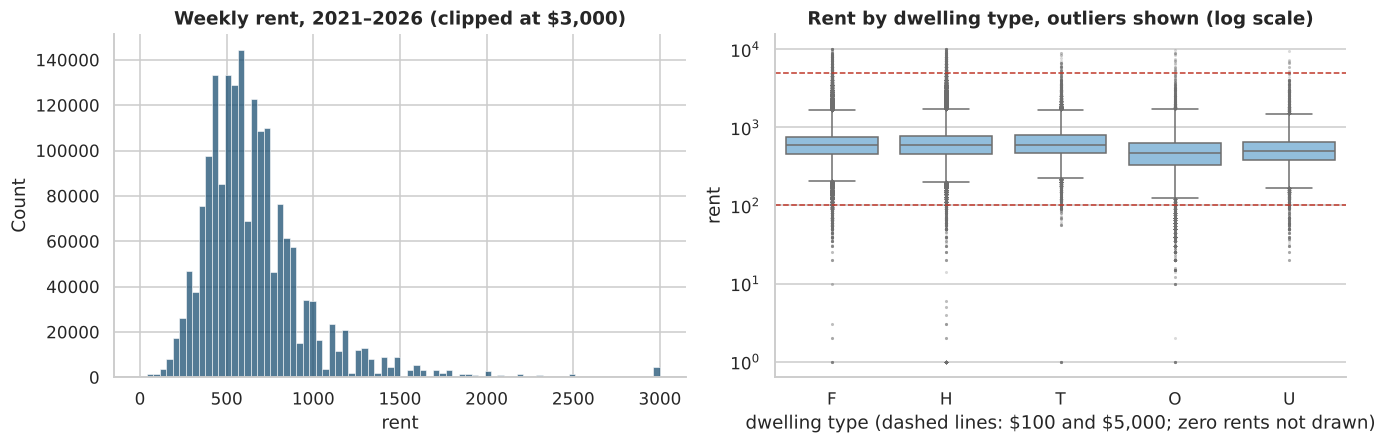

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
sns.histplot(tmp.rent.clip(upper=3000), bins=80, ax=axes[0], color="#1b4f72")
axes[0].set_title("Weekly rent, 2021–2026 (clipped at $3,000)")
sns.boxplot(data=has_rent[has_rent.rent > 0], x="dwelling", y="rent", order=list("FHTOU"), log_scale=True, ax=axes[1], color="#85c1e9",
            flierprops={"marker": ".", "markersize": 2, "alpha": 0.25})
for limit in (100, 5000):
    axes[1].axhline(limit, color="#c0392b", lw=1, ls="--")
axes[1].set_title("Rent by dwelling type, outliers shown (log scale)")
axes[1].set_xlabel(r"dwelling type (dashed lines: \$100 and \$5,000; zero rents not drawn)")
plt.tight_layout()
plt.show()

In [18]:
n_out = sum(len(d) for d in outside.values())
removed_all = pd.concat(outside.values())
share_O = (removed_all.dwelling == "O").mean()
flats_lost = (removed_all.dwelling == "F").sum() / (has_rent.dwelling == "F").sum()
low, high = outside["below $100"], outside["above $5,000"]
TYPE_NAME = {"F": "flats", "H": "houses", "T": "terraces/townhouses", "O": "'other' premises", "U": "unknown types"}
top_types = lambda d: " and ".join(TYPE_NAME[t] for t in d.dwelling.value_counts().index[:2])
md(f"**What the hard limits remove.** {n_out:,} bonds ({n_out / valid.sum():.2%} of bonds with a valid code). The low ones have a median rent of "
   f"${low.rent.median():,.0f} a week and include {int((low.rent == 0).sum())} zero rents, mostly {top_types(low)}: amounts that look like car spaces, storage "
   f"or part-payments rather than the weekly rent of a home. The high ones have a median of ${high.rent.median():,.0f} a week, mostly {top_types(high)}. "
   f"Type `O` ('other', which can include garages and car spaces) accounts for {share_O:.0%} of all removed rows, and only {flats_lost:.2%} of flat bonds are "
   "removed, so the limits barely touch the segments analysed. Unlike the IQR fences, they never cut the expensive end of an ordinary market. Section 8 adds "
   "a group-wise IQR check inside each postcode × segment × phase cell, the group in which the medians are actually computed.")

**What the hard limits remove.** 4,215 bonds (0.19% of bonds with a valid code). The low ones have a median rent of $60 a week and include 100 zero rents, mostly 'other' premises and flats: amounts that look like car spaces, storage or part-payments rather than the weekly rent of a home. The high ones have a median of $6,300 a week, mostly houses and flats. Type `O` ('other', which can include garages and car spaces) accounts for 48% of all removed rows, and only 0.09% of flat bonds are removed, so the limits barely touch the segments analysed. Unlike the IQR fences, they never cut the expensive end of an ordinary market. Section 8 adds a group-wise IQR check inside each postcode × segment × phase cell, the group in which the medians are actually computed.

## 2.2 Other sources

A compact profile function keeps the quality checks comparable across the smaller sources.

In [19]:
def profile(df: pd.DataFrame, name: str) -> dict:
    """One-line quality profile: shape, share of missing cells and exact duplicate rows."""
    return {"source": name, "rows": len(df), "columns": df.shape[1],
            "missing cells %": round(df.isna().mean().mean() * 100, 2), "duplicate rows": int(df.duplicated().sum())}

# --- CRICOS
cr_loc = pd.read_csv(RAW / "cricos_full" / "cricos-locations.csv", dtype=str, encoding="utf-8-sig")
cr_crs = pd.read_csv(RAW / "cricos_full" / "cricos-courses.csv", dtype=str, encoding="utf-8-sig")
cr_cl = pd.read_csv(RAW / "cricos_full" / "cricos-course-locations.csv", dtype=str, encoding="utf-8-sig")
cr_ins = pd.read_csv(RAW / "cricos_full" / "cricos-institutions.csv", dtype=str, encoding="utf-8-sig")

# --- Department of Education enrolments by SA4
doe = pd.read_excel(RAW / "doe_sa4" / "intl_student_sa4.xlsx", header=5, usecols=range(7)).dropna(subset=["State"])
doe = doe.rename(columns=lambda c: c.strip().lower().replace(" ", "_"))      # tidy column names
doe["enrolments"] = pd.to_numeric(doe["enrolments"], errors="coerce")           # "<5" cells are suppressed -> NaN

# --- BP0015 cube (visas granted; used for the sensitivity phases)
bp = pd.read_parquet(PROC / "bp0015_granted_cube.parquet")

# --- Enrichment tables extracted by 00_data_extraction_overview.ipynb
bp19 = pd.read_parquet(EXTRACTED / "bp0019_visa_holders.parquet")              # visa holders present, quarter-end
census = pd.read_parquet(EXTRACTED / "census2021_postcode.parquet")             # Census 2021, one row per NSW postcode
dcj = pd.read_parquet(EXTRACTED / "dcj_rent_postcode_quarterly.parquet")        # DCJ rent tables, 2018Q1-2022Q4
audit = pd.read_csv(EXTRACTED / "cos_housing_audit_student_rooms.csv")          # City of Sydney Housing Audit, June 2015-2025

pd.DataFrame([profile(cr_cl, "CRICOS course-locations"), profile(cr_loc, "CRICOS locations"), profile(cr_crs, "CRICOS courses"),
              profile(cr_ins, "CRICOS institutions"), profile(doe, "DoE enrolments by SA4"), profile(bp, "BP0015 visas granted"),
              profile(bp19, "BP0019 visa holders present"), profile(census, "Census 2021 by postcode"),
              profile(dcj, "DCJ rent tables (quarterly)"), profile(audit, "CoS Housing Audit")])

,source,rows,columns,missing cells %,duplicate rows
0,CRICOS course-locations,46511,6,0.00,51
1,CRICOS locations,3883,11,25.87,0
2,CRICOS courses,25973,24,23.58,1
3,CRICOS institutions,1547,13,26.84,1
4,DoE enrolments by SA4,1135,7,0.73,0
5,BP0015 visas granted,134822,8,0.00,0
6,BP0019 visa holders present,308631,7,0.00,0
7,Census 2021 by postcode,612,12,0.04,0
8,DCJ rent tables (quarterly),328021,14,26.05,24
9,CoS Housing Audit,11,7,1.30,0


In [20]:
dcj_dups = dcj[dcj.duplicated(keep=False)]
gs_pool = pd.read_csv(PROC / "exposure_postcode.csv", dtype={"poa": str}, usecols=["poa", "in_pool"]).query("in_pool").poa
print(f"DCJ exact duplicate rows: {int(dcj.duplicated().sum())}, in postcode(s) {sorted(dcj_dups.poa.unique())} and quarter(s) "
      f"{sorted(dcj_dups.quarter.unique())}; rows in the 247-postcode analysis pool: {int(dcj_dups.poa.isin(gs_pool).sum())}")

DCJ exact duplicate rows: 24, in postcode(s) ['2880', '2905', '2906'] and quarter(s) ['2020Q1']; rows in the 247-postcode analysis pool: 0


The DCJ table's missing cells are mostly **hidden** values (cells with 10 or fewer bonds), kept as `-` markers in its `*_flag` columns; how often they hit
the postcodes compared is shown in 6.5. Its exact duplicates (printed above) lie outside the analysis pool, and the join used in 6.5 is validated
one-to-one. The Census table has no missing rates for the 247 analysis postcodes (checked in 3.3).

**CRICOS join coverage.** The course-location file has no postcode, so it must be joined to the locations table. We test that the join key is reliable.

In [21]:
loc_u = cr_loc.drop_duplicates(["CRICOS Provider Code", "Location Name"])
joined = cr_cl.merge(loc_u[["CRICOS Provider Code", "Location Name", "Postcode"]],
                     on=["CRICOS Provider Code", "Location Name"], how="left", validate="m:1")
print(f"Course-location rows: {len(cr_cl):,} | matched to a postcode: {joined.Postcode.notna().mean():.1%}")
print("Expired courses in the courses table:", (cr_crs.Expired == 'Yes').sum())

Course-location rows: 46,511 | matched to a postcode: 100.0%
Expired courses in the courses table: 431


**Department of Education enrolments.** Sector labels differ in spelling and case; they are normalised before use. Suppressed cells (<5) become missing values.

In [22]:
print("Before:", sorted(doe.sector.unique()))
doe["sector"] = doe["sector"].str.replace(r"\s+", " ", regex=True).str.strip().str.title()
print("After: ", sorted(doe.sector.unique()))
print(f"Suppressed cells: {doe.enrolments.isna().sum()} of {len(doe)}")

Before: ['ELICOS', 'Higher  Education', 'Higher Education', 'Non-Award', 'Non-award', 'Schools', 'VET']
After:  ['Elicos', 'Higher Education', 'Non-Award', 'Schools', 'Vet']
Suppressed cells: 58 of 1135


## 2.3 Quality summary

| Source | Issue found | Impact | Treatment |
|---|---|---|---|
| Bond lodgements | Annual and monthly files overlap from 2022 | Double counting | Use 2021 annual + 2022+ monthly |
| Bond lodgements | Missing rent or bedrooms, concentrated in `U` bonds and in the 2018 file | Rows cannot enter a median or a segment | Drop and count; pattern examined (2.1); balance across groups checked (3.6) |
| Bond lodgements | Undefined dwelling codes, implausible rents | Biased medians | Drop invalid codes; keep rent $100–5,000 and bedrooms 0–8; removed rows examined (2.1) |
| Bond lodgements | No bond ID; exact duplicates | Cannot distinguish repeats from separate bonds | Keep duplicates; removal tested in 8 |
| Bond lodgements | Postcode only; 2019–2020 missing; 2018 file from a mirror | Coarse geography; no pre-COVID trend from bonds | Postcode-level analysis; DCJ medians for 2018–2022, which also confirm the 2018 file (6.5) |
| CRICOS | Course-locations file lacks postcode and level | Cannot place campuses | Join to locations (100% match) and courses |
| DoE SA4 | One year; cells <5 suppressed; place of study | Exposure is modelled, not observed | Use shares, document assumption; second measure from the Census |
| Census 2021 | Counts domestic and international students; taken while the border was closed | E4 is a different measure, not a cleaner one | Reported next to E2; grade = the lower of the two |
| BP0019 | National, all sectors; quarter-end snapshots are strongly seasonal | Phase boundaries are approximate | Read as year-on-year change; visa-grant phases kept as a check |
| BP0015 | Visas granted, not students present | Lags or leads demand | Sensitivity phases only |
| DCJ rent tables | Medians only; cells with ≤10 bonds hidden | Cannot be pooled or recomputed; hidden cells are more common in Low-tier postcodes | Separate 2018–2022 check, with a balanced-panel version |
| Housing Audit | City of Sydney only; room types mixed by village | No postcode link | Context chart only |

# 3. Data cleaning and preparation

## 3.1 Cleaning rules and their counts

The cleaning rules are expressed in SQL (DuckDB) so every row removed is accounted for. The 2018 file (read in 2.1) is stacked with the 2021–2026 files first.

In [23]:
bond_all = pd.concat([b18[["date", "postcode", "dwelling", "bedrooms", "rent"]].assign(source="2018"),
                      bond_src[["date", "postcode", "dwelling", "bedrooms", "rent"]].assign(source="2021-2026")],
                     ignore_index=True)

exposure = pd.read_csv(PROC / "exposure_postcode.csv", dtype={"poa": str, "E3_nearest_major_poa": str})
pool_df = exposure.loc[exposure.in_pool, ["poa"]]          # DataFrame so DuckDB can query it
pool_poas = pool_df["poa"]
bond_all["poa"] = bond_all.postcode.astype(int).astype(str).str.zfill(4)

cleaning_log = duckdb.sql("""
    SELECT 'raw rows (2018 + 2021-2026)'                                   AS step, count(*) AS rows FROM bond_all
    UNION ALL SELECT 'invalid dwelling code',        count(*) FROM bond_all WHERE dwelling NOT IN ('F','H','T','O','U')
    UNION ALL SELECT 'rent missing or outside 100-5,000 (valid dwelling)',  count(*) FROM bond_all
              WHERE dwelling IN ('F','H','T','O','U') AND NOT coalesce(rent BETWEEN 100 AND 5000, false)
    UNION ALL SELECT 'bedrooms missing or outside 0-8 (rest valid)',        count(*) FROM bond_all
              WHERE dwelling IN ('F','H','T','O','U') AND coalesce(rent BETWEEN 100 AND 5000, false)
                AND NOT coalesce(bedrooms BETWEEN 0 AND 8, false)
    UNION ALL SELECT 'clean rows, all NSW',          count(*) FROM bond_all
              WHERE dwelling IN ('F','H','T','O','U') AND coalesce(rent BETWEEN 100 AND 5000, false)
                AND coalesce(bedrooms BETWEEN 0 AND 8, false)
    UNION ALL SELECT 'clean rows in the 247-postcode analysis pool', count(*) FROM bond_all
              WHERE dwelling IN ('F','H','T','O','U') AND coalesce(rent BETWEEN 100 AND 5000, false)
                AND coalesce(bedrooms BETWEEN 0 AND 8, false) AND poa IN (SELECT poa FROM pool_df)
""").df()
log_n = dict(zip(cleaning_log.step, cleaning_log.rows))
# The rent step must equal the missing rents plus the rows profiled in 2.1 (below $100 and above $5,000).
assert log_n["rent missing or outside 100-5,000 (valid dwelling)"] == int((valid & lodg.rent.isna()).sum()) + n_out
cleaning_log["rows"] = cleaning_log["rows"].map("{:,}".format)
cleaning_log

,step,rows
0,raw rows (2018 + 2021-2026),"2,215,281"
1,invalid dwelling code,65
2,"rent missing or outside 100-5,000 (valid dwell...","45,082"
3,bedrooms missing or outside 0-8 (rest valid),"40,690"
4,"clean rows, all NSW","2,129,444"
5,clean rows in the 247-postcode analysis pool,"1,484,734"


## 3.2 The analysis panel

The panel produced by `scripts/06_build_panel.py` is loaded and checked against the cleaning log above. Each bond already carries its postcode's
SA3/SA4, exposure measures and market segment. (Its stored `phase` column uses the visa-grant dates; phases are re-derived in 3.6.)

In [24]:
panel = pd.read_parquet(PROC / "analysis_bond_panel.parquet")
assert len(panel) == log_n["clean rows in the 247-postcode analysis pool"], "panel row count must equal the cleaning log"
assert panel.rent.between(100, 5000).all() and panel.bedrooms.between(0, 8).all()
assert panel.poa.isin(pool_poas).all()
print(f"Panel: {len(panel):,} bonds | {panel.poa.nunique()} postcodes | {panel.date.min().date()} to {panel.date.max().date()}")
panel[["date", "poa", "dwelling", "bedrooms", "rent", "seg", "sa3", "E2_rows_l3", "E3_dist_major_km"]].sample(5, random_state=SEED)

Panel: 1,484,734 bonds | 247 postcodes | 2018-01-01 to 2026-09-30


,date,poa,dwelling,bedrooms,rent,seg,sa3,E2_rows_l3,E3_dist_major_km
793681,2022-10-31,2145,U,3.00,580.00,other,Parramatta,3.13,5.05
1436643,2025-10-16,2089,F,2.00,810.00,f2,North Sydney - Mosman,25.65,1.31
1147605,2024-03-21,2107,H,4.00,"1,500.00",h34,Pittwater,0.01,25.14
1406466,2026-05-11,2137,F,3.00,"1,780.00",f3p,Canada Bay,8.00,2.57
1123344,2024-09-17,2017,F,0.00,690.00,f01,Sydney Inner City,67.67,1.47


**Market segments.** Student demand is expected to be strongest in small flats, so rent is analysed by segment. 3–4 bedroom houses are the placebo segment.

In [25]:
seg_tab = (panel.groupby("seg")
           .agg(bonds=("rent", "size"), median_rent=("rent", "median"), share=("rent", lambda s: len(s) / len(panel) * 100))
           .sort_values("bonds", ascending=False))
seg_tab["share"] = seg_tab["share"].round(1)
seg_tab

,bonds,median_rent,share
seg,,,
f2,497041,650.00,33.50
f01,329776,560.00,22.20
h34,326128,710.00,22.00
other,244956,600.00,16.50
f3p,86833,900.00,5.80


## 3.3 Feature scaling: when does it matter?

The exposure measures (described in 3.4) come in different units: E2 in thousands of distance-weighted enrolments, E3 in kilometres, E1 as a share, and
the Census measure E4 as students per 100 residents. Min–max scaling, z-score standardisation and the log transform put them on comparable scales.
Scaling matters only when **values** of different measures are compared or combined. It does not matter for anything built on **ranks**: Spearman
correlations and the tertile tiers used in this notebook are unchanged by any increasing transformation. The first cell checks this.

In [26]:
def minmax(s: pd.Series) -> pd.Series:
    """Rescale to the 0–1 range."""
    return (s - s.min()) / (s.max() - s.min())

def zscore(s: pd.Series) -> pd.Series:
    """Centre on the mean and divide by the standard deviation."""
    return (s - s.mean()) / s.std(ddof=1)

EXPOSURE_VARIANTS = {
    "E2 λ=1.5 km": "E2_rows_l1.5",
    "E2 λ=3 km (primary)": "E2_rows_l3",
    "E2 λ=5 km": "E2_rows_l5",
    "E2 equal-split λ=3 km": "E2_equal_l3",
    "E3 distance (inverted)": "E3_dist_major_km",
    "E1 SA4 share (HE)": "E1_share_he",
}
pool_pc = exposure[exposure.in_pool].copy()
pool_pc["E3_dist_major_km"] = -pool_pc["E3_dist_major_km"]          # invert so that higher always means "more exposed"
raw_vals = pd.DataFrame({k: pool_pc[v].to_numpy() for k, v in EXPOSURE_VARIANTS.items()})
scaled = raw_vals.apply(minmax)
rank_shift = (scaled.corr(method="spearman") - raw_vals.corr(method="spearman")).abs().max().max()
e2 = raw_vals["E2 λ=3 km (primary)"]
tier_shift = int((pd.qcut(e2, 3, labels=False) != pd.qcut(zscore(np.log(e2)), 3, labels=False)).sum())
print(f"Largest change in any Spearman correlation after min–max scaling: {rank_shift:.1g}")
print(f"Postcodes whose E2 tertile changes after a log transform and z-score: {tier_shift} of {len(e2)}")
display(scaled.describe().loc[["mean", "50%", "max"]].round(3))

Largest change in any Spearman correlation after min–max scaling: 0
Postcodes whose E2 tertile changes after a log transform and z-score: 0 of 247


,E2 λ=1.5 km,E2 λ=3 km (primary),E2 λ=5 km,E2 equal-split λ=3 km,E3 distance (inverted),E1 SA4 share (HE)
mean,0.07,0.12,0.19,0.11,0.81,0.13
50%,0.00,0.02,0.08,0.02,0.87,0.01
max,1.00,1.00,1.00,1.00,1.00,1.00


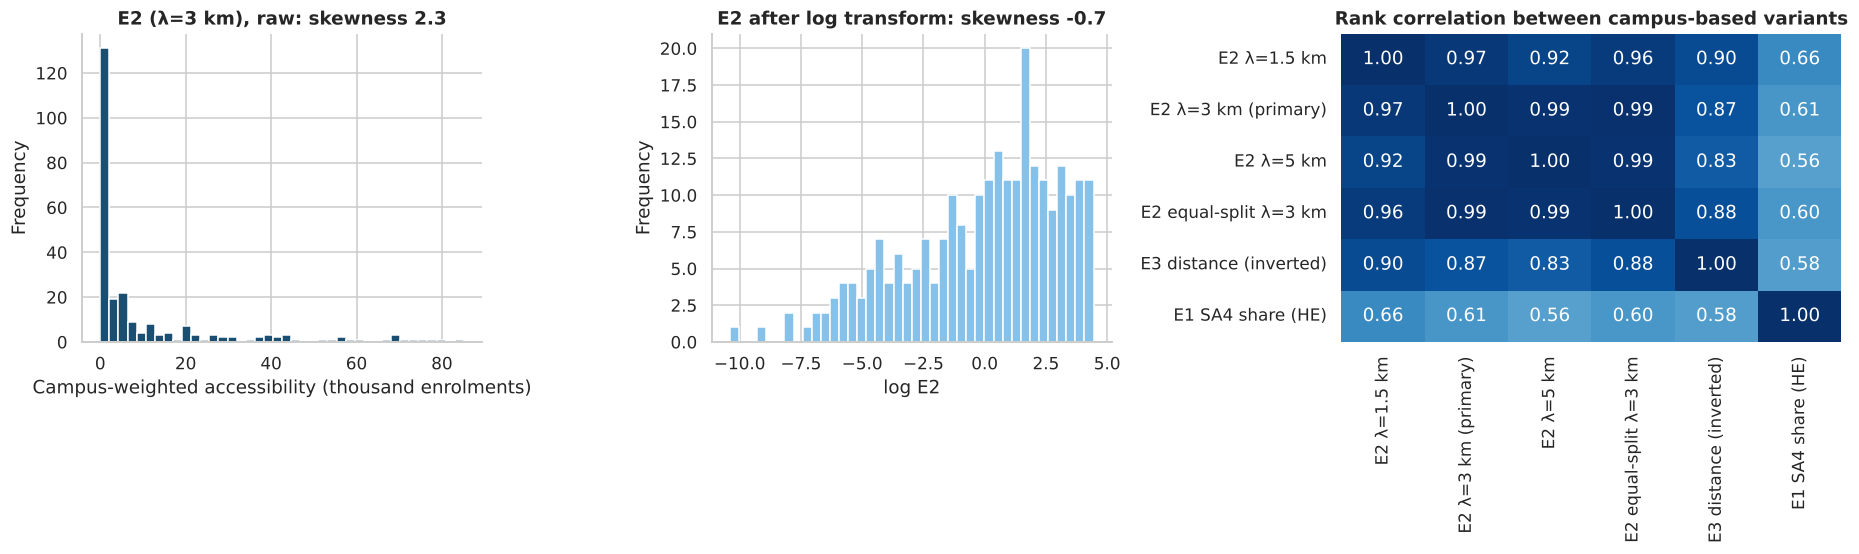

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1, 1, 1.25]})
pool_pc["E2_rows_l3"].plot.hist(bins=40, ax=axes[0], color="#1b4f72")
axes[0].set_title(f"E2 (λ=3 km), raw: skewness {pool_pc.E2_rows_l3.skew():.1f}")
axes[0].set_xlabel("Campus-weighted accessibility (thousand enrolments)")
np.log(pool_pc["E2_rows_l3"]).plot.hist(bins=40, ax=axes[1], color="#85c1e9")
axes[1].set_title(f"E2 after log transform: skewness {np.log(pool_pc.E2_rows_l3).skew():.1f}")
axes[1].set_xlabel("log E2")
sns.heatmap(raw_vals.corr(method="spearman"), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[2], cbar=False)
axes[2].set_title("Rank correlation between campus-based variants")
plt.tight_layout()
plt.show()

The campus-based variants are strongly related, which is expected: all of them describe proximity to the same handful of campuses. This matters for how much
a robustness check across them can prove (section 8).

**Where scaling does matter: comparing two measures postcode by postcode.** The campus-based E2 and the Census-based E4 (university students living in the
postcode per 100 residents) are on different scales and both are right-skewed, so each is log-transformed and then standardised. On that common scale a
postcode's two values can be compared directly: a large difference marks a postcode that one measure treats as student-exposed and the other does not. The
comparison uses the 117 postcodes that are compared later (City of Sydney plus flat-heavy comparators; 3.5).

{'E2': 'skewness 1.30 raw → -0.86 log', 'E4': 'skewness 3.53 raw → 1.59 log'}


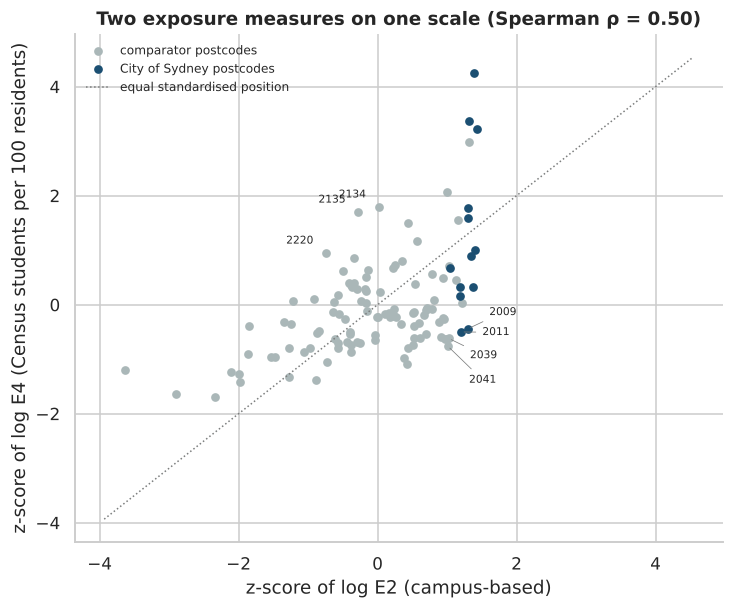

poa                               sa3  E2_rows_l3  uni_students_per_100  z_logE2  z_logE4  z_gap
near campuses, fewer student residents             32   2041                        Leichhardt       42.70                  5.03     1.01    -0.76  -1.77
                                                   3    2009                 Sydney Inner City       68.26                  5.62     1.30    -0.44  -1.74
                                                   5    2011                 Sydney Inner City       58.16                  5.50     1.20    -0.50  -1.70
                                                   30   2039                        Leichhardt       43.63                  5.28     1.02    -0.62  -1.64
more student residents than campus proximity su... 78   2135  Strathfield - Burwood - Ashfield        5.36                 11.87    -0.28     1.71   1.98
                                                   77   2134  Strathfield - Burwood - Ashfield        8.59                 12.27     0.01     1.80   1.79
                                                   109  2220                        Hurstville        2.54                  9.13    -0.74     0.95   1.70

In [28]:
base = pd.read_csv(PROC / "postcode_baseline.csv", dtype={"poa": str, "E3_nearest_major_poa": str})
in_comparison = base.city_of_sydney | base.comparator_candidate
census_pool = census[census.poa.isin(pool_poas)]
assert len(census_pool) == len(pool_poas) and census_pool[["uni_students_per_100", "uni_ft_15_24_per_100"]].notna().all().all()

zc = (base.loc[in_comparison, ["poa", "sa3", "city_of_sydney", "E2_rows_l3"]]
      .merge(census[["poa", "uni_students_per_100"]], on="poa", how="left", validate="1:1"))
zc["z_logE2"] = zscore(np.log(zc.E2_rows_l3))
zc["z_logE4"] = zscore(np.log(zc.uni_students_per_100))
zc["z_gap"] = zc.z_logE4 - zc.z_logE2           # > 0: more student residents than campus proximity suggests
rho_e2e4_all = stats.spearmanr(census_pool.set_index("poa").loc[pool_poas, "uni_students_per_100"], pool_pc.set_index("poa").loc[pool_poas, "E2_rows_l3"]).statistic
rho_e2e4_cmp = stats.spearmanr(zc.E2_rows_l3, zc.uni_students_per_100).statistic
print({m: f"skewness {s.skew():.2f} raw → {np.log(s).skew():.2f} log" for m, s in [("E2", zc.E2_rows_l3), ("E4", zc.uni_students_per_100)]})

neg = zc[zc.z_logE2 > 0].nsmallest(4, "z_gap")                      # near campuses, few student residents
pos = zc[(zc.z_logE4 > 0) & ~zc.city_of_sydney].nlargest(3, "z_gap")  # many student residents, far from campuses
fig, ax = plt.subplots(figsize=(7.6, 6))
for flag, col, lab in [(False, "#aab7b8", "comparator postcodes"), (True, "#1b4f72", "City of Sydney postcodes")]:
    pts = zc[zc.city_of_sydney == flag]
    ax.scatter(pts.z_logE2, pts.z_logE4, s=22, c=col, label=lab)
lim = [min(zc.z_logE2.min(), zc.z_logE4.min()) - 0.3, max(zc.z_logE2.max(), zc.z_logE4.max()) + 0.3]
ax.plot(lim, lim, color="#7b7d7d", lw=1, ls=":", label="equal standardised position")
for k, r in enumerate(neg.sort_values("z_logE4").itertuples()):
    ax.annotate(r.poa, (r.z_logE2, r.z_logE4), fontsize=7, xytext=(14, -24 + 11 * k), textcoords="offset points",
                arrowprops={"arrowstyle": "-", "color": "#7b7d7d", "lw": 0.5})
for r in pos.itertuples():
    ax.annotate(r.poa, (r.z_logE2, r.z_logE4), fontsize=7, xytext=(-26, 6), textcoords="offset points")
ax.set_xlabel("z-score of log E2 (campus-based)"); ax.set_ylabel("z-score of log E4 (Census students per 100 residents)")
ax.set_title(f"Two exposure measures on one scale (Spearman ρ = {rho_e2e4_cmp:.2f})")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()
gap_tab = pd.concat({"near campuses, fewer student residents": neg, "more student residents than campus proximity suggests": pos})[
    ["poa", "sa3", "E2_rows_l3", "uni_students_per_100", "z_logE2", "z_logE4", "z_gap"]]
gap_tab.round(2)

In [29]:
md(f"**What the common scale shows.** The two measures agree on the broad ranking (ρ = {rho_e2e4_all:.2f} across all 247 postcodes) but much less inside the "
   f"comparison pool (ρ = {rho_e2e4_cmp:.2f}). Postcodes such as {', '.join(f'{r.poa} ({r.sa3})' for r in neg.itertuples())} sit high on campus "
   f"proximity but have few student residents, while {', '.join(f'{r.poa} ({r.sa3}, {r.uni_students_per_100:.0f} per 100 residents)' for r in pos.itertuples())} "
   "have more student residents than their distance to campuses implies. The two measures therefore draw different High and Low groups, which is what makes E4 a real test "
   "of E2 rather than another variant of it. **Why not average the two z-scores into one index?** A composite would be a third way of drawing the tiers, "
   "adding another analysis path to choose from without settling which measure reflects where students rent. The analysis reports both side by side and "
   "grades the evidence on the weaker of the two (6.7).")

**What the common scale shows.** The two measures agree on the broad ranking (ρ = 0.77 across all 247 postcodes) but much less inside the comparison pool (ρ = 0.50). Postcodes such as 2041 (Leichhardt), 2009 (Sydney Inner City), 2011 (Sydney Inner City), 2039 (Leichhardt) sit high on campus proximity but have few student residents, while 2135 (Strathfield - Burwood - Ashfield, 12 per 100 residents), 2134 (Strathfield - Burwood - Ashfield, 12 per 100 residents), 2220 (Hurstville, 9 per 100 residents) have more student residents than their distance to campuses implies. The two measures therefore draw different High and Low groups, which is what makes E4 a real test of E2 rather than another variant of it. **Why not average the two z-scores into one index?** A composite would be a third way of drawing the tiers, adding another analysis path to choose from without settling which measure reflects where students rent. The analysis reports both side by side and grades the evidence on the weaker of the two (6.7).

## 3.4 Geography and exposure

**How the campus-based exposure is built.**
1. Campuses are CRICOS higher-education course locations in Greater Sydney (485 campuses; 16 "major" with at least 50 HE course-location rows).
2. Each SA4's higher-education enrolments (Department of Education) are split across the campuses in that SA4 in proportion to their HE course-location rows. **This is an allocation assumption, not observed enrolment per campus.**
3. **E2** for a postcode is the sum over campuses of weight × exp(−distance / λ). **E3** is the distance to the nearest major campus. **E1** is the SA4's share of enrolments.
4. Distances use ABS postcode-area centroids, so resolution is about 1 km. UNSW (postcode 2052) and Macquarie (2109) have no ABS postcode area and are mapped to 2033 and 2113.

**The Census-based exposure (E4).** University and other higher-education students **living** in the postcode per 100 residents (Census 2021 tables G15 and G01).
It describes where students live rather than where they study, and does not depend on the allocation assumption above. It counts domestic as well as
international students, and was taken on 10 August 2021 while the border was closed, so international students are under-represented. A second version counts
full-time students aged 15–24 only.

In [30]:
campuses = pd.read_csv(PROC / "he_campuses.csv", dtype={"poa": str, "postcode_cricos": str})
print(f"Campuses: {len(campuses)} | major (>=50 HE rows): {(campuses.he_rows >= 50).sum()}")
campuses.sort_values("w_rows", ascending=False)[
    ["Institution Name", "Location Name", "poa", "sa4", "he_rows", "w_rows"]].head(8).round(0)

Campuses: 485 | major (>=50 HE rows): 16


,Institution Name,Location Name,poa,sa4,he_rows,w_rows
20,The University of New South Wales (UNSW),The University of New South Wales,2033,Sydney - Eastern Suburbs,554,"40,768.00"
16,The University of Sydney,The University of Sydney,2050,Sydney - City and Inner South,579,"23,355.00"
23,University of Technology Sydney (UTS),University of Technology Sydney (City Campus),2007,Sydney - City and Inner South,516,"20,813.00"
1,Macquarie University (Macquarie),Macquarie University Wallumattagal Campus at N...,2113,Sydney - Ryde,353,"13,576.00"
189,Torrens University Australia Limited,"1-37 Foveaux Street, Surry Hills NSW 2010",2010,Sydney - City and Inner South,129,"5,203.00"
71,Western Sydney University,Western Sydney University - Parramatta,2150,Sydney - Parramatta,169,"3,885.00"
80,The University of Notre Dame Australia,The University of Notre Dame Australia - Broadway,2007,Sydney - City and Inner South,73,"2,945.00"
21,The University of New South Wales (UNSW),UNSW Art & Design,2021,Sydney - Eastern Suburbs,40,"2,944.00"


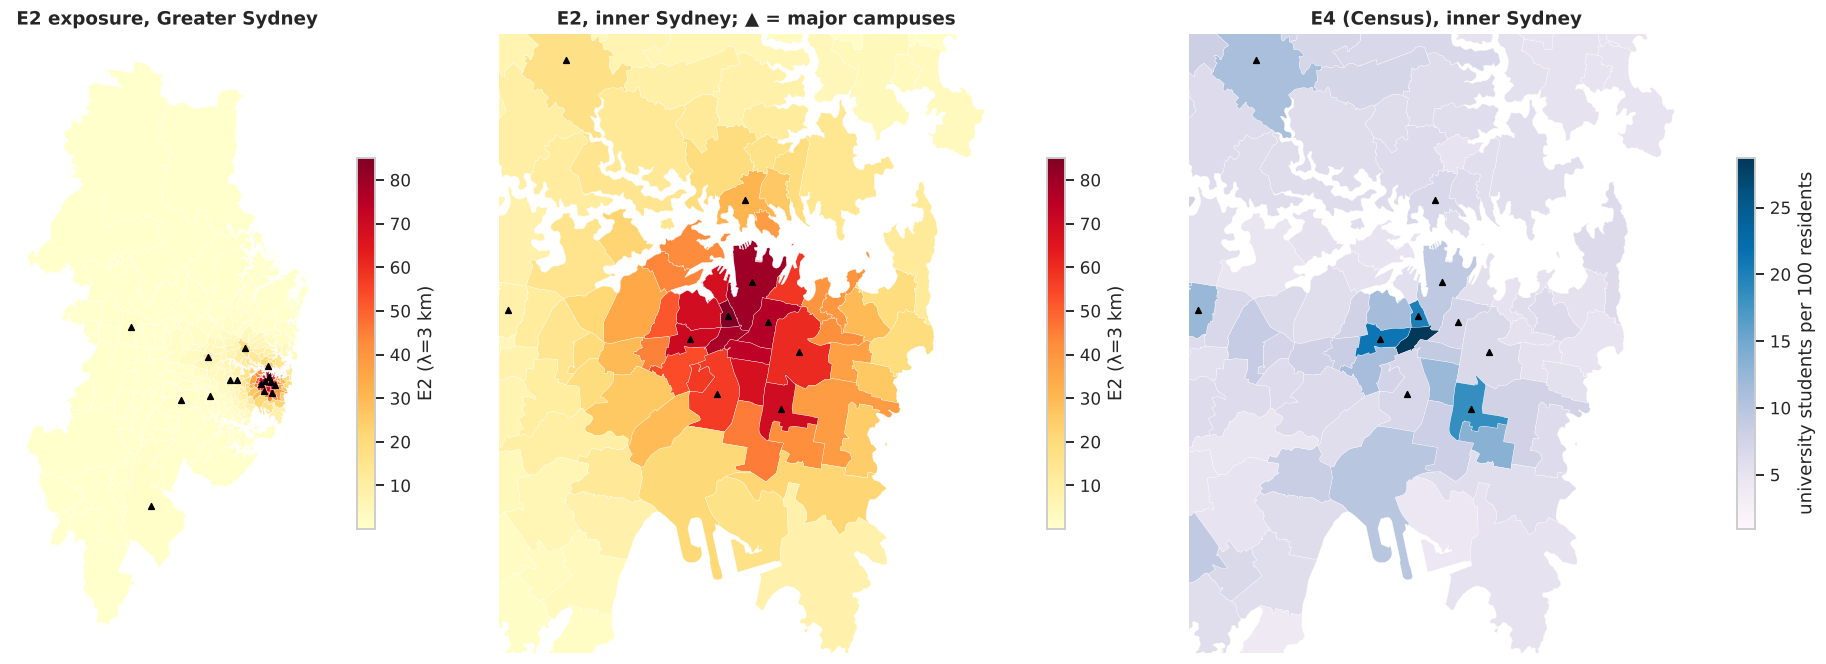

In [31]:
POA_SHP = RAW / "abs_poa" / "shp" / "POA_2021_AUST_GDA2020.shp"
poa_gdf = gpd.read_file(POA_SHP, bbox=(150.55, -34.25, 151.45, -33.35)).rename(columns={"POA_CODE21": "poa"})[["poa", "geometry"]]
poa_gdf = (poa_gdf[poa_gdf.poa.isin(pool_poas)].merge(exposure.drop(columns=["lat", "lon"]), on="poa")
           .merge(census[["poa", "uni_students_per_100"]], on="poa", how="left"))
cam_df = campuses.groupby("poa").agg(lat=("lat", "first"), lon=("lon", "first"), he_rows=("he_rows", "sum")).reset_index()
cam_pts = gpd.GeoDataFrame(cam_df, geometry=gpd.points_from_xy(cam_df.lon, cam_df.lat), crs=poa_gdf.crs)
cam_pts = cam_pts[(cam_pts.he_rows >= 50) & cam_pts.poa.isin(pool_poas)]

def draw_map(ax, gdf, col, title, cmap="YlOrRd", bbox=None, points=None, legend_label=""):
    """Choropleth of postcode areas; optional bounding box (zoom) and point overlay."""
    gdf.plot(column=col, cmap=cmap, linewidth=0.2, edgecolor="white", ax=ax, legend=True,
             legend_kwds={"shrink": 0.6, "label": legend_label}, missing_kwds={"color": "#e5e8e8"})
    if points is not None:
        points.plot(ax=ax, color="black", markersize=14, marker="^", zorder=5)
    if bbox:
        ax.set_xlim(bbox[0], bbox[2]); ax.set_ylim(bbox[1], bbox[3])
    ax.set_aspect(1 / np.cos(np.radians(33.85)))
    ax.set_axis_off(); ax.set_title(title)

inner = (151.10, -34.00, 151.32, -33.78)
fig, axes = plt.subplots(1, 3, figsize=(19, 6.2))
draw_map(axes[0], poa_gdf, "E2_rows_l3", "E2 exposure, Greater Sydney", points=cam_pts, legend_label="E2 (λ=3 km)")
draw_map(axes[1], poa_gdf, "E2_rows_l3", "E2, inner Sydney; ▲ = major campuses", bbox=inner, points=cam_pts, legend_label="E2 (λ=3 km)")
draw_map(axes[2], poa_gdf, "uni_students_per_100", "E4 (Census), inner Sydney", cmap="PuBu", bbox=inner, points=cam_pts,
         legend_label="university students per 100 residents")
plt.tight_layout()
plt.show()

## 3.5 Groups used for comparison

The City of Sydney's own postcodes are almost all flats and almost all within 2 km of a major campus, so they cannot be compared with each other.
The comparison pool therefore contains **flat-heavy postcodes elsewhere in Greater Sydney** (at least 35% of 2018 bonds were flats, and at least 200
studio/1BR and 2BR bonds in 2018). All eligible postcodes are split into tertiles twice: by E2 (`tier`) and by E4 (`tier_E4`).

In [32]:
elig = base[in_comparison].copy()
elig = elig.merge(census[["poa", "uni_students_per_100", "uni_ft_15_24_per_100", "renter_share_pct", "median_rent_weekly",
                          "median_hhd_income_weekly"]], on="poa", how="left", validate="1:1")
elig = elig.rename(columns={"uni_students_per_100": "E4", "uni_ft_15_24_per_100": "E4_ft1524"})
assert elig.E4.notna().all()
elig["tier"] = pd.qcut(elig.E2_rows_l3, 3, labels=["Low", "Mid", "High"])
elig["tier_E4"] = pd.qcut(elig.E4, 3, labels=["Low", "Mid", "High"])
elig["group"] = np.where(elig.city_of_sydney, "City of Sydney", "Comparator – " + elig.tier.astype(str))

grp_tab = (elig.groupby("group")
           .agg(postcodes=("poa", "size"), flat_share_2018=("flat_share_2018", "mean"),
                median_f01_2018=("med_f01_2018", "median"), median_f2_2018=("med_f2_2018", "median"),
                E2_min=("E2_rows_l3", "min"), E2_max=("E2_rows_l3", "max"), median_dist_km=("E3_dist_major_km", "median"),
                median_E4=("E4", "median"))
           .reindex(list(COLORS)))
grp_tab

,postcodes,flat_share_2018,median_f01_2018,median_f2_2018,E2_min,E2_max,median_dist_km,median_E4
group,,,,,,,,
City of Sydney,13,0.73,560.00,770.00,45.23,85.13,0.91,8.97
Comparator – High,26,0.75,517.50,675.00,19.80,69.76,2.39,6.36
Comparator – Mid,39,0.75,490.00,590.00,4.60,19.57,4.10,6.23
Comparator – Low,39,0.64,410.00,490.00,0.02,4.55,8.08,5.18


Baseline rents differ by group (City of Sydney is dearer in 2018), so the analysis compares **changes**, not levels.

**How different are the two tierings?**

In [33]:
tier_xtab = pd.crosstab(elig.tier, elig.tier_E4, rownames=["E2 tier"], colnames=["E4 tier"])
same_tier = (elig.tier.astype(str) == elig.tier_E4.astype(str)).mean()
PROFILE_COLS = ["E4", "E2_rows_l3", "renter_share_pct", "median_rent_weekly", "median_hhd_income_weekly"]
tier_profile = pd.concat({name: elig.groupby(tcol, observed=True)[PROFILE_COLS].median()
                          for name, tcol in [("E2 tiers", "tier"), ("E4 tiers", "tier_E4")]})
display(tier_xtab, tier_profile.round(1))
cos_in_e4 = elig[elig.city_of_sydney].tier_E4.value_counts().reindex(["High", "Mid", "Low"])
md(f"Only {same_tier:.0%} of the {len(elig)} postcodes fall in the same tier under both measures. E4-High postcodes have a lower median Census rent "
   f"(${tier_profile.loc[('E4 tiers', 'High'), 'median_rent_weekly']:,.0f} a week) than E2-High ones "
   f"(${tier_profile.loc[('E2 tiers', 'High'), 'median_rent_weekly']:,.0f}), and the {int(elig.city_of_sydney.sum())} City of Sydney postcodes"
   + (", all E2-High," if (elig.loc[elig.city_of_sydney, "tier"] == "High").all() else "")
   + f" fall into the E4 tiers as {', '.join(f'{n} {t}' for t, n in cos_in_e4.items())}. "
   "If the same pattern appears under both tierings, it does not depend on the campus allocation assumption.")

E4 tier,Low,Mid,High
E2 tier,,,
Low,23,11,5
Mid,9,15,15
High,7,13,19


E4  E2_rows_l3  renter_share_pct  median_rent_weekly  median_hhd_income_weekly
         tier                                                                                 
E2 tiers Low  5.20        2.10             54.90              460.00                  2,009.00
         Mid  6.20        8.90             60.70              520.00                  2,248.00
         High 6.90       42.70             69.60              575.00                  2,422.00
E4 tiers Low  5.00        4.10             56.10              550.00                  2,235.00
         Mid  6.10       12.30             59.50              525.00                  2,420.00
         High 8.30       17.20             69.10              500.00                  2,156.00

Only 49% of the 117 postcodes fall in the same tier under both measures. E4-High postcodes have a lower median Census rent ($500 a week) than E2-High ones ($575), and the 13 City of Sydney postcodes, all E2-High, fall into the E4 tiers as 10 High, 3 Mid, 0 Low. If the same pattern appears under both tierings, it does not depend on the campus allocation assumption.

## 3.6 Phases of student numbers

**Primary definition: students present.** Home Affairs BP0019 counts student visa holders (primary applicants) present in Australia at each quarter-end.
This is closer to rental demand than the number of visas granted, which includes renewals for students already here and visas for students who have not
yet arrived. The series is national and strongly seasonal (low at the end of December), so it is read as the change against the same quarter a year earlier.

**Sensitivity definition: visas granted.** NSW student visas granted to primary applicants (BP0015), rolling 12-month total, as in the first version of this analysis.

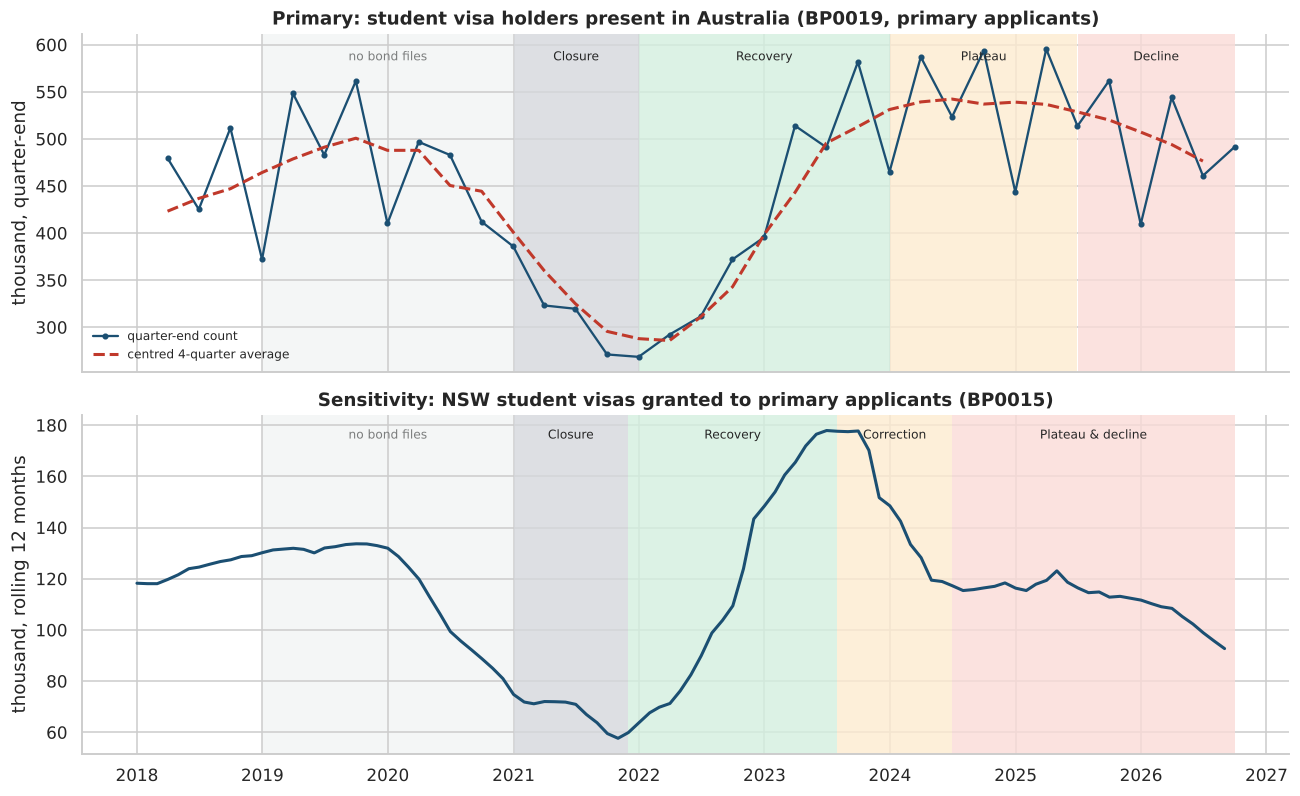

snapshot,Mar 2021,Jun 2021,Sep 2021,Dec 2021,Mar 2022,Jun 2022,Sep 2022,Dec 2022,Mar 2023,Jun 2023,Sep 2023,Dec 2023,Mar 2024,Jun 2024,Sep 2024,Dec 2024,Mar 2025,Jun 2025,Sep 2025,Dec 2025,Mar 2026,Jun 2026,Sep 2026
students present,323126,319567,271089,268529,292228,311552,371976,395478,513958,491056,581616,464941,586965,523416,593692,443664,595339,513656,561778,409385,543960,460881,491361
vs same quarter a year earlier (%),-35.00,-33.80,-34.20,-30.40,-9.60,-2.50,37.20,47.30,75.90,57.60,56.40,17.60,14.20,6.60,2.10,-4.60,1.40,-1.90,-5.40,-7.70,-8.60,-10.30,-12.50
phase,Closure (2021),Closure (2021),Closure (2021),Closure (2021),Recovery (2022–23),Recovery (2022–23),Recovery (2022–23),Recovery (2022–23),Recovery (2022–23),Recovery (2022–23),Recovery (2022–23),Recovery (2022–23),Plateau (Jan 2024–Jun 2025),Plateau (Jan 2024–Jun 2025),Plateau (Jan 2024–Jun 2025),Plateau (Jan 2024–Jun 2025),Plateau (Jan 2024–Jun 2025),Plateau (Jan 2024–Jun 2025),Decline (Jul 2025–Sep 2026),Decline (Jul 2025–Sep 2026),Decline (Jul 2025–Sep 2026),Decline (Jul 2025–Sep 2026),Decline (Jul 2025–Sep 2026)


Students present: trough Dec 2021 268,529 | peak Mar 2025 595,339 | latest Sep 2026 491,361
Visas granted: trough Nov 2021 | peak Jul 2023 | latest Sep 2026 92,709


In [34]:
def bp_dates(df: pd.DataFrame) -> pd.Series:
    """Convert BP0015 financial-year + month labels (e.g. '2022-23', 'M01 Jul') into calendar month starts."""
    mn = df.month.str.extract(r"M(\d+)")[0].astype(int)
    fy0 = df.fy.str[:4].astype(int)
    cal_month = ((mn + 5) % 12) + 1
    cal_year = np.where(mn <= 6, fy0, fy0 + 1)
    return pd.to_datetime(dict(year=cal_year, month=cal_month, day=1))

def phase_of(dates: pd.Series, phases: dict) -> pd.Series:
    """Label each date with the phase whose [start, end] range contains it ('' if none)."""
    out = pd.Series("", index=dates.index, dtype=object)
    for name, (a, b) in phases.items():
        out[(dates >= a) & (dates <= b)] = name
    return out

# Students present (BP0019), national, quarter-end
stock = bp19[(bp19.visa_category == "Student") & (bp19.applicant_type == "Primary")].groupby("snapshot").visa_holders.sum().sort_index()
yoy = (stock / stock.shift(4) - 1) * 100                          # change against the same quarter a year earlier, %

# Visas granted (BP0015), NSW, rolling 12 months
bp["date"] = bp_dates(bp)
nsw_primary = bp[(bp.state == "NSW") & (bp.applicant == "Primary")].groupby("date").grants.sum()
roll12 = nsw_primary.rolling(12).sum().dropna()
roll12 = roll12[roll12.index >= "2018-01-01"]

PHASES = {"0_base2018": ("2018-01-01", "2018-12-31"), "1_closure": ("2021-01-01", "2021-12-31"),
          "2_recovery": ("2022-01-01", "2023-12-31"), "3_plateau": ("2024-01-01", "2025-06-30"),
          "4_decline": ("2025-07-01", "2026-09-30")}
PHASE_LABEL = {"0_base2018": "2018 baseline", "1_closure": "Closure (2021)", "2_recovery": "Recovery (2022–23)",
               "3_plateau": "Plateau (Jan 2024–Jun 2025)", "4_decline": "Decline (Jul 2025–Sep 2026)"}
PHASES_FLOW = {"0_base2018": ("2018-01-01", "2018-12-31"), "1_closure": ("2021-01-01", "2021-11-30"),
               "2_recovery": ("2021-12-01", "2023-07-31"), "3_correction": ("2023-08-01", "2024-06-30"),
               "4_plateau_decline": ("2024-07-01", "2026-09-30")}
PHASE_LABEL_FLOW = {"0_base2018": "2018 baseline", "1_closure": "Closure (Jan–Nov 2021)", "2_recovery": "Recovery (Dec 2021–Jul 2023)",
                    "3_correction": "Correction (Aug 2023–Jun 2024)", "4_plateau_decline": "Plateau & decline (Jul 2024–Sep 2026)"}

# The primary boundaries follow the stock: trough, end of fast growth, start of sustained decline.
trough, peak = stock["2020-01-01":].idxmin(), stock.idxmax()
after = yoy[yoy.index > trough]
assert trough == pd.Timestamp("2021-12-31") and peak == pd.Timestamp("2025-03-31")
assert stock["2021-12-31"] < stock["2022-03-31"] < stock["2022-06-30"] < stock["2022-09-30"], "recovery: the stock rises every quarter after the trough"
assert (after["2022-09-30":"2023-12-31"] >= 15).all(), "recovery: year-on-year growth of at least +15% at every quarter-end from Sep 2022"
assert after["2024-01-01":"2025-06-30"].between(-5, 15).all(), "plateau: growth between -5% and +15%"
assert (after["2025-07-01":] <= -5).all(), "decline: a fall of at least 5% at every quarter-end"

FILL = ["#d5d8dc", "#d4efdf", "#fdebd0", "#fadbd8"]
fig, axes = plt.subplots(2, 1, figsize=(12, 7.4), sharex=True)
axes[0].plot(stock["2018-01-01":].index, stock["2018-01-01":].values / 1000, color="#1b4f72", marker="o", ms=3, lw=1.5, label="quarter-end count")
smooth = stock.rolling(4, center=True).mean()["2018-01-01":]           # removes the December low, so the trend is visible
axes[0].plot(smooth.index, smooth.values / 1000, color="#c0392b", lw=2, ls="--", label="centred 4-quarter average")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
axes[0].set_ylabel("thousand, quarter-end")
axes[0].set_title("Primary: student visa holders present in Australia (BP0019, primary applicants)")
axes[1].plot(roll12.index, roll12.values / 1000, color="#1b4f72", lw=2)
axes[1].set_ylabel("thousand, rolling 12 months")
axes[1].set_title("Sensitivity: NSW student visas granted to primary applicants (BP0015)")
for ax, phases, labels in [(axes[0], PHASES, PHASE_LABEL), (axes[1], PHASES_FLOW, PHASE_LABEL_FLOW)]:
    for col, (ph, (a, b)) in zip(FILL, list(phases.items())[1:]):
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=col, alpha=0.8, lw=0)
        ax.text(pd.Timestamp(a) + (pd.Timestamp(b) - pd.Timestamp(a)) / 2, ax.get_ylim()[1] * 0.97, labels[ph].split(" (")[0],
                ha="center", va="top", fontsize=8)
    ax.axvspan(pd.Timestamp("2019-01-01"), pd.Timestamp("2020-12-31"), color="#f4f6f6", lw=0, zorder=0)
    ax.text(pd.Timestamp("2020-01-01"), ax.get_ylim()[1] * 0.97, "no bond files", ha="center", va="top", fontsize=8, color="#7b7d7d")
plt.tight_layout()
plt.show()

yoy_tab =pd.DataFrame({"students present": stock, "vs same quarter a year earlier (%)": yoy})["2021-01-01":]
yoy_tab["phase"] = phase_of(pd.Series(yoy_tab.index, index=yoy_tab.index), PHASES).map(PHASE_LABEL)
display(yoy_tab.round(1).set_index(yoy_tab.index.strftime("%b %Y")).T)
print(f"Students present: trough {trough:%b %Y} {stock[trough]:,.0f} | peak {peak:%b %Y} {stock[peak]:,.0f} | latest {stock.index[-1]:%b %Y} {stock.iloc[-1]:,.0f}")
t_flow, p_flow = roll12["2020-06-01":].idxmin(), roll12["2020-06-01":].idxmax()
assert t_flow == pd.Timestamp("2021-11-01") and p_flow == pd.Timestamp("2023-07-01"), "visa-grant phase boundaries follow the trough and peak"
print(f"Visas granted: trough {t_flow:%b %Y} | peak {p_flow:%b %Y} | latest {roll12.index[-1]:%b %Y} {roll12.iloc[-1]:,.0f}")

Reading the table: the first two quarter-ends of 2022 are already in the recovery even though their year-on-year change is negative, because the stock
rose every quarter from the December 2021 trough while the comparison quarters of early 2021 still held students who had arrived before the closure.

The two series agree on the **trough** (Nov–Dec 2021), which is the boundary behind the closure → recovery window. They disagree on the peak:
visas granted peaked in mid-2023, while students present kept rising until early 2025 and have fallen since mid-2025. Under the visa-grant definition,
the plateau and the decline fall in one 27-month phase, so it cannot ask what happens to rents near campuses when student numbers fall; the
primary definition separates them. Both remain working labels: BP0019 is national and covers every education sector, and the +15% and −5% bands are
judgement calls, which is why the visa-grant phases are kept as a check.

In [35]:
panel["phase"] = phase_of(panel.date, PHASES)              # replaces the visa-grant phase stored by scripts/06
panel["phase_flow"] = phase_of(panel.date, PHASES_FLOW)
assert panel.phase.ne("").all() and panel.phase_flow.ne("").all()
display(pd.concat({"primary (students present)": panel.phase.map(PHASE_LABEL).value_counts(),
                   "sensitivity (visas granted)": panel.phase_flow.map(PHASE_LABEL_FLOW).value_counts()}).to_frame("bonds"))

bonds
primary (students present)  Recovery (2022–23)                     442680
                            Plateau (Jan 2024–Jun 2025)            335814
                            Decline (Jul 2025–Sep 2026)            273543
                            Closure (2021)                         229692
                            2018 baseline                          203005
sensitivity (visas granted) Plateau & decline (Jul 2024–Sep 2026)  501067
                            Recovery (Dec 2021–Jul 2023)           372907
                            Closure (Jan–Nov 2021)                 210765
                            2018 baseline                          203005
                            Correction (Aug 2023–Jun 2024)         196990

**Follow-up to 2.1: is the share of dropped rows balanced across the groups compared?** If cleaning removed more flats in one exposure tier than in another,
and more in one phase than the next, it could create a gap by itself. The table shows the share of flat bonds in the comparison pool that cleaning removes,
by E2 tier and phase.

In [36]:
flats_pre = (bond_all[(bond_all.dwelling == "F") & bond_all.poa.isin(elig.poa)]
             .merge(elig[["poa", "tier", "tier_E4"]], on="poa", how="left", validate="m:1"))
flats_pre["phase"] = phase_of(flats_pre.date, PHASES)
flats_pre["removed"] = ~(flats_pre.rent.between(100, 5000) & flats_pre.bedrooms.between(0, 8))
removed_tab = flats_pre.groupby(["tier", "phase"], observed=True).removed.mean().unstack().mul(100).rename(columns=PHASE_LABEL)
display(removed_tab.round(2))
spread = {t: float((flats_pre.groupby([t, "phase"], observed=True).removed.mean().unstack()
                    .pipe(lambda x: x.loc["High"] - x.loc["Low"])).abs().max() * 100) for t in ["tier", "tier_E4"]}
md(f"In every phase the High and Low tiers lose a similar share of flat bonds: the largest High-minus-Low difference is {spread['tier']:.2f} percentage points "
   f"with E2 tiers and {spread['tier_E4']:.2f} with E4 tiers. The share removed depends on the file year (about "
   f"{removed_tab.iloc[:, 0].mean():.0f}% in 2018, {removed_tab.iloc[:, 1:].mean().mean():.1f}% afterwards), not on exposure, so dropping these rows "
   "cannot create the tier differences analysed below.")

phase,2018 baseline,Closure (2021),Recovery (2022–23),Plateau (Jan 2024–Jun 2025),Decline (Jul 2025–Sep 2026)
tier,,,,,
Low,3.86,1.85,1.27,0.80,0.47
Mid,3.63,1.42,1.48,0.63,0.27
High,4.25,1.37,1.55,0.57,0.54


In every phase the High and Low tiers lose a similar share of flat bonds: the largest High-minus-Low difference is 0.48 percentage points with E2 tiers and 0.55 with E4 tiers. The share removed depends on the file year (about 4% in 2018, 1.0% afterwards), not on exposure, so dropping these rows cannot create the tier differences analysed below.

# 4. RQ1 – How did new-lease rents change?

**Research question.** How did the median new-lease rent change across the phases for each market segment, in the City of Sydney and in the
comparison tiers?

## 4.1 Monthly median rent index

For each group and segment, the monthly median rent is indexed to the **2018 average = 100**. The grey gap marks 2019–2020, for which no bond files were found.

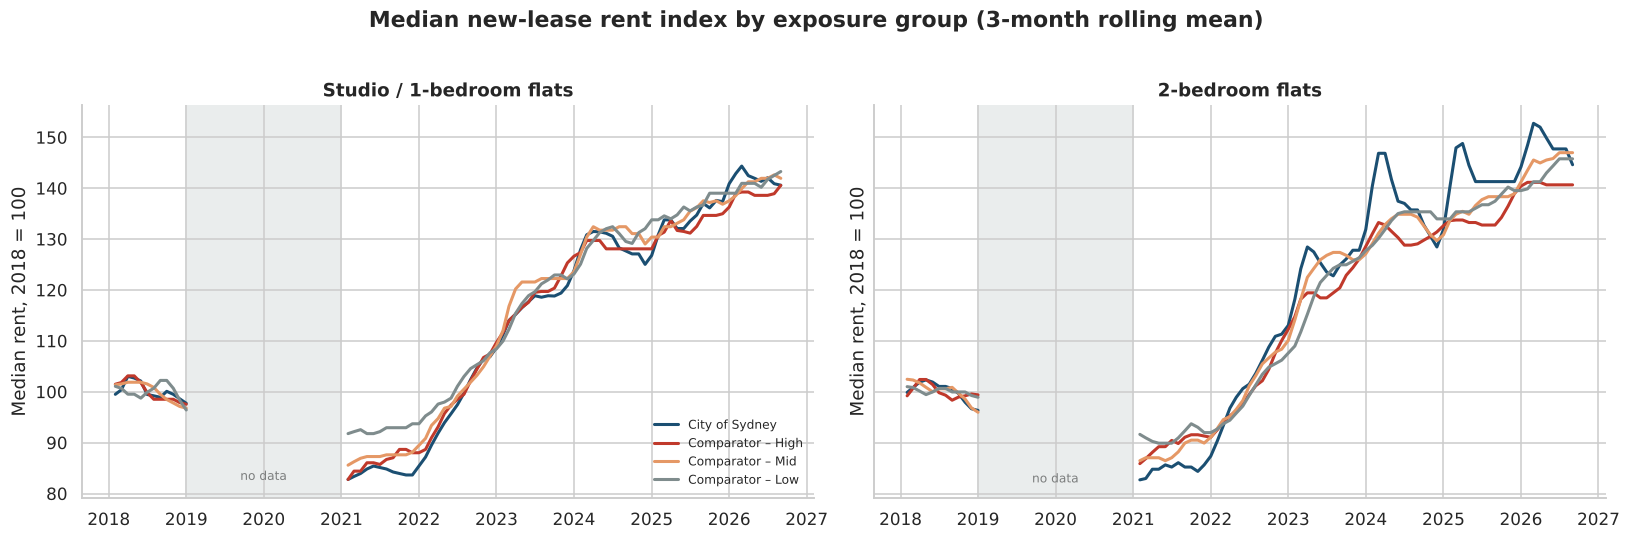

In [37]:
panel = panel.merge(elig[["poa", "group", "tier", "tier_E4"]], on="poa", how="left")
panel["month"] = panel.date.dt.to_period("M").dt.to_timestamp()
SEGS = ["f01", "f2"]
SEG_LABEL = {"f01": "Studio / 1-bedroom flats", "f2": "2-bedroom flats", "h34": "3–4 bedroom houses"}

grp_month = (panel[panel.seg.isin(SEGS) & panel.group.notna()]
             .groupby(["group", "seg", "month"]).rent.median().rename("med").reset_index())
all_months = pd.date_range("2018-01-01", "2026-09-01", freq="MS")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, seg in zip(axes, SEGS):
    for g, col in COLORS.items():
        s = (grp_month[(grp_month.group == g) & (grp_month.seg == seg)].set_index("month").med.reindex(all_months))
        idx = s / s["2018"].mean() * 100                        # time-series slicing by year string
        ax.plot(idx.index, idx.rolling(3, min_periods=2).mean(), color=col, lw=2, label=g)
    ax.axvspan(pd.Timestamp("2019-01-01"), pd.Timestamp("2020-12-31"), color="#eaeded", zorder=0)
    ax.text(pd.Timestamp("2019-12-31"), ax.get_ylim()[0] + 3, "no data", ha="center", fontsize=8, color="#7b7d7d")
    ax.set_title(SEG_LABEL[seg]); ax.set_ylabel("Median rent, 2018 = 100")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Median new-lease rent index by exposure group (3-month rolling mean)", y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()

## 4.2 Median weekly rent by phase (AUD)

The same medians are computed twice, once in pandas and once in SQL, and compared. This is the table that later comparisons are built on.

In [38]:
cell_pd = (panel[panel.seg.isin(SEGS + ["h34"])]
           .groupby(["poa", "seg", "phase"]).agg(n=("rent", "size"), med=("rent", "median")).reset_index())

cell_sql = duckdb.sql("""
    SELECT poa, seg, phase, count(*) AS n, median(rent) AS med
    FROM panel
    WHERE seg IN ('f01','f2','h34')
    GROUP BY poa, seg, phase
""").df()
chk = cell_pd.merge(cell_sql, on=["poa", "seg", "phase"], suffixes=("_pd", "_sql"), validate="1:1")
assert np.allclose(chk.med_pd, chk.med_sql) and (chk.n_pd == chk.n_sql).all()
print(f"pandas and SQL agree on {len(chk):,} postcode × segment × phase medians")

grp_phase = (panel[panel.seg.isin(SEGS) & panel.group.notna()]
             .groupby(["seg", "group", "phase"]).rent.median().unstack("phase")[list(PHASES)]
             .rename(columns=PHASE_LABEL).reindex(list(COLORS), level=1))
grp_phase

pandas and SQL agree on 3,618 postcode × segment × phase medians


phase                  2018 baseline  Closure (2021)  Recovery (2022–23)  Plateau (Jan 2024–Jun 2025)  Decline (Jul 2025–Sep 2026)
seg group                                                                                                                         
f01 City of Sydney            570.00          480.00              608.00                       749.00                       799.00
    Comparator – High         500.00          440.00              550.00                       650.00                       700.00
    Comparator – Mid          490.00          430.00              535.00                       650.00                       685.00
    Comparator – Low          430.00          400.00              470.00                       570.00                       600.00
f2  City of Sydney            780.00          650.00              890.00                     1,100.00                     1,150.00
    Comparator – High         680.00          600.00              750.00                       895.00                       947.50
    Comparator – Mid          580.00          510.00              650.00                       775.00                       830.00
    Comparator – Low          480.00          440.00              525.00                       650.00                       680.00

## 4.3 Finding for RQ1

In [39]:
LAST, CLOSURE = PHASE_LABEL["4_decline"], PHASE_LABEL["1_closure"]
cum = (grp_phase[LAST] / grp_phase["2018 baseline"] - 1) * 100
dip = (grp_phase[CLOSURE] / grp_phase["2018 baseline"] - 1) * 100
def span(s: pd.Series, what: str) -> str:
    """'a% to b% <what> across the groups', or 'about a% <what> in every group' when both ends round to the same value."""
    a, b = f"{s.min():+.0f}%", f"{s.max():+.0f}%"
    return f"about {a} {what} in every group" if a == b else f"{a} to {b} {what} across the groups"

lines = []
for seg in SEGS:
    c, d = cum.loc[seg], dip.loc[seg]
    lines.append(f"- **{SEG_LABEL[seg]}:** during closure the median new-lease rent was {span(d, 'versus 2018')}; "
                 f"in the decline phase (Jul 2025–Sep 2026) it was {span(c, 'above 2018')} "
                 f"(City of Sydney {c['City of Sydney']:+.1f}%, low-exposure comparators {c['Comparator – Low']:+.1f}%).")
md("**Key finding – RQ1.** Rents on newly signed flat leases fell in 2021 and then rose strongly in every group, so most of the movement is a "
   "market-wide cycle shared by high- and low-exposure areas.\n\n" + "\n".join(lines) +
   "\n\nGroup differences in the cumulative size of these movements are small compared with the common movement. The 2021 dip differed "
   "more between groups, and RQ3 examines that directly instead of reading the charts by eye.")

**Key finding – RQ1.** Rents on newly signed flat leases fell in 2021 and then rose strongly in every group, so most of the movement is a market-wide cycle shared by high- and low-exposure areas.

- **Studio / 1-bedroom flats:** during closure the median new-lease rent was -16% to -7% versus 2018 across the groups; in the decline phase (Jul 2025–Sep 2026) it was about +40% above 2018 in every group (City of Sydney +40.2%, low-exposure comparators +39.5%).
- **2-bedroom flats:** during closure the median new-lease rent was -17% to -8% versus 2018 across the groups; in the decline phase (Jul 2025–Sep 2026) it was +39% to +47% above 2018 across the groups (City of Sydney +47.4%, low-exposure comparators +41.7%).

Group differences in the cumulative size of these movements are small compared with the common movement. The 2021 dip differed more between groups, and RQ3 examines that directly instead of reading the charts by eye.

## 4.4 Seasonality: is there a student-calendar signature?

Student demand is concentrated around the start of the academic year (February–March, and to a lesser extent July). If campus-related demand
matters for new-lease rents, High-exposure postcodes might show a seasonal peak in those months that Low-exposure postcodes do not.

**Method.** For each tier and segment the monthly median rent is logged, the centred 12-month moving average (the trend) is subtracted, and the
remainder is averaged by calendar month. This needs a full year of context on each side, so the first and last six months drop out.

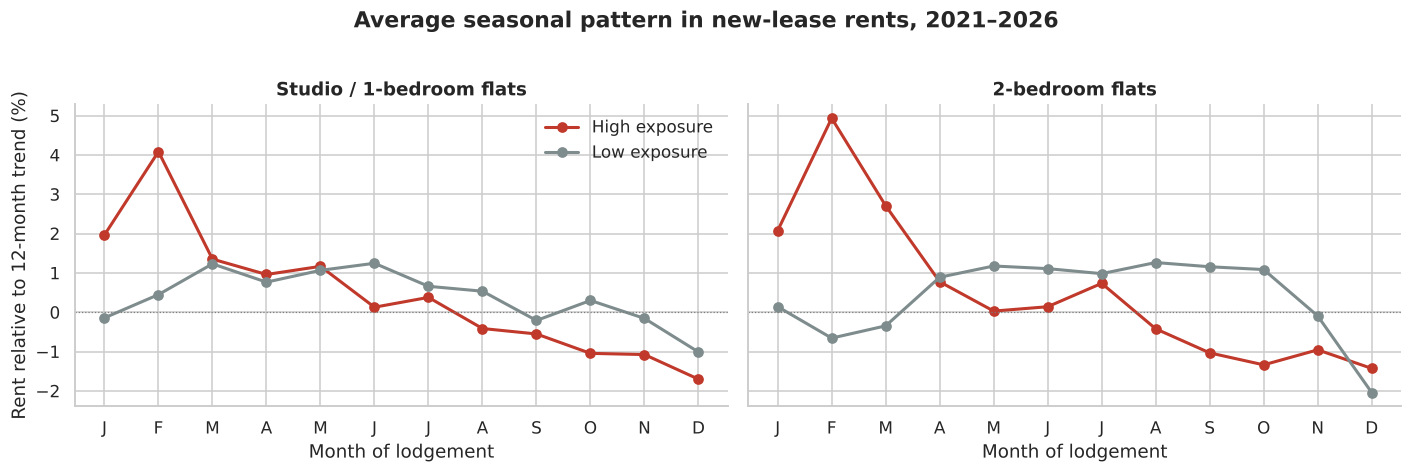

In [40]:
def detrended_seasonal(s: pd.Series) -> pd.Series:
    """Log monthly median minus its centred 12-month moving average, in percent."""
    ls = np.log(s)
    return (ls - ls.rolling(12, center=True, min_periods=12).mean()).dropna() * 100

post = panel[(panel.date >= "2021-01-01") & panel.tier.isin(["High", "Low"]) & panel.seg.isin(SEGS)]
tier_month = post.groupby(["tier", "seg", "month"], observed=True).rent.median()
seas = {}
for (tier, seg), ser in tier_month.groupby(level=[0, 1]):
    seas[(str(tier), seg)] = detrended_seasonal(ser.droplevel([0, 1]))
season_profile = pd.DataFrame({k: v.groupby(v.index.month).mean() for k, v in seas.items()})
season_profile.columns = pd.MultiIndex.from_tuples(season_profile.columns, names=["tier", "segment"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, seg in zip(axes, SEGS):
    for tier in ["High", "Low"]:
        ax.plot(season_profile.index, season_profile[(tier, seg)], marker="o", lw=2, color=TIER_COLORS[tier], label=f"{tier} exposure")
    ax.axhline(0, color="#7b7d7d", lw=0.8, ls=":")
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
    ax.set_title(SEG_LABEL[seg]); ax.set_xlabel("Month of lodgement")
axes[0].set_ylabel("Rent relative to 12-month trend (%)")
axes[0].legend(frameon=False)
fig.suptitle("Average seasonal pattern in new-lease rents, 2021–2026", y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()

**Is the February peak consistent from year to year?** The High-minus-Low difference in the detrended series is averaged over February–March for each year,
and compared with July–August as a reference period.

In [41]:
rows = []
for seg in SEGS:
    d = (seas[("High", seg)] - seas[("Low", seg)]).rename("gap")
    for yr, g in d.groupby(d.index.year):
        rows.append({"segment": seg, "year": yr,
                     "Feb–Mar gap (pp)": g[g.index.month.isin([2, 3])].mean(),
                     "Jul–Aug gap (pp)": g[g.index.month.isin([7, 8])].mean()})
season_years = pd.DataFrame(rows)
season_years.pivot(index="year", columns="segment", values=["Feb–Mar gap (pp)", "Jul–Aug gap (pp)"]).round(1)

Feb–Mar gap (pp)      Jul–Aug gap (pp)      
segment              f01   f2              f01    f2
year                                                
2021                 NaN  NaN            -1.10  1.00
2022               -0.10 1.80            -1.20 -2.30
2023                1.50 6.00            -1.70 -3.20
2024                3.40 4.70            -0.30 -0.80
2025                2.90 4.80             1.20  0.50
2026                1.70 4.30              NaN   NaN

In [42]:
k_pos = {seg: int((season_years[(season_years.segment == seg)]["Feb–Mar gap (pp)"].dropna() > 0).sum()) for seg in SEGS}
n_yrs = {seg: int(season_years[(season_years.segment == seg)]["Feb–Mar gap (pp)"].notna().sum()) for seg in SEGS}
feb = {(t, seg): season_profile.loc[2, (t, seg)] for t in ["High", "Low"] for seg in SEGS}
SEASON_TEXT = (f"Studio/1BR rents in High-exposure postcodes sit {feb[('High','f01')]:+.1f}% relative to trend in February, against {feb[('Low','f01')]:+.1f}% in Low-exposure postcodes; "
               f"for 2BR flats the figures are {feb[('High','f2')]:+.1f}% and {feb[('Low','f2')]:+.1f}%. The High-minus-Low February–March gap was positive in "
               f"{k_pos['f01']} of {n_yrs['f01']} years for studio/1BR and {k_pos['f2']} of {n_yrs['f2']} years for 2BR flats.")
md("**Key finding – seasonality.** " + SEASON_TEXT + " A February peak that appears in High- but not Low-exposure postcodes is consistent with demand "
   "tied to the start of the academic year. It is not proof: inner-city areas may also have a general summer-to-autumn leasing cycle, and only five annual "
   "cycles are available, so this is a lead to test with better data (for example term-address counts), not a conclusion.")

**Key finding – seasonality.** Studio/1BR rents in High-exposure postcodes sit +4.1% relative to trend in February, against +0.4% in Low-exposure postcodes; for 2BR flats the figures are +4.9% and -0.7%. The High-minus-Low February–March gap was positive in 4 of 5 years for studio/1BR and 5 of 5 years for 2BR flats. A February peak that appears in High- but not Low-exposure postcodes is consistent with demand tied to the start of the academic year. It is not proof: inner-city areas may also have a general summer-to-autumn leasing cycle, and only five annual cycles are available, so this is a lead to test with better data (for example term-address counts), not a conclusion.

# 5. RQ2 – Where did rents change most?

**Research question.** Which postcodes and corridors saw faster or slower rent growth?

## 5.1 Postcode-level changes

For each postcode and segment, the change between phases is measured as 100 × ln(median rent in phase B ÷ median rent in phase A), which is a
percentage change that is symmetric and comparable across rent levels. A postcode-segment contributes only if **both phases have at least
`MIN_N` bonds**; otherwise a median from a handful of leases would dominate the result. The same changes are also built under the visa-grant phases
for the sensitivity checks.

In [43]:
MIN_N = 30
TRANS = {"T0": ("0_base2018", "1_closure"), "T1": ("1_closure", "2_recovery"), "T2": ("2_recovery", "3_plateau"),
         "T3": ("3_plateau", "4_decline"), "CUM": ("0_base2018", "4_decline")}
TRANS_LABEL = {"T0": "2018 → closure", "T1": "closure → recovery", "T2": "recovery → plateau", "T3": "plateau → decline",
               "CUM": "2018 → decline (cumulative)"}
TRANS_FLOW = {"T0": ("0_base2018", "1_closure"), "T1": ("1_closure", "2_recovery"), "T2": ("2_recovery", "3_correction"),
              "T3": ("3_correction", "4_plateau_decline"), "CUM": ("0_base2018", "4_plateau_decline")}
TRANS_LABEL_FLOW = {"T0": "2018 → closure", "T1": "closure → recovery", "T2": "recovery → correction", "T3": "correction → plateau & decline",
                    "CUM": "2018 → plateau & decline (cumulative)"}
PRIMARY_WINDOWS = ["T1", "T2", "T3"]

def build_changes(cell: pd.DataFrame, min_n: int = MIN_N, trans: dict = TRANS) -> pd.DataFrame:
    """Percentage (log) change in median rent between phases, per postcode × segment, requiring ≥ min_n bonds in both phases."""
    med = cell.pivot(index=["poa", "seg"], columns="phase", values="med")
    n = cell.pivot(index=["poa", "seg"], columns="phase", values="n")
    parts = []
    for key, (a, b) in trans.items():
        ok = (n[a] >= min_n) & (n[b] >= min_n)
        parts.append((100 * np.log(med[b] / med[a])).where(ok).rename(key))
    out = pd.concat(parts, axis=1).reset_index().melt(id_vars=["poa", "seg"], var_name="trans", value_name="chg")
    return out.dropna(subset=["chg"])

ELIG_COLS = ["poa", "sa3", "sa4", "lga_dom", "city_of_sydney", "tier", "tier_E4", "group", "E2_rows_l3", "E3_dist_major_km", "E4"]
chg = build_changes(cell_pd).merge(elig[ELIG_COLS], on="poa", how="inner")
cell_flow = (panel[panel.seg.isin(SEGS + ["h34"])].groupby(["poa", "seg", "phase_flow"])
             .agg(n=("rent", "size"), med=("rent", "median")).reset_index().rename(columns={"phase_flow": "phase"}))
chg_flow = build_changes(cell_flow, trans=TRANS_FLOW).merge(elig[ELIG_COLS], on="poa", how="inner")
print(f"Postcode × segment × transition observations: {len(chg):,} (visa-grant phases: {len(chg_flow):,})")
print(chg.groupby(["seg", "trans"]).poa.nunique().unstack().loc[SEGS + ["h34"]].to_string())

Postcode × segment × transition observations: 1,734 (visa-grant phases: 1,729)
trans  CUM   T0   T1   T2   T3
seg                           
f01    116  116  117  117  117
f2     117  117  117  117  117
h34    111  111  113  116  115


## 5.2 Maps

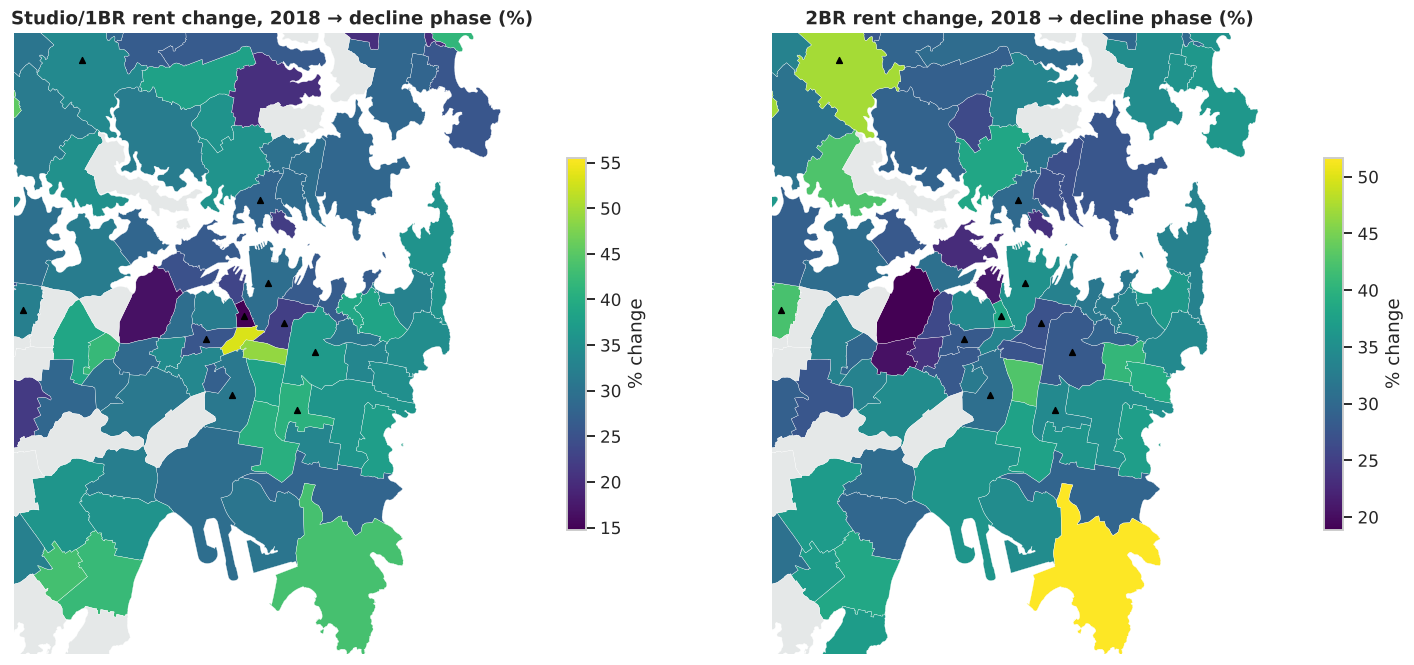

Grey areas have too few bonds in 2018 or in the decline phase for a reliable median.


In [44]:
cum_f01 = chg[(chg.seg == "f01") & (chg.trans == "CUM")][["poa", "chg"]].rename(columns={"chg": "cum_f01"})
cum_f2 = chg[(chg.seg == "f2") & (chg.trans == "CUM")][["poa", "chg"]].rename(columns={"chg": "cum_f2"})
map_gdf = poa_gdf.merge(cum_f01, on="poa", how="left").merge(cum_f2, on="poa", how="left")

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
draw_map(axes[0], map_gdf, "cum_f01", "Studio/1BR rent change, 2018 → decline phase (%)", cmap="viridis", bbox=inner, points=cam_pts, legend_label="% change")
draw_map(axes[1], map_gdf, "cum_f2", "2BR rent change, 2018 → decline phase (%)", cmap="viridis", bbox=inner, points=cam_pts, legend_label="% change")
plt.tight_layout()
plt.show()
print("Grey areas have too few bonds in 2018 or in the decline phase for a reliable median.")

## 5.3 Corridors (SA3 neighbourhoods)

SA3 regions are used as neighbourhood "corridors": they are large enough to hold several postcodes and small enough to keep local character.

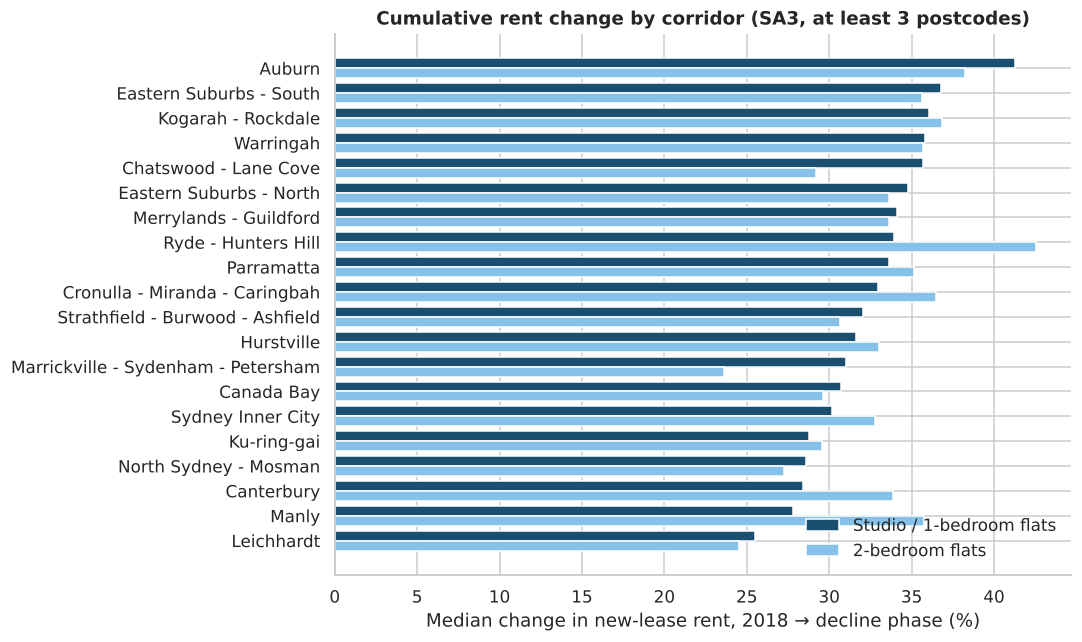

In [45]:
corr = (chg[(chg.trans == "CUM") & chg.seg.isin(SEGS)]
        .groupby(["sa3", "seg"]).agg(postcodes=("poa", "nunique"), median_chg=("chg", "median")).reset_index()
        .pivot(index="sa3", columns="seg", values=["postcodes", "median_chg"]))
corr.columns = [f"{a}_{b}" for a, b in corr.columns]
corr = corr[corr.postcodes_f01 >= 3].sort_values("median_chg_f01", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(corr))
ax.barh(y - 0.2, corr.median_chg_f01, height=0.4, color="#1b4f72", label=SEG_LABEL["f01"])
ax.barh(y + 0.2, corr.median_chg_f2, height=0.4, color="#85c1e9", label=SEG_LABEL["f2"])
ax.set_yticks(y); ax.set_yticklabels(corr.index); ax.invert_yaxis()
ax.set_xlabel("Median change in new-lease rent, 2018 → decline phase (%)")
ax.set_title("Cumulative rent change by corridor (SA3, at least 3 postcodes)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5.4 Finding for RQ2

In [46]:
top = corr.median_chg_f01.idxmax(); bot = corr.median_chg_f01.idxmin()
inner_name = "Sydney Inner City"
inner_row = corr.loc[inner_name] if inner_name in corr.index else None
txt = (f"Across {len(corr)} corridors, the median cumulative change in studio/1BR new-lease rent from 2018 to the decline phase "
       f"ranges from {corr.median_chg_f01.min():+.0f}% ({bot}) to {corr.median_chg_f01.max():+.0f}% ({top}).")
if inner_row is not None:
    rank = int((corr.median_chg_f01 > inner_row.median_chg_f01).sum() + 1)
    txt += (f" The Sydney Inner City corridor, which contains most City of Sydney postcodes, changed by {inner_row.median_chg_f01:+.0f}% "
            f"(rank {rank} of {len(corr)}).")
md("**Key finding – RQ2.** " + txt + " Rent growth is geographically widespread, not confined to the campus areas. Whether the spread across "
   "corridors lines up with exposure is tested next.")

**Key finding – RQ2.** Across 20 corridors, the median cumulative change in studio/1BR new-lease rent from 2018 to the decline phase ranges from +26% (Leichhardt) to +41% (Auburn). The Sydney Inner City corridor, which contains most City of Sydney postcodes, changed by +30% (rank 15 of 20). Rent growth is geographically widespread, not confined to the campus areas. Whether the spread across corridors lines up with exposure is tested next.

# 6. RQ3 – Is exposure associated with different rent growth?

**Research question.** Among comparable flat-heavy postcodes, do those with High exposure show different rent growth than those with Low exposure?

**Method.**
- **Gap:** median change in the High tier minus median change in the Low tier, in percentage points. Tiers are drawn from E2 (campus-based) and from E4 (Census).
- **Segments:** studio/1BR and 2BR flats, plus 3–4BR houses as a placebo.
- **Uncertainty:** neighbouring postcodes share local conditions, so a postcode-level bootstrap would be too optimistic. Instead the bootstrap
  **resamples whole SA3 corridors** (2,000 times) and reports a 90% interval.
- **Rank correlation:** Spearman ρ between the exposure measure and the change, across all eligible postcodes.
- **Naive permutation p-value:** shown for reference only; it ignores spatial dependence and is therefore optimistic.

In [47]:
N_BOOT = 2000
TIERINGS = {"E2": ("tier", "E2_rows_l3"), "E4": ("tier_E4", "E4")}          # tier column, exposure column

def tier_gap_arrays(vals: np.ndarray, tiers: np.ndarray) -> float:
    """High-minus-Low gap in medians; NaN if either tier has fewer than 3 postcodes."""
    hi, lo = vals[tiers == "High"], vals[tiers == "Low"]
    return np.median(hi) - np.median(lo) if len(hi) >= 3 and len(lo) >= 3 else np.nan

def cluster_bootstrap(d: pd.DataFrame, stat, tier_col: str = "tier", expo_col: str = "E2_rows_l3", cluster: str = "sa3",
                      n_boot: int = N_BOOT, seed: int = SEED):
    """Resample whole clusters with replacement; return the 5th/95th percentiles of `stat(values, tiers, exposure)`."""
    rng = np.random.default_rng(seed)
    parts = [(g.chg.to_numpy(), g[tier_col].astype(str).to_numpy(), g[expo_col].to_numpy()) for _, g in d.groupby(cluster)]
    reps = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(parts), len(parts))
        v = np.concatenate([parts[i][0] for i in pick]); t = np.concatenate([parts[i][1] for i in pick]); e = np.concatenate([parts[i][2] for i in pick])
        s = stat(v, t, e)
        if np.isfinite(s):
            reps.append(s)
    return (np.percentile(reps, 5), np.percentile(reps, 95)) if len(reps) >= 200 else (np.nan, np.nan)

def rho_stat(v, t, e) -> float:
    return stats.spearmanr(e, v).statistic if len(v) > 10 and np.std(e) > 0 else np.nan

def gap_stat(v, t, e) -> float:
    return tier_gap_arrays(v, t)

def permutation_p(d: pd.DataFrame, expo_col: str = "E2_rows_l3", n_perm: int = 5000, seed: int = SEED) -> float:
    """Two-sided naive permutation p-value for Spearman rho (shuffles exposure across postcodes)."""
    rng = np.random.default_rng(seed)
    obs = stats.spearmanr(d[expo_col], d.chg).statistic
    e = d[expo_col].to_numpy(); v = d.chg.to_numpy()
    perm = np.array([stats.spearmanr(rng.permutation(e), v).statistic for _ in range(n_perm)])
    return float((np.abs(perm) >= abs(obs)).mean())

def tier_results(chg_df: pd.DataFrame, trans: dict = TRANS, segs: list = SEGS + ["h34"], full: bool = True) -> pd.DataFrame:
    """High−Low gap with its cluster-bootstrap interval for every tiering × segment × window (plus ρ and permutation p if `full`)."""
    rows = []
    for name, (tcol, ecol) in TIERINGS.items():
        for seg in segs:
            for tr in trans:
                d = chg_df[(chg_df.seg == seg) & (chg_df.trans == tr)]
                lo, hi = cluster_bootstrap(d, gap_stat, tcol, ecol)
                row = {"tiering": name, "seg": seg, "trans": tr, "n_postcodes": len(d), "n_High": int((d[tcol] == "High").sum()),
                       "n_Low": int((d[tcol] == "Low").sum()), "gap_pp": tier_gap_arrays(d.chg.to_numpy(), d[tcol].astype(str).to_numpy()),
                       "gap_lo": lo, "gap_hi": hi}
                if full:
                    rlo, rhi = cluster_bootstrap(d, rho_stat, tcol, ecol, n_boot=1000)
                    row.update(rho=stats.spearmanr(d[ecol], d.chg).statistic, rho_lo=rlo, rho_hi=rhi, p_perm_naive=permutation_p(d, ecol, 2000))
                rows.append(row)
    out = pd.DataFrame(rows)
    out["excludes_0"] = (out.gap_lo > 0) | (out.gap_hi < 0)
    return out

res = tier_results(chg)
res_show = res.assign(window=res.trans.map(TRANS_LABEL))[["tiering", "seg", "window", "n_postcodes", "n_High", "n_Low", "gap_pp", "gap_lo", "gap_hi",
                                                          "rho", "rho_lo", "rho_hi", "p_perm_naive", "excludes_0"]]
res_show[res_show.seg.isin(SEGS)].round(2)

,tiering,seg,window,n_postcodes,n_High,n_Low,gap_pp,gap_lo,gap_hi,rho,rho_lo,rho_hi,p_perm_naive,excludes_0
0,E2,f01,2018 → closure,116,39,38,-10.67,-14.04,-5.23,-0.56,-0.72,-0.36,0.00,True
1,E2,f01,closure → recovery,117,39,39,9.95,7.30,12.82,0.54,0.36,0.66,0.00,True
2,E2,f01,recovery → plateau,117,39,39,-3.73,-5.37,1.53,-0.11,-0.29,0.14,0.24,False
3,E2,f01,plateau → decline,117,39,39,-0.03,-0.96,1.96,0.08,-0.09,0.24,0.38,False
4,E2,f01,2018 → decline (cumulative),116,39,38,-2.74,-6.70,0.47,-0.19,-0.38,-0.01,0.03,False
5,E2,f2,2018 → closure,117,39,39,-4.51,-14.57,2.53,-0.32,-0.56,-0.02,0.00,False
6,E2,f2,closure → recovery,117,39,39,3.41,-0.89,8.73,0.35,0.05,0.59,0.00,False
7,E2,f2,recovery → plateau,117,39,39,-2.83,-5.74,-0.73,-0.23,-0.45,-0.04,0.00,True
8,E2,f2,plateau → decline,117,39,39,-0.93,-2.07,1.00,-0.06,-0.24,0.15,0.54,False
9,E2,f2,2018 → decline (cumulative),117,39,39,-4.16,-7.60,-0.99,-0.30,-0.47,-0.16,0.00,True


## 6.1 Distribution of changes by tier (E2 tiers)

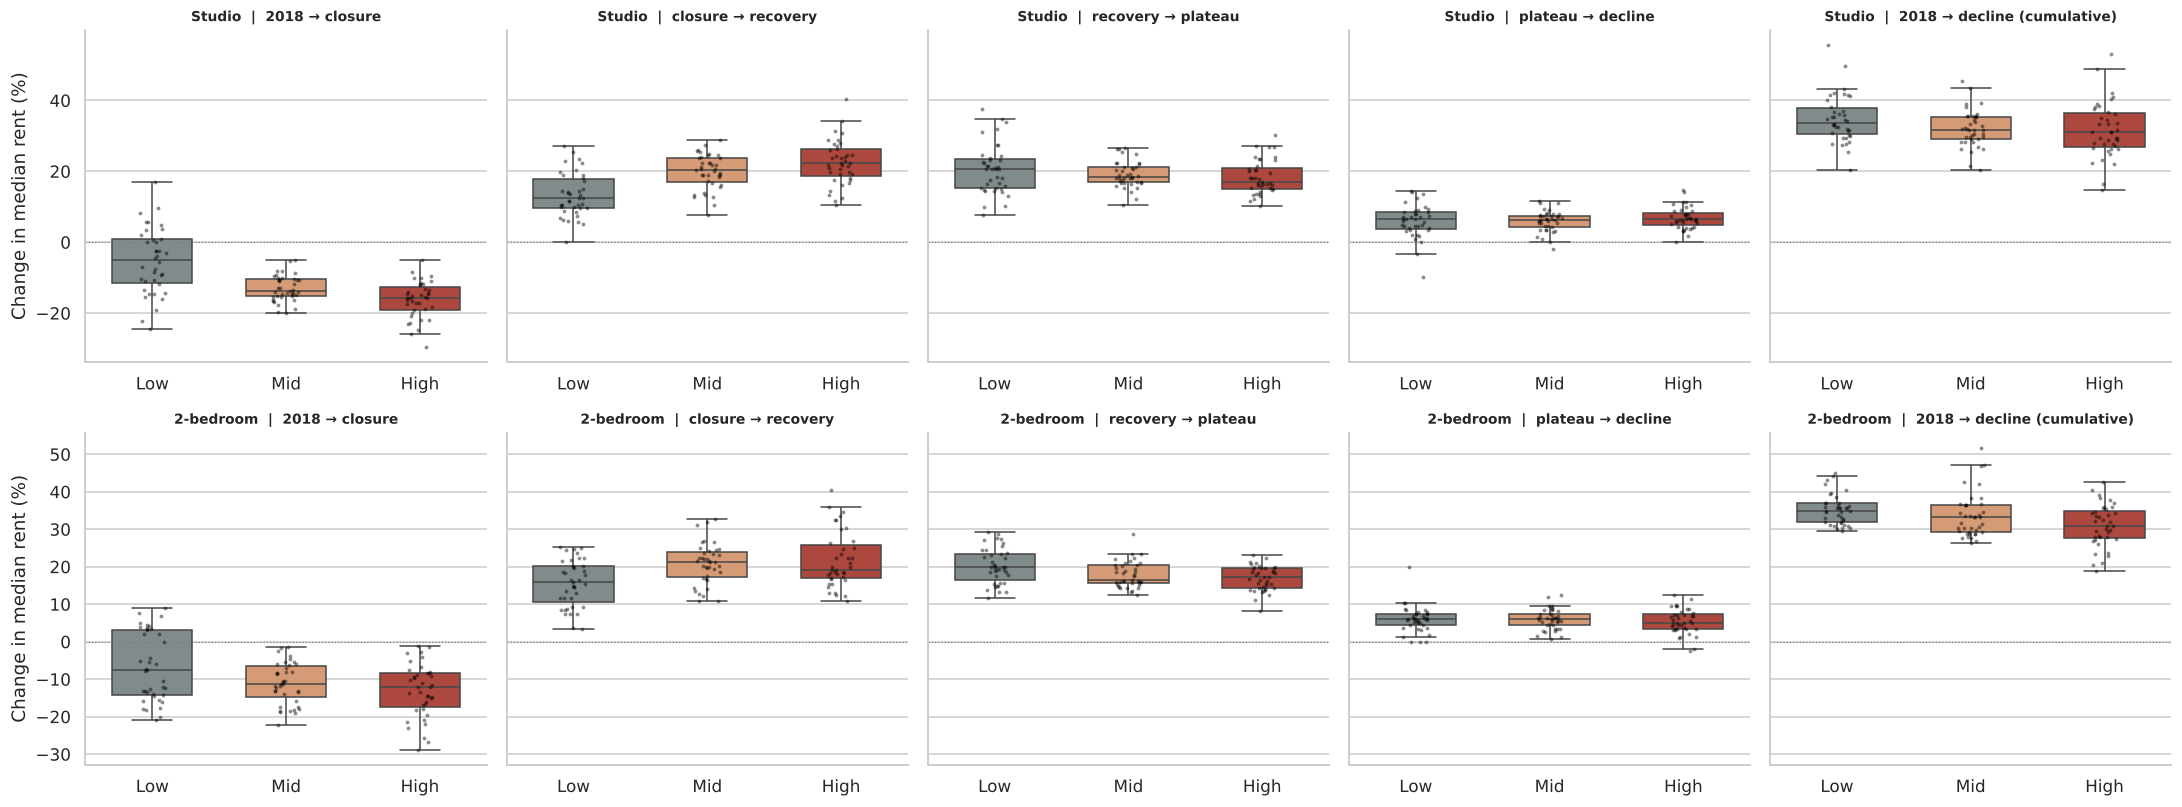

Every postcode is drawn as a point, so the box whiskers do not need to show outliers separately.


In [48]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5), sharey="row")
for i, seg in enumerate(SEGS):
    for j, tr in enumerate(TRANS):
        ax = axes[i, j]
        d = chg[(chg.seg == seg) & (chg.trans == tr)]
        sns.boxplot(data=d, x="tier", y="chg", order=["Low", "Mid", "High"], palette=TIER_COLORS, showfliers=False, ax=ax, width=0.6)
        sns.stripplot(data=d, x="tier", y="chg", order=["Low", "Mid", "High"], color="black", size=2.5, alpha=0.45, ax=ax)
        ax.axhline(0, color="#7b7d7d", lw=0.8, ls=":")
        ax.set_title(f"{SEG_LABEL[seg].split(' ')[0]}  |  {TRANS_LABEL[tr]}", fontsize=9)
        ax.set_xlabel(""); ax.set_ylabel("Change in median rent (%)" if j == 0 else "")
plt.tight_layout()
plt.show()
print("Every postcode is drawn as a point, so the box whiskers do not need to show outliers separately.")

## 6.2 Exposure against change

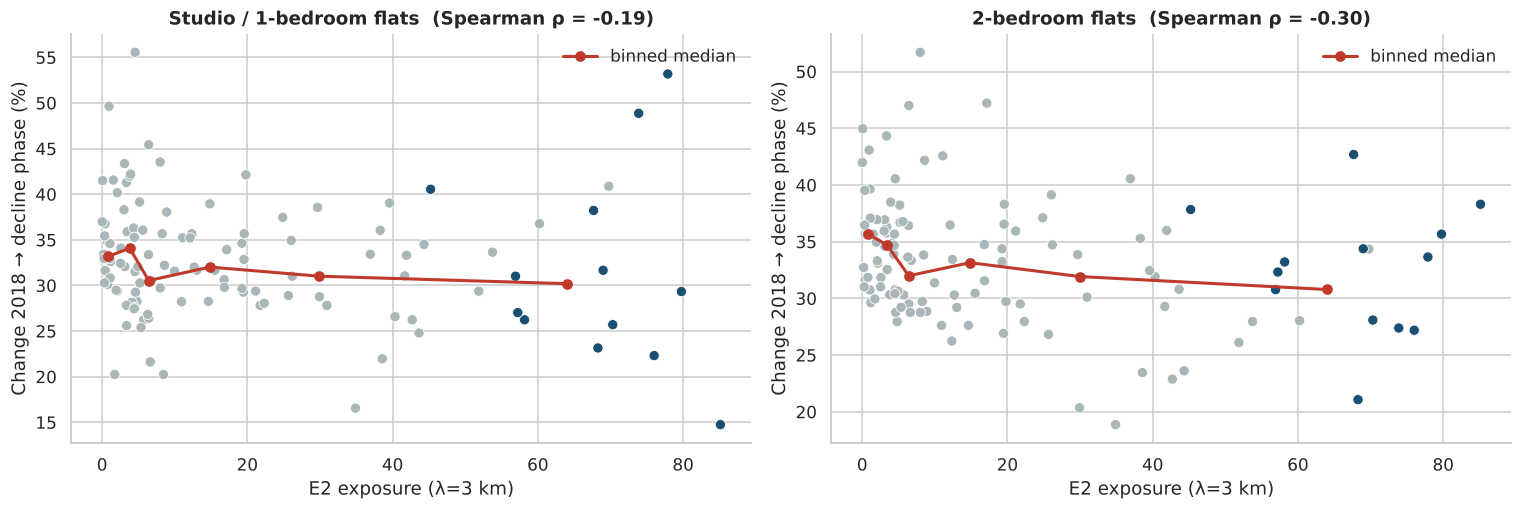

Dark blue points are City of Sydney postcodes.


In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, seg in zip(axes, SEGS):
    d = chg[(chg.seg == seg) & (chg.trans == "CUM")].copy()
    sns.scatterplot(data=d, x="E2_rows_l3", y="chg", hue="city_of_sydney", palette={True: "#1b4f72", False: "#aab7b8"}, s=45, ax=ax, legend=False)
    d["bin"] = pd.qcut(d.E2_rows_l3, 6, duplicates="drop")
    bins = d.groupby("bin", observed=True).agg(x=("E2_rows_l3", "median"), y=("chg", "median"))
    ax.plot(bins.x, bins.y, color="#c0392b", marker="o", lw=2, label="binned median")
    rho = res[(res.tiering == "E2") & (res.seg == seg) & (res.trans == "CUM")].rho.iloc[0]
    ax.set_title(f"{SEG_LABEL[seg]}  (Spearman ρ = {rho:+.2f})")
    ax.set_xlabel("E2 exposure (λ=3 km)"); ax.set_ylabel("Change 2018 → decline phase (%)")
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()
print("Dark blue points are City of Sydney postcodes.")

## 6.3 Does the signal differ between small flats and 2-bedroom flats?

If student demand mattered specifically, the High-minus-Low gap should be larger for studio/1BR than for 2BR flats. For each postcode the difference
between its studio/1BR change and its 2BR change is computed, then compared across tiers.

In [50]:
wide = chg[chg.seg.isin(SEGS)].pivot_table(index=["poa", "trans"], columns="seg", values="chg").dropna().reset_index()
wide["chg"] = wide.f01 - wide.f2
wide = wide.merge(elig[["poa", "sa3", "tier", "tier_E4", "E2_rows_l3", "E4", "city_of_sydney"]], on="poa")
contrast = []
for name, (tcol, ecol) in TIERINGS.items():
    for tr in TRANS:
        d = wide[wide.trans == tr]
        lo, hi = cluster_bootstrap(d, gap_stat, tcol, ecol)
        contrast.append({"tiering": name, "trans": tr, "window": TRANS_LABEL[tr], "n_postcodes": len(d),
                         "gap_pp (f01 − f2)": tier_gap_arrays(d.chg.to_numpy(), d[tcol].astype(str).to_numpy()), "lo": lo, "hi": hi})
contrast = pd.DataFrame(contrast)
contrast["excludes_0"] = (contrast.lo > 0) | (contrast.hi < 0)
contrast.drop(columns="trans").round(2)

,tiering,window,n_postcodes,gap_pp (f01 − f2),lo,hi,excludes_0
0,E2,2018 → closure,116,-3.36,-6.08,-0.35,True
1,E2,closure → recovery,117,2.63,0.74,5.38,True
2,E2,recovery → plateau,117,0.18,-2.88,4.26,False
3,E2,plateau → decline,117,1.08,-0.60,3.07,False
4,E2,2018 → decline (cumulative),116,0.30,-2.99,3.18,False
5,E4,2018 → closure,116,2.72,0.65,4.50,True
6,E4,closure → recovery,117,-0.39,-3.22,1.35,False
7,E4,recovery → plateau,117,-0.77,-3.56,2.22,False
8,E4,plateau → decline,117,1.30,0.28,2.79,True
9,E4,2018 → decline (cumulative),116,2.63,-1.19,5.11,False


## 6.4 Placebo: 3–4 bedroom houses, and the main result in one chart

Students rarely rent 3–4 bedroom houses. If a High-minus-Low gap also appears for houses in the same postcodes, it describes those areas in general,
not student demand. The chart shows the gap and its 90% interval for every window, segment and exposure measure.

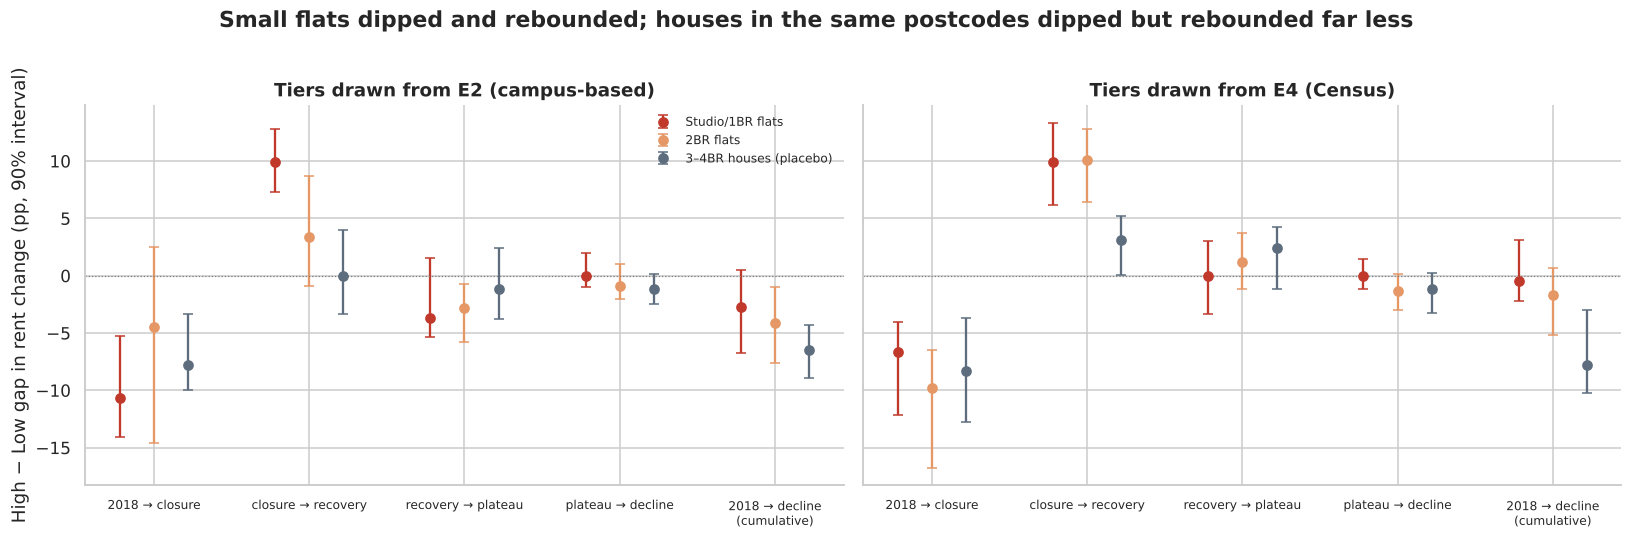

In [51]:
SEG_STYLE = {"f01": ("#c0392b", "Studio/1BR flats"), "f2": ("#e59866", "2BR flats"), "h34": ("#5d6d7e", "3–4BR houses (placebo)")}
rebound = res[res.trans.eq("T1")].pivot(index="tiering", columns="seg", values="gap_pp")
dip_gap = res[res.trans.eq("T0")].pivot(index="tiering", columns="seg", values="gap_pp")
chart_title = ("Small flats dipped and rebounded; houses in the same postcodes dipped but rebounded far less"
               if ((rebound.h34 < 0.5 * rebound.f01) & (dip_gap.h34 < 0) & (rebound.f01 > 0)).all()
               else "High − Low gap by window, segment and exposure measure")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
x = np.arange(len(TRANS))
for ax, name in zip(axes, TIERINGS):
    for k, (seg, (col, lab)) in enumerate(SEG_STYLE.items()):
        r = res[(res.tiering == name) & (res.seg == seg)].set_index("trans").loc[list(TRANS)]
        ax.errorbar(x + (k - 1) * 0.22, r.gap_pp, yerr=[r.gap_pp - r.gap_lo, r.gap_hi - r.gap_pp], fmt="o", color=col, capsize=3, label=lab)
    ax.axhline(0, color="#7b7d7d", lw=0.8, ls=":")
    ax.set_xticks(x); ax.set_xticklabels([TRANS_LABEL[t].replace(" (", "\n(") for t in TRANS], fontsize=8)
    ax.set_title(f"Tiers drawn from {name} ({'campus-based' if name == 'E2' else 'Census'})")
axes[0].set_ylabel("High − Low gap in rent change (pp, 90% interval)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(chart_title, y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()

In [52]:
def fx(x: float, d: int = 1) -> str:
    """Signed number with d decimals, without a '-0.0' artefact."""
    return f"{0.0 if abs(x) < 0.5 * 10 ** -d else x:+.{d}f}"

def ci_txt(r) -> str:
    return f"{fx(r.gap_pp)} pp [{fx(r.gap_lo)}, {fx(r.gap_hi)}]"

rr = res.set_index(["tiering", "seg", "trans"])
DIP_SHARED = bool(res[(res.seg == "h34") & (res.trans == "T0")].pipe(lambda d: (d.gap_pp < 0) & d.excludes_0).all())
REBOUND_FLATS = bool(((rebound.h34 < 0.5 * rebound.f01) & (rebound.f01 > 0)).all())
placebo_read = (("Houses in High-exposure postcodes fell about as far as small flats during the closure, so **the dip was a shock to those areas as a whole** "
                 "(inner-city demand in general), not something specific to the rental segment students use. " if DIP_SHARED else
                 "Houses did not share the closure dip under every tiering, so the dip cannot be read as an area-wide shock. ")
                + ("The **rebound was much larger for small flats** than for houses, so it is the part of the pattern that is at least consistent with a return "
                   "of student or other young-renter demand." if REBOUND_FLATS else "The rebound was not clearly larger for flats than for houses."))
md("**Placebo reading.** "
   + " ".join(f"With {t} tiers, studio/1BR flats: {ci_txt(rr.loc[(t, 'f01', 'T0')])} in 2018 → closure and {ci_txt(rr.loc[(t, 'f01', 'T1')])} in closure → recovery; "
              f"3–4BR houses: {ci_txt(rr.loc[(t, 'h34', 'T0')])} and {ci_txt(rr.loc[(t, 'h34', 'T1')])}." for t in TIERINGS)
   + " " + placebo_read)

**Placebo reading.** With E2 tiers, studio/1BR flats: -10.7 pp [-14.0, -5.2] in 2018 → closure and +10.0 pp [+7.3, +12.8] in closure → recovery; 3–4BR houses: -7.8 pp [-10.0, -3.4] and +0.0 pp [-3.3, +4.0]. With E4 tiers, studio/1BR flats: -6.6 pp [-12.2, -4.1] in 2018 → closure and +10.0 pp [+6.2, +13.3] in closure → recovery; 3–4BR houses: -8.3 pp [-12.7, -3.7] and +3.1 pp [+0.1, +5.2]. Houses in High-exposure postcodes fell about as far as small flats during the closure, so **the dip was a shock to those areas as a whole** (inner-city demand in general), not something specific to the rental segment students use. The **rebound was much larger for small flats** than for houses, so it is the part of the pattern that is at least consistent with a return of student or other young-renter demand.

## 6.5 Were the groups already diverging before COVID? (DCJ rent tables, 2018–2022)

The bond files skip 2019–2020, so they cannot show whether High- and Low-exposure postcodes were on different paths **before** the border closure.
The DCJ rent tables fill those years with **quarterly medians** built from the same bonds, for flats with 1 bedroom and with 2 bedrooms (DCJ's
"Bedsitter" category cannot be merged with them, so studios are left out). They are used as a separate check and are not spliced onto the bond medians.
Cells with 10 or fewer bonds are hidden. First, DCJ is compared with our own medians in the quarters both cover: this also checks the 2018 mirror file
against the official series.

In [53]:
dcj_f = (dcj[(dcj.dwelling_type == "Flat/Unit") & dcj.bedrooms.isin(["1 Bedroom", "2 Bedrooms"]) & dcj.poa.isin(elig.poa)]
         .merge(elig[["poa", "sa3", "tier", "tier_E4", "E2_rows_l3", "E4"]], on="poa", validate="m:1"))
dcj_f["q"] = pd.PeriodIndex(dcj_f.quarter, freq="Q")
dcj_f["year"] = dcj_f.q.dt.year
dcj_f["lm"] = 100 * np.log(dcj_f.rent_median)

own = (panel[(panel.dwelling == "F") & panel.bedrooms.isin([1, 2]) & panel.poa.isin(elig.poa)]
       .assign(quarter=lambda d: d.date.dt.to_period("Q").astype(str), bedrooms=lambda d: d.bedrooms.map({1: "1 Bedroom", 2: "2 Bedrooms"}))
       .groupby(["poa", "quarter", "bedrooms"]).rent.median().rename("own_median").reset_index())
xc = dcj_f.merge(own, on=["poa", "quarter", "bedrooms"], validate="1:1").dropna(subset=["rent_median"])
dcj_agree = xc.groupby("year").apply(lambda g: pd.Series({
    "cells": len(g), "correlation": np.corrcoef(g.own_median, g.rent_median)[0, 1],
    "identical %": (g.own_median == g.rent_median).mean() * 100, "within $10 %": ((g.own_median - g.rent_median).abs() <= 10).mean() * 100}))
coverage = (dcj_f[dcj_f.year <= 2020].assign(published=lambda d: d.rent_median.notna())
            .groupby(["bedrooms", "tier"], observed=True).published.mean().unstack().mul(100))
display(dcj_agree.round(3), coverage.round(0).rename_axis(columns="E2 tier: % of 2018–2020 quarters with a published median"))

,cells,correlation,identical %,within $10 %
year,,,,
2018,906.00,1.00,64.24,91.61
2021,927.00,1.00,70.55,96.01
2022,908.00,1.00,57.16,85.90


E2 tier: % of 2018–2020 quarters with a published median,Low,Mid,High
bedrooms,,,
1 Bedroom,87.00,97.00,99.00
2 Bedrooms,100.00,100.00,100.00


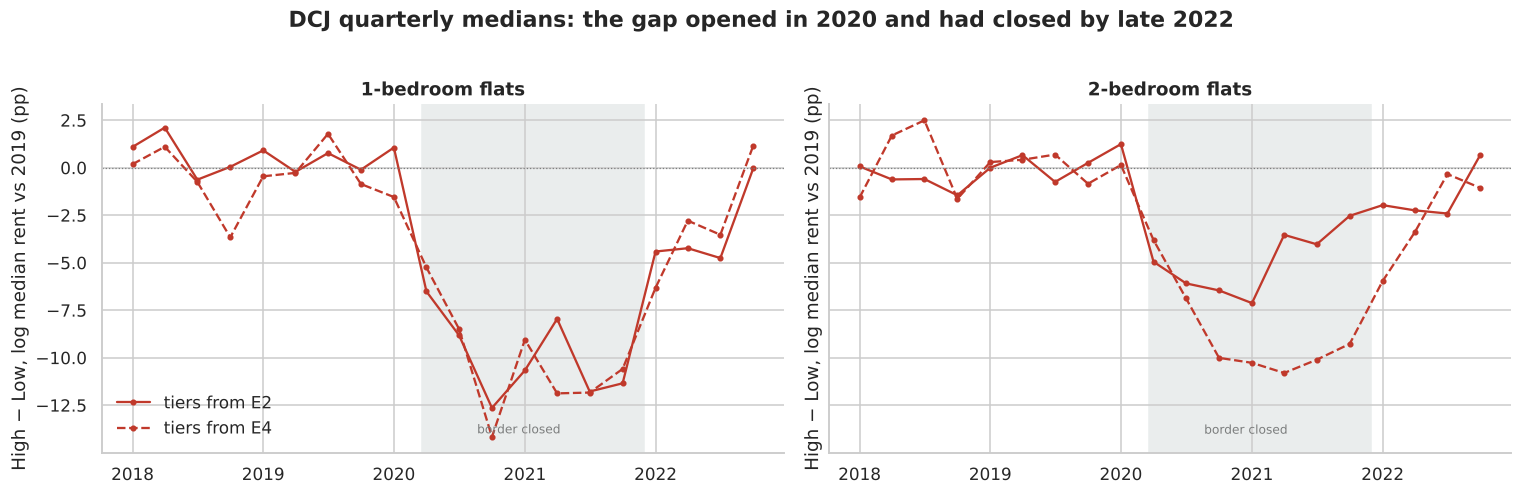

In [54]:
def quarterly_gap(d: pd.DataFrame, tier_col: str) -> pd.Series:
    """High-minus-Low gap, by quarter, in log median rent relative to each postcode's 2019 level (pp)."""
    p = d.pivot_table(index="poa", columns="q", values="lm")
    rel = p.sub(p[[c for c in p.columns if c.year == 2019]].median(axis=1), axis=0)
    t = d.drop_duplicates("poa").set_index("poa")[tier_col].astype(str).reindex(rel.index)
    return rel[t == "High"].median() - rel[t == "Low"].median()

BEDS = {"1 Bedroom": "1-bedroom flats", "2 Bedrooms": "2-bedroom flats"}
qgap = {(b, name): quarterly_gap(dcj_f[dcj_f.bedrooms == b], tcol) for b in BEDS for name, (tcol, _) in TIERINGS.items()}
opened = all(s[s.index.year == 2020].min() < -4 for s in qgap.values())
closed = all(abs(s.iloc[-1]) < 2 for s in qgap.values())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, b in zip(axes, BEDS):
    for name, ls in [("E2", "-"), ("E4", "--")]:
        s = qgap[(b, name)]
        ax.plot(pd.PeriodIndex(s.index).to_timestamp(), s.values, ls, marker="o", ms=3, color="#c0392b", label=f"tiers from {name}")
    ax.axvspan(pd.Timestamp("2020-03-20"), pd.Timestamp("2021-11-30"), color="#eaeded", zorder=0)
    ax.text(pd.Timestamp("2020-12-15"), ax.get_ylim()[0] + 1, "border closed", ha="center", fontsize=8, color="#7b7d7d")
    ax.axhline(0, color="#7b7d7d", lw=0.8, ls=":")
    ax.set_title(BEDS[b]); ax.set_ylabel("High − Low, log median rent vs 2019 (pp)")
axes[0].legend(frameon=False)
fig.suptitle("DCJ quarterly medians: the gap opened in 2020 and had closed by late 2022" if opened and closed
             else "DCJ quarterly medians: High − Low gap by quarter", y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()

**Pre-COVID trend test.** For each postcode, the trend in log median rent over the eight quarters 2018Q1–2019Q4 (pp per year) is estimated by least squares,
requiring at least six published quarters; the High-minus-Low gap in median trends gets a cluster-bootstrap interval. The balanced version keeps only postcodes
with all eight quarters published, because hidden cells are more common in Low-tier postcodes. A single regression slope is used rather than year-on-year
comparisons, whose result depends on how each year is summarised (mean, median or one quarter).

In [55]:
def pre_covid_slopes(d: pd.DataFrame, min_q: int = 6) -> pd.Series:
    """Least-squares slope of 100·log(median rent) on time (years), 2018Q1–2019Q4, per postcode with ≥ min_q published quarters."""
    x = d[(d.q <= pd.Period("2019Q4", freq="Q")) & d.lm.notna()].copy()
    x["t"] = x.q.dt.year + (x.q.dt.quarter - 1) / 4
    x["tc"] = x.t - x.groupby("poa").t.transform("mean")
    x["yc"] = x.lm - x.groupby("poa").lm.transform("mean")
    slope = (x.tc * x.yc).groupby(x.poa).sum() / (x.tc ** 2).groupby(x.poa).sum()
    return slope[x.groupby("poa").size() >= min_q].rename("chg")

pre_rows = []
for b in BEDS:
    for min_q, version in [(6, "≥6 of 8 quarters"), (8, "balanced: all 8 quarters")]:
        sl = pre_covid_slopes(dcj_f[dcj_f.bedrooms == b], min_q).reset_index().merge(elig[["poa", "sa3", "tier", "tier_E4", "E2_rows_l3", "E4"]], on="poa")
        for name, (tcol, ecol) in TIERINGS.items():
            lo_, hi_ = cluster_bootstrap(sl, gap_stat, tcol, ecol)
            pre_rows.append({"flats": BEDS[b], "postcodes": version, "tiering": name, "n": len(sl),
                             "trend_gap_pp_per_yr": tier_gap_arrays(sl.chg.to_numpy(), sl[tcol].astype(str).to_numpy()), "lo": lo_, "hi": hi_})
pre_tab = pd.DataFrame(pre_rows)
pre_tab["excludes_0"] = (pre_tab.lo > 0) | (pre_tab.hi < 0)
pre_tab.round(2)

,flats,postcodes,tiering,n,trend_gap_pp_per_yr,lo,hi,excludes_0
0,1-bedroom flats,≥6 of 8 quarters,E2,109,-1.24,-3.08,-0.06,True
1,1-bedroom flats,≥6 of 8 quarters,E4,109,-0.42,-1.34,0.55,False
2,1-bedroom flats,balanced: all 8 quarters,E2,97,-1.42,-3.46,-0.31,True
3,1-bedroom flats,balanced: all 8 quarters,E4,97,0.08,-1.19,1.38,False
4,2-bedroom flats,≥6 of 8 quarters,E2,117,0.34,-0.67,1.02,False
5,2-bedroom flats,≥6 of 8 quarters,E4,117,0.12,-1.53,0.82,False
6,2-bedroom flats,balanced: all 8 quarters,E2,117,0.34,-0.67,1.02,False
7,2-bedroom flats,balanced: all 8 quarters,E4,117,0.12,-1.53,0.82,False


In [56]:
g1 = qgap[("1 Bedroom", "E2")]
worst_q, worst_v = g1.idxmin(), g1.min()
main_pre = pre_tab[pre_tab.postcodes.str.startswith("≥6")].set_index(["flats", "tiering"])
max_abs = pre_tab.trend_gap_pp_per_yr.abs().max()
drift = main_pre.loc[("1-bedroom flats", "E2"), "trend_gap_pp_per_yr"]
t0_e2 = rr.loc[("E2", "f01", "T0"), "gap_pp"]
n_pre_sig = int(pre_tab.excludes_0.sum())
md(f"**Finding – pre-COVID check.** DCJ medians match our own bond medians closely (correlation {dcj_agree.correlation.min():.3f}–{dcj_agree.correlation.max():.3f} "
   f"by year; {dcj_agree.loc[2018, 'within $10 %']:.0f}% of 2018 cells within $10), so the 2018 mirror file agrees with the official series. "
   f"Before COVID the High- and Low-exposure tiers moved **nearly, but not exactly, in parallel**: across bedroom types, tierings and postcode sets the "
   f"difference in trend is at most {max_abs:.1f} pp a year, and its interval excludes zero in {n_pre_sig} of {len(pre_tab)} versions "
   "(" + "; ".join(f"{r.Index[0]}, {r.Index[1]} tiers: {fx(r.trend_gap_pp_per_yr, 2)} [{fx(r.lo, 2)}, {fx(r.hi, 2)}]" for r in main_pre.itertuples()) + "). "
   f"The 1-bedroom High tier drifted {abs(drift):.1f} pp a year {'below' if drift < 0 else 'above'} the Low tier with E2 tiers "
   f"(with E4 tiers: {fx(main_pre.loc[('1-bedroom flats', 'E4'), 'trend_gap_pp_per_yr'], 2)} pp a year). Extended over the three years from 2018 to 2021, the "
   f"E2 drift would amount to about {fx(3 * drift, 0)} pp, a part of the {fx(t0_e2)} pp closure gap for studio/1BR flats; the quarterly series shows most of the "
   f"gap opening abruptly after the border closed (deepest in {worst_q}, {fx(worst_v)} pp, 1-bedroom flats, E2 tiers) and standing at {fx(g1.iloc[-1])} pp "
   f"by {g1.index[-1]}. The right wording is therefore *near-parallel before COVID*, not *parallel*.")

**Finding – pre-COVID check.** DCJ medians match our own bond medians closely (correlation 0.996–0.999 by year; 92% of 2018 cells within $10), so the 2018 mirror file agrees with the official series. Before COVID the High- and Low-exposure tiers moved **nearly, but not exactly, in parallel**: across bedroom types, tierings and postcode sets the difference in trend is at most 1.4 pp a year, and its interval excludes zero in 2 of 8 versions (1-bedroom flats, E2 tiers: -1.24 [-3.08, -0.06]; 1-bedroom flats, E4 tiers: -0.42 [-1.34, +0.55]; 2-bedroom flats, E2 tiers: +0.34 [-0.67, +1.02]; 2-bedroom flats, E4 tiers: +0.12 [-1.53, +0.82]). The 1-bedroom High tier drifted 1.2 pp a year below the Low tier with E2 tiers (with E4 tiers: -0.42 pp a year). Extended over the three years from 2018 to 2021, the E2 drift would amount to about -4 pp, a part of the -10.7 pp closure gap for studio/1BR flats; the quarterly series shows most of the gap opening abruptly after the border closed (deepest in 2020Q4, -12.6 pp, 1-bedroom flats, E2 tiers) and standing at +0.0 pp by 2022Q4. The right wording is therefore *near-parallel before COVID*, not *parallel*.

## 6.6 Robustness inputs for the evidence grade

The grade (defined at the start of the notebook) needs two further checks, made for each tiering.
1. **Alternative exposure definitions:** the rank correlation between rent change and each of eight exposure definitions (six campus-based, two Census-based),
   for every segment and window. The grade asks whether the other definitions agree in sign with the one used for the tiers.
2. **Leave-one-corridor-out:** the High-minus-Low gap recomputed after dropping each SA3 in turn.

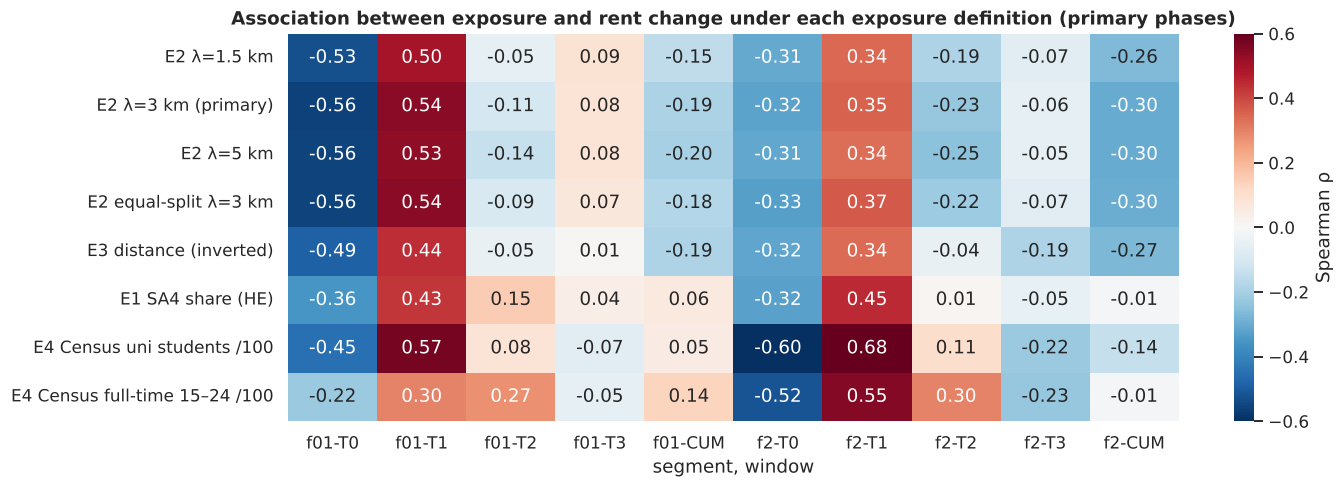

In [57]:
EXPOSURE_DEFS = {**EXPOSURE_VARIANTS, "E4 Census uni students /100": "E4", "E4 Census full-time 15–24 /100": "E4_ft1524"}
PRIMARY_DEF = {"E2": "E2 λ=3 km (primary)", "E4": "E4 Census uni students /100"}
CAMPUS_DEFS = list(EXPOSURE_VARIANTS)

def rho_grid(chg_df: pd.DataFrame, elig_df: pd.DataFrame, trans: dict = TRANS) -> pd.DataFrame:
    """Spearman ρ between each exposure definition and the change, for every segment × window."""
    ex = elig_df.set_index("poa")
    exp_cols = {k: (ex[v] * (-1 if v == "E3_dist_major_km" else 1)) for k, v in EXPOSURE_DEFS.items()}
    out = {}
    for seg in SEGS:
        for tr in trans:
            d = chg_df[(chg_df.seg == seg) & (chg_df.trans == tr)].set_index("poa")
            out[(seg, tr)] = {k: stats.spearmanr(e.loc[d.index], d.chg).statistic for k, e in exp_cols.items()}
    return pd.DataFrame(out)

grid = rho_grid(chg, elig)
grid_flow = rho_grid(chg_flow, elig, TRANS_FLOW)
fig, ax = plt.subplots(figsize=(13, 4.6))
sns.heatmap(grid, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, ax=ax, cbar_kws={"label": "Spearman ρ"})
ax.set_title("Association between exposure and rent change under each exposure definition (primary phases)")
ax.set_xlabel("segment, window"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [58]:
def agreement_share(g: pd.DataFrame, primary: str, cells: list, others: list | None = None, thr: float = 0.10) -> float:
    """Share of the other definitions whose ρ has the primary's sign (and |ρ| ≥ thr), averaged over cells where |ρ_primary| ≥ thr."""
    others = others or [k for k in g.index if k != primary]
    shares = []
    for c in cells:
        p = g.loc[primary, c]
        if abs(p) < thr:
            continue
        o = g.loc[others, c]
        shares.append(((np.sign(o) == np.sign(p)) & (o.abs() >= thr)).mean())
    return float(np.mean(shares)) if shares else np.nan

def loo_stability(chg_df: pd.DataFrame, tier_col: str = "tier", windows: list = PRIMARY_WINDOWS, seg: str = "f01") -> tuple[float, pd.DataFrame]:
    """Share of (window, dropped corridor) runs where the High−Low gap keeps its full-sample sign."""
    rows = []
    for tr in windows:
        d = chg_df[(chg_df.seg == seg) & (chg_df.trans == tr)]
        full = tier_gap_arrays(d.chg.to_numpy(), d[tier_col].astype(str).to_numpy())
        for sa3 in d.sa3.unique():
            dd = d[d.sa3 != sa3]
            g = tier_gap_arrays(dd.chg.to_numpy(), dd[tier_col].astype(str).to_numpy())
            rows.append({"window": tr, "dropped": sa3, "gap": g, "same_sign": np.sign(g) == np.sign(full) if np.isfinite(g) else np.nan})
    out = pd.DataFrame(rows)
    return (float(out.same_sign.dropna().astype(float).mean()) if len(out) else np.nan), out

def grade_from(n_sig: int, agree: float, loo: float) -> str:
    """Apply the grade thresholds stated at the top of the notebook."""
    if n_sig >= 2 and agree >= 0.8 and loo >= 0.9:
        return "A"
    if n_sig >= 1 and agree >= 0.6:
        return "B"
    return "C"

def grading_inputs(res_df, grid_df, chg_df, tiering: str, labels: dict) -> dict:
    """Revised rule: agreement (all other definitions) and leave-one-out, both in the post-closure windows whose interval excludes zero."""
    tcol, _ = TIERINGS[tiering]
    prim = res_df[(res_df.tiering == tiering) & (res_df.seg == "f01") & res_df.trans.isin(PRIMARY_WINDOWS)]
    sig = prim.loc[prim.excludes_0, "trans"].tolist()
    agree = agreement_share(grid_df, PRIMARY_DEF[tiering], [("f01", t) for t in sig])
    loo = loo_stability(chg_df, tcol, sig)[0] if sig else np.nan
    return {"windows whose interval excludes 0": ", ".join(labels[t] for t in sig) or "none", "n windows": len(sig),
            "sign agreement": agree, "leave-one-out": loo, "grade": grade_from(len(sig), agree, loo)}

def original_rule(res_df, grid_df, chg_df) -> dict:
    """Rule as first fixed: E2 tiers, campus definitions only, averaged over all post-closure windows with |ρ| ≥ 0.10."""
    prim = res_df[(res_df.tiering == "E2") & (res_df.seg == "f01") & res_df.trans.isin(PRIMARY_WINDOWS)]
    agree = agreement_share(grid_df, PRIMARY_DEF["E2"], [("f01", t) for t in PRIMARY_WINDOWS], [c for c in CAMPUS_DEFS if c != PRIMARY_DEF["E2"]])
    loo = loo_stability(chg_df, "tier", PRIMARY_WINDOWS)[0]
    n_sig = int(prim.excludes_0.sum())
    return {"n windows": n_sig, "sign agreement": agree, "leave-one-out": loo, "grade": grade_from(n_sig, agree, loo)}

res_flow = tier_results(chg_flow, TRANS_FLOW, full=False)
SCHEMES = {"students present (primary)": (res, grid, chg, TRANS_LABEL), "visas granted (sensitivity)": (res_flow, grid_flow, chg_flow, TRANS_LABEL_FLOW)}
grade_rows = []
for scheme, (r_, g_, c_, lab_) in SCHEMES.items():
    for name in TIERINGS:
        grade_rows.append({"phases": scheme, "tiers": name, "rule": "revised", **grading_inputs(r_, g_, c_, name, lab_)})
    grade_rows.append({"phases": scheme, "tiers": "E2", "rule": "original", **original_rule(r_, g_, c_)})
grade_tab = pd.DataFrame(grade_rows)
display(grade_tab.style.format({"sign agreement": "{:.0%}", "leave-one-out": "{:.0%}"}, na_rep="–"))

,phases,tiers,rule,windows whose interval excludes 0,n windows,sign agreement,leave-one-out,grade
0,students present (primary),E2,revised,closure → recovery,1,100%,100%,B
1,students present (primary),E4,revised,closure → recovery,1,100%,100%,B
2,students present (primary),E2,original,–,1,60%,87%,B
3,visas granted (sensitivity),E2,revised,closure → recovery,1,100%,100%,B
4,visas granted (sensitivity),E4,revised,"closure → recovery, recovery → correction",2,64%,100%,B
5,visas granted (sensitivity),E2,original,–,1,80%,100%,B


## 6.7 Evidence grade and finding for RQ3

The table below lists every window and segment under the four specifications (two exposure measures × two phase definitions); `*` marks an interval
that excludes zero. A result is a **finding** only if it holds under all four. Rows carry the primary phase names; under the visa-grant phases the
third and fourth windows are recovery → correction and correction → plateau & decline, and the cumulative window ends in Jul 2024–Sep 2026.

In [59]:
allres = pd.concat([res.assign(phases="students present"), res_flow.assign(phases="visas granted")], ignore_index=True)
robust = allres.groupby(["seg", "trans"]).apply(lambda g: bool(g.excludes_0.all() and np.sign(g.gap_pp).nunique() == 1)).rename("finding")
mat = (allres.assign(cell=lambda d: d.gap_pp.map(fx) + np.where(d.excludes_0, "*", ""))
       .pivot_table(index=["seg", "trans"], columns=["phases", "tiering"], values="cell", aggfunc="first"))
mat[("finding", "")] = robust.map({True: "yes", False: ""})
mat = mat.reindex([(s, t) for s in SEGS + ["h34"] for t in TRANS])
mat.index = [f"{SEG_LABEL[s]} | {TRANS_LABEL[t]}" for s, t in mat.index]
mat

phases                                             students present         visas granted         finding
tiering                                                          E2      E4            E2      E4        
Studio / 1-bedroom flats | 2018 → closure                    -10.7*   -6.6*        -10.4*   -7.8*     yes
Studio / 1-bedroom flats | closure → recovery                +10.0*  +10.0*         +8.8*   +8.7*     yes
Studio / 1-bedroom flats | recovery → plateau                  -3.7    +0.0          +0.9   +1.8*        
Studio / 1-bedroom flats | plateau → decline                   +0.0    +0.0          -0.8    -0.2        
Studio / 1-bedroom flats | 2018 → decline (cumu...             -2.7    -0.5         -2.7*    +1.1        
2-bedroom flats | 2018 → closure                               -4.5   -9.8*          -4.5  -11.2*        
2-bedroom flats | closure → recovery                           +3.4  +10.1*         +3.0*   +8.2*        
2-bedroom flats | recovery → plateau                          -2.8*    +1.2          -2.8    +2.2        
2-bedroom flats | plateau → decline                            -0.9    -1.4         -1.7*    -1.2        
2-bedroom flats | 2018 → decline (cumulative)                 -4.2*    -1.7         -4.2*    -1.6        
3–4 bedroom houses | 2018 → closure                           -7.8*   -8.3*         -7.6*   -8.8*     yes
3–4 bedroom houses | closure → recovery                        +0.0   +3.1*          -0.1    +2.1        
3–4 bedroom houses | recovery → plateau                        -1.1    +2.5          -0.1    +1.8        
3–4 bedroom houses | plateau → decline                         -1.2    -1.2         -2.5*    -0.8        
3–4 bedroom houses | 2018 → decline (cumulative)              -6.5*   -7.8*         -7.3*   -5.3*     yes

In [60]:
GRADE_BY = grade_tab[(grade_tab.rule == "revised") & grade_tab.phases.str.contains("primary")].set_index("tiers").grade
GRADE = max(GRADE_BY)                                          # 'C' > 'B' > 'A': the lower grade wins
GRADE_TEXT = {
    "A": "a stable association across windows and exposure definitions, which justifies taking the corridor results forward for investigation (still not evidence of cause)",
    "B": "a signal in at least one window that depends on the window or on how exposure is defined, so it should be reported as tentative",
    "C": "no pattern that can be distinguished from the common market trend at this resolution; this is a finding about the limits of the data, not proof that there is no effect",
}
def fmt_p(p: float) -> str:
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

SCHEME_NAME = {"students present (primary)": "student-stock", "visas granted (sensitivity)": "visa-grant"}
WINDOW_ANY = {**TRANS_LABEL, "CUM": "2018 → latest phase, cumulative"}     # CUM ends in a different phase under each definition
found = [(s, t) for s in SEGS + ["h34"] for t in TRANS if robust.get((s, t), False)]
found_txt = "; ".join(f"{SEG_LABEL[s].lower()}, {WINDOW_ANY[t]} ({fx(allres[(allres.seg == s) & (allres.trans == t)].gap_pp.min())} to "
                      f"{fx(allres[(allres.seg == s) & (allres.trans == t)].gap_pp.max())} pp)" for s, t in found) or "none"
cum_rng = allres[(allres.seg == "f01") & (allres.trans == "CUM")]
prim_E2 = res[(res.tiering == "E2") & (res.seg == "f01") & res.trans.isin(PRIMARY_WINDOWS)]
bul = "\n".join(f"- **{TRANS_LABEL[r.trans]}:** High − Low gap {ci_txt(r)} with E2 tiers (Spearman ρ = {r.rho:+.2f}, naive permutation {fmt_p(r.p_perm_naive)}); "
                f"with E4 tiers {ci_txt(rr.loc[('E4', 'f01', r.trans)])}." for r in prim_E2.itertuples())
gt = grade_tab.assign(primary=grade_tab.phases.str.contains("primary")).set_index(["primary", "tiers", "rule"])
rev_E2, rev_E4 = gt.loc[(True, "E2", "revised")], gt.loc[(True, "E4", "revised")]
orig_p, orig_f = gt.loc[(True, "E2", "original")], gt.loc[(False, "E2", "original")]
flow_grades = {t: gt.loc[(False, t, "revised"), "grade"] for t in TIERINGS}
ct = contrast.set_index(["tiering", "trans"])
n_intervals = len(res)
LATER_QUIET = not res[(res.seg == "f01") & res.trans.isin(["T2", "T3"])].excludes_0.any()
PATTERN = (f"A dip-and-rebound: during the 2021 closure the High tier's studio/1BR rents fell {abs(rr.loc[('E2', 'f01', 'T0'), 'gap_pp']):.1f} pp more than the "
           f"Low tier's ({abs(rr.loc[('E4', 'f01', 'T0'), 'gap_pp']):.1f} pp with Census tiers), and in the recovery they rose "
           f"{rr.loc[('E2', 'f01', 'T1'), 'gap_pp']:.1f} pp more ({rr.loc[('E4', 'f01', 'T1'), 'gap_pp']:.1f} pp)."
           + (" Houses in the same postcodes shared the dip" if DIP_SHARED else "")
           + ((" but much less of the rebound." if DIP_SHARED else " Houses shared much less of the rebound.") if REBOUND_FLATS else ("." if DIP_SHARED else ""))
           + (" No High − Low difference has opened since (recovery → plateau, plateau → decline)." if LATER_QUIET else
              " Later windows show differences under some specifications; see the table above."))
md(f"**Key finding – RQ3 (studio/1BR flats; {int(prim_E2.n_High.iloc[0])} High-tier and {int(prim_E2.n_Low.iloc[0])} Low-tier postcodes).**\n\n{PATTERN}\n\n"
   f"**Results that hold under both exposure measures and both phase definitions:** {found_txt}.\n\n"
   f"Post-closure windows used for the grade:\n\n{bul}\n\n"
   f"- **Exposure definitions:** in the windows with a signal ({rev_E2['windows whose interval excludes 0']} for E2 tiers; "
   f"{rev_E4['windows whose interval excludes 0']} for E4 tiers), {rev_E2['sign agreement']:.0%} and {rev_E4['sign agreement']:.0%} of the other definitions agree in sign.\n"
   f"- **Leave-one-corridor-out:** the sign holds in {rev_E2['leave-one-out']:.0%} (E2) and {rev_E4['leave-one-out']:.0%} (E4) of runs.\n"
   f"- **Small flats versus 2BR flats (closure → recovery):** {fx(ct.loc[('E2', 'T1'), 'gap_pp (f01 − f2)'])} pp "
   f"[{fx(ct.loc[('E2', 'T1'), 'lo'])}, {fx(ct.loc[('E2', 'T1'), 'hi'])}] with E2 tiers and {fx(ct.loc[('E4', 'T1'), 'gap_pp (f01 − f2)'])} pp "
   f"[{fx(ct.loc[('E4', 'T1'), 'lo'])}, {fx(ct.loc[('E4', 'T1'), 'hi'])}] with E4 tiers: "
   + ({2: "the rebound was larger for the smallest flats under both measures.",
       1: "the rebound was larger for the smallest flats under one measure only, so specificity to small flats is not robust.",
       0: "the rebound is not shown to be specific to the smallest flats."}[int(ct.loc[[("E2", "T1"), ("E4", "T1")]].pipe(lambda d: (d.lo > 0).sum()))]) + "\n"
   f"- **Cumulative change (2018 → latest phase), studio/1BR:** {fx(cum_rng.gap_pp.min())} to {fx(cum_rng.gap_pp.max())} pp across the four specifications, "
   f"with the interval excluding zero in {int(cum_rng.excludes_0.sum())} of 4. It is reported as description only."
   + (f" For 3–4BR houses, by contrast, the High tier grew less than the Low tier over the whole period under every specification "
      f"({fx(allres[(allres.seg == 'h34') & (allres.trans == 'CUM')].gap_pp.min())} to {fx(allres[(allres.seg == 'h34') & (allres.trans == 'CUM')].gap_pp.max())} pp), "
      "so over 2018–2026 the high-exposure areas did not see faster rent growth." if ("h34", "CUM") in found and
      (allres[(allres.seg == "h34") & (allres.trans == "CUM")].gap_pp < 0).all() else "") + "\n\n"
   f"**Evidence grade: {GRADE}** (E2 tiers: {GRADE_BY['E2']}; E4 tiers: {GRADE_BY['E4']}; with the visa-grant phases: {flow_grades['E2']} and {flow_grades['E4']}). "
   f"This means {GRADE_TEXT[GRADE]}. Under the rule as first fixed, the grade is {orig_p.grade} with the primary phases (sign agreement "
   f"{orig_p['sign agreement']:.0%} against a 60% threshold, because the no-signal windows are averaged in) and {orig_f.grade} with the visa-grant phases "
   f"({orig_f['sign agreement']:.0%}, the first version's result)"
   + (", so the revision does not change the grade." if orig_p.grade == GRADE == orig_f.grade else
      "; the grades differ, so the conservative reading is the lower of them.")
   + "".join(f" With the {SCHEME_NAME[row.phases]} phases and {row.tiers} tiers, {row['n windows']} windows exclude zero "
             f"({row['windows whose interval excludes 0']}), enough windows for A, but only {row['sign agreement']:.0%} of the other definitions agree in sign "
             "across them (A needs 80%): the extra window is not robust to how exposure is defined."
             for _, row in grade_tab[(grade_tab.rule == "revised") & (grade_tab["n windows"] >= 2) & (grade_tab.grade != "A")].iterrows())
   + "\n\n"
   + f"*Caution:* the table at the start of section 6 alone holds {n_intervals} intervals at the 90% level, so a few would exclude zero by chance; only effects "
   "that repeat under every specification are treated as findings. A closure-then-rebound pattern is what a shock to campus-linked demand would "
   "produce, but equally what a shock to inner-city demand in general (workplaces, tourism, border-related moves) would produce."
   + (" The placebo shows that the dip was area-wide; these data cannot separate the two explanations for the rebound." if DIP_SHARED else ""))

**Key finding – RQ3 (studio/1BR flats; 39 High-tier and 39 Low-tier postcodes).**

A dip-and-rebound: during the 2021 closure the High tier's studio/1BR rents fell 10.7 pp more than the Low tier's (6.6 pp with Census tiers), and in the recovery they rose 10.0 pp more (10.0 pp). Houses in the same postcodes shared the dip but much less of the rebound. No High − Low difference has opened since (recovery → plateau, plateau → decline).

**Results that hold under both exposure measures and both phase definitions:** studio / 1-bedroom flats, 2018 → closure (-10.7 to -6.6 pp); studio / 1-bedroom flats, closure → recovery (+8.7 to +10.0 pp); 3–4 bedroom houses, 2018 → closure (-8.8 to -7.6 pp); 3–4 bedroom houses, 2018 → latest phase, cumulative (-7.8 to -5.3 pp).

Post-closure windows used for the grade:

- **closure → recovery:** High − Low gap +10.0 pp [+7.3, +12.8] with E2 tiers (Spearman ρ = +0.54, naive permutation p < 0.001); with E4 tiers +10.0 pp [+6.2, +13.3].
- **recovery → plateau:** High − Low gap -3.7 pp [-5.4, +1.5] with E2 tiers (Spearman ρ = -0.11, naive permutation p = 0.242); with E4 tiers +0.0 pp [-3.4, +3.0].
- **plateau → decline:** High − Low gap +0.0 pp [-1.0, +2.0] with E2 tiers (Spearman ρ = +0.08, naive permutation p = 0.381); with E4 tiers +0.0 pp [-1.2, +1.5].

- **Exposure definitions:** in the windows with a signal (closure → recovery for E2 tiers; closure → recovery for E4 tiers), 100% and 100% of the other definitions agree in sign.
- **Leave-one-corridor-out:** the sign holds in 100% (E2) and 100% (E4) of runs.
- **Small flats versus 2BR flats (closure → recovery):** +2.6 pp [+0.7, +5.4] with E2 tiers and -0.4 pp [-3.2, +1.4] with E4 tiers: the rebound was larger for the smallest flats under one measure only, so specificity to small flats is not robust.
- **Cumulative change (2018 → latest phase), studio/1BR:** -2.7 to +1.1 pp across the four specifications, with the interval excluding zero in 1 of 4. It is reported as description only. For 3–4BR houses, by contrast, the High tier grew less than the Low tier over the whole period under every specification (-7.8 to -5.3 pp), so over 2018–2026 the high-exposure areas did not see faster rent growth.

**Evidence grade: B** (E2 tiers: B; E4 tiers: B; with the visa-grant phases: B and B). This means a signal in at least one window that depends on the window or on how exposure is defined, so it should be reported as tentative. Under the rule as first fixed, the grade is B with the primary phases (sign agreement 60% against a 60% threshold, because the no-signal windows are averaged in) and B with the visa-grant phases (80%, the first version's result), so the revision does not change the grade. With the visa-grant phases and E4 tiers, 2 windows exclude zero (closure → recovery, recovery → correction), enough windows for A, but only 64% of the other definitions agree in sign across them (A needs 80%): the extra window is not robust to how exposure is defined.

*Caution:* the table at the start of section 6 alone holds 30 intervals at the 90% level, so a few would exclude zero by chance; only effects that repeat under every specification are treated as findings. A closure-then-rebound pattern is what a shock to campus-linked demand would produce, but equally what a shock to inner-city demand in general (workplaces, tourism, border-related moves) would produce. The placebo shows that the dip was area-wide; these data cannot separate the two explanations for the rebound.

# 7. RQ4 – Which corridors warrant further investigation?

**Research question.** Which corridors show rent growth above the Low-exposure benchmark, consistently across segments and windows, with enough bonds to trust?

For each corridor (SA3) with at least 3 eligible postcodes, the median change is compared with the **median of the Low tier** (E2) in the same segment and window.
A corridor is *consistent* when it beats the benchmark in at least 5 of the 6 comparisons (2 segments × windows T1–T3).

In [61]:
bench = (chg[(chg.tier == "Low")].groupby(["seg", "trans"]).chg.median().rename("bench").reset_index())
cc = chg[chg.seg.isin(SEGS) & chg.trans.isin(PRIMARY_WINDOWS)].merge(bench, on=["seg", "trans"])
cc = cc.groupby(["sa3", "seg", "trans"]).agg(med=("chg", "median"), bench=("bench", "first"), pcs=("poa", "nunique")).reset_index()
cc["above"] = cc.med > cc.bench
n_bonds = (panel[panel.seg.isin(SEGS) & panel.group.notna()].groupby("sa3").size().rename("bonds_f01_f2"))
corr_tab = (cc.groupby("sa3").agg(postcodes=("pcs", "max"), above_of_6=("above", "sum"), avg_gap_pp=("med", "mean"))
            .join(cc.assign(g=cc.med - cc.bench).groupby("sa3").g.mean().rename("avg_gap_vs_low_pp"))
            .join(elig.groupby("sa3").E2_rows_l3.mean().rename("mean_E2"))
            .join(elig.groupby("sa3").E4.mean().rename("mean_E4"))
            .join(n_bonds))
corr_tab = corr_tab[corr_tab.postcodes >= 3].drop(columns="avg_gap_pp")
E2_EXPOSED = elig.loc[elig.tier == "High", "E2_rows_l3"].min()          # lower bound of the High tier
corr_tab["exposed"] = corr_tab.mean_E2 >= E2_EXPOSED
corr_tab["consistent"] = (corr_tab.above_of_6 >= 5) & (corr_tab.bonds_f01_f2 >= 2000)
corr_tab["candidate"] = corr_tab.consistent & corr_tab.exposed
corr_tab = corr_tab.sort_values(["above_of_6", "avg_gap_vs_low_pp"], ascending=False)
corr_tab.round(1)

,postcodes,above_of_6,avg_gap_vs_low_pp,mean_E2,mean_E4,bonds_f01_f2,exposed,consistent,candidate
sa3,,,,,,,,,
Parramatta,4,5,2.20,6.00,6.00,41121,False,True,False
Canterbury,4,4,3.40,4.10,5.90,19360,False,False,False
Ryde - Hunters Hill,5,4,3.20,10.30,7.60,38750,False,False,False
Hurstville,4,4,2.10,1.70,6.70,14819,False,False,False
Kogarah - Rockdale,6,4,2.00,5.90,6.10,33333,False,False,False
Chatswood - Lane Cove,5,4,1.60,12.50,6.30,38764,False,False,False
Ku-ring-gai,6,4,-0.40,4.50,7.20,8889,False,False,False
Eastern Suburbs - South,6,3,3.10,34.10,9.50,48408,True,False,False
Auburn,3,3,2.60,4.10,7.40,29012,False,False,False


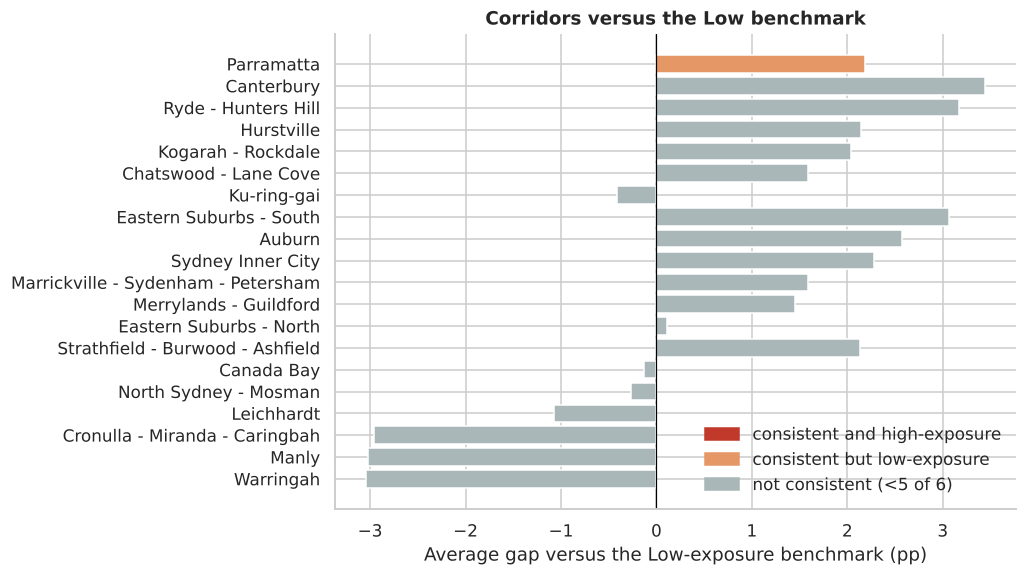

In [62]:
fig, ax = plt.subplots(figsize=(9.5, 5.4))
colors = np.select([corr_tab.candidate, corr_tab.consistent], ["#c0392b", "#e59866"], default="#aab7b8")
ax.barh(corr_tab.index, corr_tab.avg_gap_vs_low_pp, color=colors)
ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis()
ax.set_xlabel("Average gap versus the Low-exposure benchmark (pp)")
ax.set_title("Corridors versus the Low benchmark")
ax.legend(handles=[Patch(color="#c0392b", label="consistent and high-exposure"), Patch(color="#e59866", label="consistent but low-exposure"),
                   Patch(color="#aab7b8", label="not consistent (<5 of 6)")], frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## 7.1 Finding for RQ4

In [63]:
flagged = corr_tab[corr_tab.candidate].index.tolist()
exposed_names = corr_tab[corr_tab.exposed].index.tolist()
low_consistent = corr_tab[corr_tab.consistent & ~corr_tab.exposed]
if flagged and GRADE in ("A", "B"):
    head = f"With evidence grade {GRADE}, the high-exposure corridors that consistently beat the Low benchmark are candidates for deeper investigation: **{', '.join(flagged)}**."
elif flagged:
    head = f"The grade is C, so this is a descriptive ranking only. High-exposure corridors that beat the Low benchmark in at least 5 of 6 comparisons: **{', '.join(flagged)}**."
else:
    others = "; ".join(f"{n} (mean E2 {low_consistent.loc[n, 'mean_E2']:.1f})" for n in low_consistent.index) or "none"
    did = ("No corridor did." if low_consistent.empty else
           f"The only corridor that did is a low-exposure one: {others}." if len(low_consistent) == 1 else
           f"The corridors that did are low-exposure ones: {others}.")
    head = (f"None of the {len(exposed_names)} high-exposure corridors ({', '.join(exposed_names)}) beat the Low-exposure benchmark in at least 5 of 6 comparisons. "
            f"{did} Fast rent growth is therefore not specific to campus areas.")
md("**Key finding – RQ4.** " + head + " Corridors are ranked by how rents moved relative to low-exposure flat markets; the ranking says nothing about why.")

**Key finding – RQ4.** None of the 6 high-exposure corridors (Eastern Suburbs - South, Sydney Inner City, Marrickville - Sydenham - Petersham, Eastern Suburbs - North, North Sydney - Mosman, Leichhardt) beat the Low-exposure benchmark in at least 5 of 6 comparisons. The only corridor that did is a low-exposure one: Parramatta (mean E2 6.0). Fast rent growth is therefore not specific to campus areas. Corridors are ranked by how rents moved relative to low-exposure flat markets; the ranking says nothing about why.

# 8. Robustness

Beyond the checks in 6.6, several further choices could change the picture: the minimum bonds per cell, how the tiers are drawn, whether the City of
Sydney's own postcodes drive the result, how the phases are defined, outliers inside each cell, and the exact duplicates kept in 2.1.

**Outliers by group.** Applying the IQR rule within each year across all postcodes would again flag mostly inner-city rents (the problem with the global rule in
2.1). The rule is therefore applied **within each postcode × segment × phase cell**, the group whose median enters the comparison: it flags only bonds that
are unusual for their own local market, which are the only outliers that could move a cell median.

In [64]:
def primary_summary(chg_df: pd.DataFrame, label: str, tier_col: str = "tier", expo_col: str = "E2_rows_l3", windows=("T0", "T1", "T2", "T3")) -> dict:
    """Median High−Low gap and ρ for studio/1BR in each window, for a given set of changes."""
    out = {"scenario": label}
    for tr in windows:
        d = chg_df[(chg_df.seg == "f01") & (chg_df.trans == tr)]
        out[f"gap {tr}"] = tier_gap_arrays(d.chg.to_numpy(), d[tier_col].astype(str).to_numpy())
        out[f"ρ {tr}"] = stats.spearmanr(d[expo_col], d.chg).statistic if len(d) > 10 else np.nan
    out["postcodes (T1)"] = len(chg_df[(chg_df.seg == "f01") & (chg_df.trans == "T1")])
    return out

def changes_from(pn: pd.DataFrame, phase_col: str = "phase", trans: dict = TRANS, min_n: int = MIN_N) -> pd.DataFrame:
    """Rebuild the postcode × segment changes from a (filtered) bond panel."""
    cell = (pn[pn.seg.isin(SEGS + ["h34"])].groupby(["poa", "seg", phase_col]).agg(n=("rent", "size"), med=("rent", "median"))
            .reset_index().rename(columns={phase_col: "phase"}))
    return build_changes(cell, min_n, trans).merge(elig[ELIG_COLS], on="poa", how="inner")

an = panel[panel.seg.isin(SEGS + ["h34"]) & panel.poa.isin(elig.poa)].copy()
an["lr"] = np.log(an.rent)
cell_q = an.groupby(["poa", "seg", "phase"]).lr
q1, q3 = cell_q.transform(lambda s: s.quantile(0.25)), cell_q.transform(lambda s: s.quantile(0.75))
an["iqr_out"] = (an.lr < q1 - 1.5 * (q3 - q1)) | (an.lr > q3 + 1.5 * (q3 - q1))
f01y = an[an.seg == "f01"]
yq1 = f01y.groupby(f01y.date.dt.year).rent.transform(lambda s: s.quantile(0.25))
yq3 = f01y.groupby(f01y.date.dt.year).rent.transform(lambda s: s.quantile(0.75))
year_rule = (f01y.rent < yq1 - 1.5 * (yq3 - yq1)) | (f01y.rent > yq3 + 1.5 * (yq3 - yq1))
print(f"Within-cell IQR flags {an.iqr_out.mean():.1%} of bonds in the analysed segments; a within-year rule on studio/1BR rents would flag "
      f"{year_rule[f01y.city_of_sydney].mean():.1%} of City of Sydney bonds against {year_rule[~f01y.city_of_sydney].mean():.1%} elsewhere.")
dedup = an.drop_duplicates(subset=["date", "poa", "dwelling", "bedrooms", "rent"])

scen = []
for mn in (30, 60, 100):                                     # (a) minimum bonds per cell
    scen.append(primary_summary(build_changes(cell_pd, mn).merge(elig[ELIG_COLS], on="poa"), f"min {mn} bonds per cell" + (" (primary)" if mn == MIN_N else "")))
scen.append(primary_summary(chg[~chg.city_of_sydney], "excluding City of Sydney postcodes"))          # (b)
e4q = elig.copy(); q = e4q.E2_rows_l3.quantile([0.25, 0.75])                                         # (c) quartile tiers instead of terciles
e4q["tier"] = np.select([e4q.E2_rows_l3 <= q.iloc[0], e4q.E2_rows_l3 >= q.iloc[1]], ["Low", "High"], default="Mid")
scen.append(primary_summary(chg.drop(columns="tier").merge(e4q[["poa", "tier"]], on="poa"), "top vs bottom quartile tiers"))
scen.append(primary_summary(chg, "Census tiers (E4) instead of E2", "tier_E4", "E4"))                   # (d)
scen.append(primary_summary(chg_flow, "visa-grant phases (BP0015)†"))                                 # (e)
scen.append(primary_summary(changes_from(an[~an.iqr_out]), f"IQR trimming within each cell ({an.iqr_out.mean():.1%} of bonds)"))   # (f)
scen.append(primary_summary(changes_from(dedup), f"exact duplicates removed ({1 - len(dedup) / len(an):.1%} of bonds)"))              # (g)
pd.DataFrame(scen).round(2)

Within-cell IQR flags 2.8% of bonds in the analysed segments; a within-year rule on studio/1BR rents would flag 3.9% of City of Sydney bonds against 1.5% elsewhere.


,scenario,gap T0,ρ T0,gap T1,ρ T1,gap T2,ρ T2,gap T3,ρ T3,postcodes (T1)
0,min 30 bonds per cell (primary),-10.67,-0.56,9.95,0.54,-3.73,-0.11,-0.03,0.08,117
1,min 60 bonds per cell,-11.59,-0.60,10.02,0.50,-3.30,-0.09,0.39,0.11,110
2,min 100 bonds per cell,-11.08,-0.58,10.54,0.51,-3.30,-0.14,0.29,0.10,94
3,excluding City of Sydney postcodes,-9.82,-0.51,8.83,0.49,-2.70,-0.05,-0.08,0.08,104
4,top vs bottom quartile tiers,-10.55,-0.56,11.27,0.54,-4.18,-0.11,-0.23,0.08,117
5,Census tiers (E4) instead of E2,-6.65,-0.45,9.95,0.57,0.00,0.08,-0.04,-0.07,117
6,visa-grant phases (BP0015)†,-10.38,-0.56,8.80,0.55,0.87,0.05,-0.78,-0.12,117
7,IQR trimming within each cell (2.8% of bonds),-10.80,-0.55,9.12,0.53,-2.18,-0.08,-0.20,0.03,117
8,exact duplicates removed (6.8% of bonds),-10.59,-0.57,8.93,0.52,-3.74,-0.10,-0.03,0.08,117


† Under the visa-grant phases the windows are Jan–Nov 2021 → Dec 2021–Jul 2023 (T1), → Aug 2023–Jun 2024 (T2) and → Jul 2024–Sep 2026 (T3).

**How much can the robustness checks prove?** The campus-based variants (λ values, equal-split weights, distance, SA4 share) all derive from the same
campus locations, which is why they agree so closely. Agreement across them shows the result does not hinge on a tuning choice, but it does
**not** test the underlying assumption that proximity to a campus is a good proxy for where students rent. The Census tiers are the check that does,
because they rank postcodes by where students live.

# 9. Context: other explanations

Rent differences between areas can have other sources. These descriptive checks do not adjust the results above.

## 9.1 Market structure at baseline

High-exposure postcodes are also more flat-dominated and dearer in 2018, which is why changes (not levels) are compared. The tables check whether the
comparison tiers look alike on those dimensions, under each tiering.

In [65]:
bal = pd.concat({name: (elig.groupby(tcol, observed=True)
                        .agg(postcodes=("poa", "size"), flat_share_2018=("flat_share_2018", "median"), med_f01_2018=("med_f01_2018", "median"),
                             med_f2_2018=("med_f2_2018", "median"), median_dist_km=("E3_dist_major_km", "median"),
                             renter_share_pct=("renter_share_pct", "median"), city_of_sydney=("city_of_sydney", "sum")))
                 for name, (tcol, _) in TIERINGS.items()}, names=["tiers", "tier"])
bal

postcodes  flat_share_2018  med_f01_2018  med_f2_2018  median_dist_km  renter_share_pct  city_of_sydney
tiers tier                                                                                                         
E2    Low          39             0.62        410.00       490.00            8.08             54.92               0
      Mid          39             0.78        490.00       590.00            4.10             60.70               0
      High         39             0.76        530.00       710.00            1.55             69.57              13
E4    Low          39             0.66        482.50       595.00            5.05             56.06               0
      Mid          39             0.77        460.00       580.00            3.83             59.50               3
      High         39             0.76        497.50       620.00            1.85             69.12              10

## 9.2 Supply of student accommodation in the City of Sydney

The City of Sydney's June Housing Audit counts student accommodation rooms inside its boundary. It is context for the end user's own area and does not
enter any test.

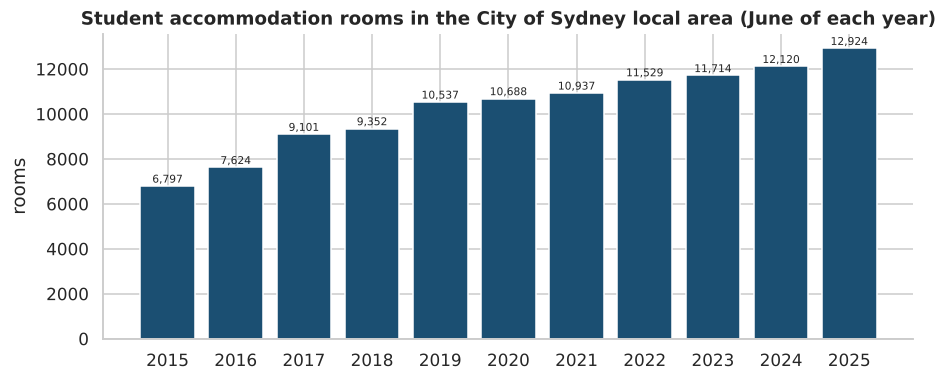

Student rooms rose from 6,797 (June 2015) to 12,924 (June 2025), +90% (+23% since 2019). Three limits on reading this series: (1) these are **rooms inside the City of Sydney boundary**, counted each June, not beds across Greater Sydney; (2) they are **not divided by student numbers**, which cover a different area and date; (3) they are **not drawn against the rent index**, because two trends on one chart invite a causal reading the data cannot support. Most students rent privately (about 77% of student visa holders nationally at the 2021 Census, ABS ACTEID, see `DATA_ENRICHMENT_ASSESSMENT.md`), which is why the analysis studies private new leases.

In [66]:
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.bar(audit.audit_year, audit.student_rooms, color="#1b4f72")
for x_, v_ in zip(audit.audit_year, audit.student_rooms):
    ax.text(x_, v_ + 150, f"{v_:,}", ha="center", fontsize=7)
ax.set_xticks(audit.audit_year)
ax.set_ylabel("rooms")
ax.set_title("Student accommodation rooms in the City of Sydney local area (June of each year)")
plt.show()

first_, last_ = audit.iloc[0], audit.iloc[-1]
since19 = last_.student_rooms / audit.set_index("audit_year").loc[2019, "student_rooms"] - 1
md(f"Student rooms rose from {first_.student_rooms:,} (June {first_.audit_year}) to {last_.student_rooms:,} (June {last_.audit_year}), "
   f"{last_.student_rooms / first_.student_rooms - 1:+.0%} ({since19:+.0%} since 2019). Three limits on reading this series: (1) these are **rooms inside the City of "
   "Sydney boundary**, counted each June, not beds across Greater Sydney; (2) they are **not divided by student numbers**, which cover a different area and "
   "date; (3) they are **not drawn against the rent index**, because two trends on one chart invite a causal reading the data cannot support. Most students "
   "rent privately (about 77% of student visa holders nationally at the 2021 Census, ABS ACTEID, see `DATA_ENRICHMENT_ASSESSMENT.md`), which is why the "
   "analysis studies private new leases.")

## 9.3 What these data cannot test

Housing supply and short-term letting are two obvious alternative explanations. Both were examined and moved to `appendix_context_da_airbnb.ipynb`,
because neither can be used as a control:
- **Development applications** are *proposals* from ten sampled months (January and July of 2022–2026), many of them for no new dwelling, and they
  differ little across the comparator tiers (the City of Sydney has the fewest).
- **Inside Airbnb** is a single snapshot (17 September 2026), so it cannot be lined up with rent changes over 2021–2026.

The honest answer to "what about supply and Airbnb?" is therefore: examined, not testable with the data available.

# 10. Overall findings, recommendations and limitations

## 10.1 Overall findings

In [67]:
n_pos = int((corr.median_chg_f01 > 0).sum())
corridor_line = (f"High-exposure corridors that consistently beat the Low benchmark: {', '.join(flagged)}." if flagged
                 else "No high-exposure corridor consistently beat the Low-exposure benchmark, so the corridor ranking does not point to campus areas as a group.")
t3 = {t: rr.loc[(t, "f01", "T3")] for t in TIERINGS}
weaker = any(r.excludes_0 and r.gap_pp < 0 for r in t3.values())
decline_head = ("Rents near campuses have weakened relative to comparable areas as student numbers fall" if weaker
                else "No sign yet of weaker rents near campuses as student numbers fall")
md(f"""
1. **A shared cycle dominates.** New-lease rents for flats fell during the 2021 closure and then rose strongly everywhere (RQ1). Differences between exposure groups in the cumulative change are small relative to this common movement.
2. **Growth was widespread.** Cumulative studio/1BR rent change from 2018 to the decline phase was positive in {n_pos} of {len(corr)} corridors (RQ2).
3. **Association with exposure: evidence grade {GRADE}.** {PATTERN} The only results that hold under both exposure measures and both phase definitions are: {found_txt}. (RQ3)
4. **{decline_head}.** In the plateau → decline window the High − Low gap is {ci_txt(t3['E2'])} with E2 tiers and {ci_txt(t3['E4'])} with E4 tiers, over about 15 months of decline.
5. **Pre-COVID trends were near-parallel.** DCJ medians show the High and Low tiers within about {max_abs:.1f} pp a year of each other in 2018–2019{", with the gap opening after the border closed and closing by late 2022" if opened and closed else ""}.
6. **Seasonality.** {SEASON_TEXT}
7. **Corridors.** {corridor_line} (RQ4)
""")


1. **A shared cycle dominates.** New-lease rents for flats fell during the 2021 closure and then rose strongly everywhere (RQ1). Differences between exposure groups in the cumulative change are small relative to this common movement.
2. **Growth was widespread.** Cumulative studio/1BR rent change from 2018 to the decline phase was positive in 20 of 20 corridors (RQ2).
3. **Association with exposure: evidence grade B.** A dip-and-rebound: during the 2021 closure the High tier's studio/1BR rents fell 10.7 pp more than the Low tier's (6.6 pp with Census tiers), and in the recovery they rose 10.0 pp more (10.0 pp). Houses in the same postcodes shared the dip but much less of the rebound. No High − Low difference has opened since (recovery → plateau, plateau → decline). The only results that hold under both exposure measures and both phase definitions are: studio / 1-bedroom flats, 2018 → closure (-10.7 to -6.6 pp); studio / 1-bedroom flats, closure → recovery (+8.7 to +10.0 pp); 3–4 bedroom houses, 2018 → closure (-8.8 to -7.6 pp); 3–4 bedroom houses, 2018 → latest phase, cumulative (-7.8 to -5.3 pp). (RQ3)
4. **No sign yet of weaker rents near campuses as student numbers fall.** In the plateau → decline window the High − Low gap is +0.0 pp [-1.0, +2.0] with E2 tiers and +0.0 pp [-1.2, +1.5] with E4 tiers, over about 15 months of decline.
5. **Pre-COVID trends were near-parallel.** DCJ medians show the High and Low tiers within about 1.4 pp a year of each other in 2018–2019, with the gap opening after the border closed and closing by late 2022.
6. **Seasonality.** Studio/1BR rents in High-exposure postcodes sit +4.1% relative to trend in February, against +0.4% in Low-exposure postcodes; for 2BR flats the figures are +4.9% and -0.7%. The High-minus-Low February–March gap was positive in 4 of 5 years for studio/1BR and 5 of 5 years for 2BR flats.
7. **Corridors.** No high-exposure corridor consistently beat the Low-exposure benchmark, so the corridor ranking does not point to campus areas as a group. (RQ4)


## 10.2 Recommendations for the City of Sydney

The wording below follows the evidence grade computed above.

In [68]:
if GRADE == "A" and flagged:
    recs = [f"Prioritise the flagged corridors ({', '.join(flagged)}) for deeper investigation, for example by asking education providers and student-accommodation operators for occupancy and waiting-list data.",
            "Describe the finding in briefings as a **stable association**, not a cause."]
elif GRADE in ("A", "B"):
    recs = ["Treat the pattern as tentative. It rests on the rebound after the 2021 closure"
            + ("; the dip before it also hit houses in the same postcodes, so the dip reflects inner-city conditions in general." if DIP_SHARED else "."),
            "Use the wording 'a temporary signal that cannot yet be separated from the inner-city cycle' in briefings and advocacy letters.",
            "Test the February seasonal lead directly: ask student-accommodation operators and education providers for lease-start dates and term-address counts by suburb.",
            "Do not use these results to rank corridors for student-related action; no high-exposure corridor consistently beat the low-exposure benchmark."
            if not flagged else f"Treat {', '.join(flagged)} as candidates for a closer look only, not as a ranking for action.",
            "Keep monitoring the decline phase: student numbers have been falling since mid-2025, and "
            + ("rents near campuses have already weakened relative to comparable areas." if weaker else
               "so far rents near campuses have not weakened relative to comparable areas.")]
else:
    recs = ["Do not use these results to rank corridors for student-related action; the data cannot separate exposure from the common cycle at postcode resolution.",
            "Ask for the data that would sharpen the question: student numbers or term addresses by suburb, occupancy and rents in purpose-built student accommodation, and weekly rather than period-median rent series.",
            "Use the descriptive results (RQ1–RQ2) for context: new-lease flat rents recovered from the 2021 trough and now sit well above 2018 in every corridor."]
recs.append("Request bond-level files for 2019–2020: the DCJ medians show near-parallel trends before COVID, but only bond-level data would allow the same tests as for the other years.")
md("\n".join(f"{i}. {r}" for i, r in enumerate(recs, 1)))

1. Treat the pattern as tentative. It rests on the rebound after the 2021 closure; the dip before it also hit houses in the same postcodes, so the dip reflects inner-city conditions in general.
2. Use the wording 'a temporary signal that cannot yet be separated from the inner-city cycle' in briefings and advocacy letters.
3. Test the February seasonal lead directly: ask student-accommodation operators and education providers for lease-start dates and term-address counts by suburb.
4. Do not use these results to rank corridors for student-related action; no high-exposure corridor consistently beat the low-exposure benchmark.
5. Keep monitoring the decline phase: student numbers have been falling since mid-2025, and so far rents near campuses have not weakened relative to comparable areas.
6. Request bond-level files for 2019–2020: the DCJ medians show near-parallel trends before COVID, but only bond-level data would allow the same tests as for the other years.

## 10.3 Limitations

- **Exposure is modelled, not observed.** Campus weights are an allocation of SA4 enrolments by CRICOS course-location rows; the Department of Education file records place of study (not residence) for a single year (2025). The Census measure records where students live but counts domestic students too and was taken during the 2021 border closure.
- **Coarse geography.** Rent is known only by postcode, and distances use postcode-area centroids (about 1 km resolution). UNSW and Macquarie were mapped to neighbouring postcodes because ABS has no postcode area for their institutional postcodes.
- **New leases only.** Bond lodgements capture rents at the start of a tenancy. They say nothing about rents paid by existing tenants, and do not identify tenants (students or otherwise).
- **Observational data.** Neighbouring postcodes share conditions, the campus-based variants derive from the same campuses, and the grade rules are descriptive. Nothing here establishes cause.
- **Time coverage.** 2019–2020 bond rows are missing; DCJ fills those years only as medians (1- and 2-bedroom flats; hidden cells more frequent in Low-tier postcodes). The 2018 file comes from a data.nsw mirror; its medians match the official DCJ series, but its provenance should still be confirmed.
- **Phases are working labels.** They come from the national count of student visa holders present (all sectors, all states), read at quarter-ends; the visa-grant phases are a check, not an independent measure. The 2021 closure phase also contains Sydney's mid-2021 lockdown.
- **Many comparisons.** Two exposure measures × three segments × five windows under two phase definitions; at the 90% level some intervals exclude zero by chance, which is why only results that repeat under every specification are called findings. The grading rules were revised once (6.7), and the original rule gives the same grade.
- **Median-based phase comparisons** blend a phase's within-period movement into its level; phases of different lengths are therefore only roughly comparable.

## 10.4 Conclusion

In [69]:
flat_found = [t for s, t in found if s == "f01"]
md("This analysis examined whether new-lease rents in Sydney's flat market differ by exposure to higher-education students. Rents moved together through a "
   "common cycle. "
   + (f"The clear difference for small flats is in {' and '.join(TRANS_LABEL[t] for t in flat_found)}, which repeats under both exposure measures and both "
      "phase definitions" if flat_found else "No difference for small flats repeats under every specification")
   + ("; the closure dip also hit houses in the same areas" if DIP_SHARED else "")
   + ("; and no difference has opened since, including after student numbers began to fall." if LATER_QUIET else ".")
   + f" With evidence grade {GRADE}, the result is intentionally calibrated: it tells the Council where to look and how firmly to say it, and where the "
   "available data stop being able to answer.")

This analysis examined whether new-lease rents in Sydney's flat market differ by exposure to higher-education students. Rents moved together through a common cycle. The clear difference for small flats is in 2018 → closure and closure → recovery, which repeats under both exposure measures and both phase definitions; the closure dip also hit houses in the same areas; and no difference has opened since, including after student numbers began to fall. With evidence grade B, the result is intentionally calibrated: it tells the Council where to look and how firmly to say it, and where the available data stop being able to answer.

## 10.5 Future development
- Obtain student numbers by suburb or term address (state or campus level), so that exposure can be observed rather than modelled.
- Obtain bond-level files for 2019–2020 to test pre-existing trends with the same method as the other years.
- Geocode campuses and use the postcode-level 2026 Census to normalise by renter households.
- Request purpose-built student accommodation occupancy and rents from operators.

---
*Reproducibility: all inputs are in `data/raw/`, derived tables in `data/processed/` (the enrichment tables in `processed/extracted/` come from
`00_data_extraction_overview.ipynb`), and the build scripts in `data/scripts/` (run in numerical order).*